# SupervisedLDA

This notebook contains the code for model building and evaluation on Roberta data, Distilroberta data and Distilroberta Mitch Data

# Import Libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import KFold, train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import KFold, train_test_split, cross_val_score
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, auc, precision_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.linear_model import SGDClassifier

# Load the training datasets for roberta, distilroberta and distilroberta mitch, the test dataset and target group

In [2]:
# Load feature datasets
X_train_roberta = pd.read_csv('X_train_roberta.csv')
X_test_roberta = pd.read_csv('X_test_roberta.csv')

X_train_distilroberta = pd.read_csv('X_train_distilroberta.csv')
X_test_distilroberta = pd.read_csv('X_test_distilroberta.csv')

X_train_distilroberta_mitch = pd.read_csv('X_train_distilroberta_mitch.csv')
X_test_distilroberta_mitch = pd.read_csv('X_test_distilroberta_mitch.csv')

# Load target datasets
y_train = pd.read_csv('y_train.csv')
y_test = pd.read_csv('y_test.csv')

target_group_train = pd.read_csv('target_train.csv')
target_group_test = pd.read_csv('target_test.csv')


# Split training data into new training data and validation data

In [3]:
from sklearn.model_selection import train_test_split

# Generate indices for the train-validation split
train_indices, val_indices = train_test_split(
    range(len(X_train_roberta)), test_size=0.2, random_state=42
)

# Use these indices to index each dataset
X_train_roberta_train = X_train_roberta.iloc[train_indices]
X_val_roberta = X_train_roberta.iloc[val_indices]

X_train_distilroberta_train = X_train_distilroberta.iloc[train_indices]
X_val_distilroberta = X_train_distilroberta.iloc[val_indices]

X_train_distilroberta_mitch_train = X_train_distilroberta_mitch.iloc[train_indices]
X_val_distilroberta_mitch = X_train_distilroberta_mitch.iloc[val_indices]

y_train_train = y_train.iloc[train_indices]
y_val = y_train.iloc[val_indices]

target_group_train_split = target_group_train.iloc[train_indices]
target_group_val_split = target_group_train.iloc[val_indices]

# Now you have:
# - Training sets: X_train_roberta_train, X_train_distilroberta_train, X_train_distilroberta_mitch_train, y_train_train
# - Validation sets: X_val_roberta, X_val_distilroberta, X_val_distilroberta_mitch, y_val


# Evaluation Performance Metrics 

## Precision@k

In [4]:
import numpy as np

def calculate_precision_at_k(y_true, y_pred_proba, k=20):
  """Calculates precision@k for binary classification.

  Args:
    y_true: True labels.
    y_pred_proba: Predicted probabilities.
    k: Number of top predictions to consider.

  Returns:
    Precision@k value.
  """

  # Rank predictions by probability
  indices = np.argsort(y_pred_proba)[::-1]

  # Apply threshold and select top k
  y_pred = (y_pred_proba[indices] > 0.5).astype(int)
  y_pred_top_k = y_pred[:k]

  # Retrieve actual labels
  y_true_top_k = y_true[indices][:k]

  # Calculate numerator and denominator
  numerator = np.sum(y_pred_top_k * y_true_top_k)
  denominator = np.sum(y_pred_top_k)

  # Calculate precision@k
  if denominator > 0:
    precision_at_k = numerator / denominator
  else:
    precision_at_k = 0

  return precision_at_k

## Average precision @k

In [5]:
import numpy as np
from sklearn.metrics import average_precision_score

def average_precision_top_k(y_true, y_pred_proba, k=20):
  """Calculates average precision for the top k predictions.

  Args:
    y_true: True binary labels.
    y_score: Target scores.
    k: Number of top predictions to consider.

  Returns:
    Average precision value.
  """

  # Filter top k predictions
  indices = np.argsort(y_pred_proba)[::-1]
  y_true_top_k = y_true[indices][:k]
  y_score_top_k = y_pred_proba[indices][:k]

  # Calculate average precision
  ap = average_precision_score(y_true_top_k, y_score_top_k)

  return ap

## NDCG@K

In [6]:
def calculate_ndcg_at_k(true_labels, predicted_scores, k):
    """Calculates Normalized Discounted Cumulative Gain (NDCG) at k.

    Args:
        true_labels: A list or NumPy array of true labels.
        predicted_scores: A list or NumPy array of predicted scores.
        k: The number of top predictions to consider.

    Returns:
        The NDCG at k.
    """

    if len(true_labels) == 0:
        return 0

    # Ensure k does not exceed the number of predicted scores
    k = min(k, len(predicted_scores))

    def dcg(relevance, k):
        relevance = np.array(relevance)[:k]  # Take top k relevant items
        return np.sum((2 ** relevance - 1) / np.log2(np.arange(2, len(relevance) + 2)))

    # Sort indices by descending predicted scores
    indices = np.argsort(predicted_scores)[::-1][:k]

    # Get top k true labels and calculate DCG
    top_k_true_labels = true_labels[indices]
    dcg_k = dcg(top_k_true_labels, k)

    # Calculate Ideal Discounted Cumulative Gain (IDCG)
    ideal_labels = np.sort(true_labels)[::-1][:k]
    idcg_k = dcg(ideal_labels, k)

    # Calculate NDCG
    ndcg_k = dcg_k / idcg_k if idcg_k > 0 else 0

    return ndcg_k

## Confusion Matrix Plot

In [7]:
def compute_and_display_confusion_matrix(y_true, y_pred_proba, group=None):
    """
    Compute and display the confusion matrix for a given target group.

    Parameters:
    - y_true: True labels for the test set or validation fold.
    - y_pred_proba: Predicted probability scores from the model.
    - group: The target group for labeling purposes.
    
    Returns:
    - None
    """
    y_pred = (y_pred_proba > 0.5).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    
    # Display confusion matrix as a heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', cbar=False, 
                xticklabels=['Predicted Negative', 'Predicted Positive'], 
                yticklabels=['Actual Negative', 'Actual Positive'])
    plt.title(f'Confusion Matrix for {group}' if group else 'Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

## Precision Score

In [8]:
def calculate_precision_score(y_true, y_pred_proba):
    """Calculates precision score for binary classification.

    Args:
        y_true: True binary labels.
        y_pred_proba: Predicted probability scores.
        average: Method for averaging precision across classes.
        pos_label: Positive class label.

    Returns:
        Precision score.
    """

    y_pred = (y_pred_proba > 0.5).astype(int)
    precision = precision_score(y_true, y_pred)
    return precision

## ROC Curve

In [9]:
def plot_roc_curve(y_true, y_pred_proba, group=None):
    """Plots the ROC curve for binary classification for each target group.

    Args:
        y_true: True binary labels.
        y_pred_proba: Predicted probability scores.
        group: The target group for labeling purposes.
    """
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba, pos_label=1)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {group}' if group else 'Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.show()

## Function for evaluating model on each target group

In [13]:
# Function to evaluate model on validation data for each target group and return metrics in a DataFrame
def evaluate_model_by_group(X_val, y_val,text_column, target_group_val, model, k=20):
    """Evaluates the model on validation data, calculates various metrics for each target group, and returns a DataFrame."""
    
    # Get predicted probabilities for the positive class
    y_pred_proba = model.predict_proba(X_val[text_column])[:, 1]
    
    # Create a DataFrame with predicted probabilities, true labels, and target groups
    results_df = pd.DataFrame({
        'y_true': y_val.values.ravel(),
        'y_pred_proba': y_pred_proba,
        'target_group': target_group_val.values.ravel()
    })

    # Prepare a list to hold the metrics for each group
    metrics_list = []

    # Calculate precision@k and other metrics for each target group
    for group in results_df['target_group'].unique():
        group_df = results_df[results_df['target_group'] == group]
        
        # Calculate precision@k, average precision@k, ndcg@k, and other metrics
        precision_at_k = calculate_precision_at_k(group_df['y_true'].values, group_df['y_pred_proba'].values, k=k)
        average_precision_at_k = average_precision_top_k(group_df['y_true'].values, group_df['y_pred_proba'].values, k=k)
        ndcg_at_k = calculate_ndcg_at_k(group_df['y_true'].values, group_df['y_pred_proba'].values, k=k)
        precision_score_value = precision_score(group_df['y_true'].values, (group_df['y_pred_proba'].values > 0.5).astype(int),
                                               zero_division=0)

        # Plot ROC curve and confusion matrix for the group
        plot_roc_curve(group_df['y_true'].values, group_df['y_pred_proba'].values, group)
        compute_and_display_confusion_matrix(group_df['y_true'].values, group_df['y_pred_proba'].values, group)

        # Store the results in a dictionary
        metrics_dict = {
            'target_group': group,
            'precision_at_k': precision_at_k,
            'average_precision_at_k': average_precision_at_k,
            'ndcg_at_k': ndcg_at_k,
            'precision_score': precision_score_value
        }
        
        # Append the metrics for this group to the list
        metrics_list.append(metrics_dict)

    # Convert the list of metrics dictionaries to a DataFrame
    metrics_df = pd.DataFrame(metrics_list)
    
    return metrics_df, results_df


# Model Building

## Baseline Model

In [10]:
def lda_sgd_pipeline(X_train, y_train, text_column):
    """
    Creates a pipeline for LDA + SGDClassifier and performs cross-validation.

    Args:
        X_train: Training features (pandas DataFrame).
        y_train: Training labels.
        text_column: Column containing text data.
        n_topics: Number of topics for LDA (default: 10).
        k_folds: Number of folds for cross-validation (default: 5).
        random_state: Random seed (default: 42).

    Returns:
        A tuple containing the trained pipeline, average precision score, and its standard deviation.
    """

    # Define the pipeline
    pipeline = Pipeline([
        ('vectorizer', CountVectorizer(stop_words='english')),  # Vectorize text data
        ('lda', LatentDirichletAllocation(n_components=10, random_state=42)),  # LDA for topics
        ('clf', SGDClassifier(random_state=42, loss='log_loss', max_iter=1000))]) # SGDClassifier for binary classif.
    
    # Perform K-fold cross-validation
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    precision_scores = cross_val_score(pipeline, X_train[text_column], y_train.values.ravel(), cv=kf, scoring='precision')

    # Calculate the average and std deviation of precision across all folds
    precision_mean = np.mean(precision_scores)
    precision_std = np.std(precision_scores)
    
    pipeline.fit(X_train[text_column], y_train.values.ravel())

    return pipeline, precision_mean, precision_std


### Baseline Model on Roberta Data

In [11]:
baseline_model_robertaA, _, _ = lda_sgd_pipeline(X_train_roberta_train, y_train_train, 'text_roberta')

#### Test for overfitting by comparing validation and training set scores

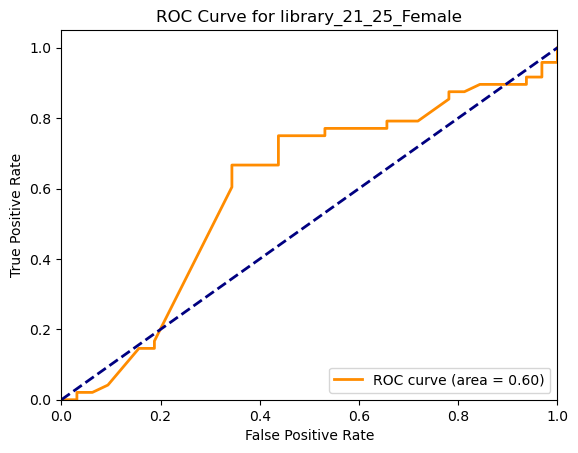

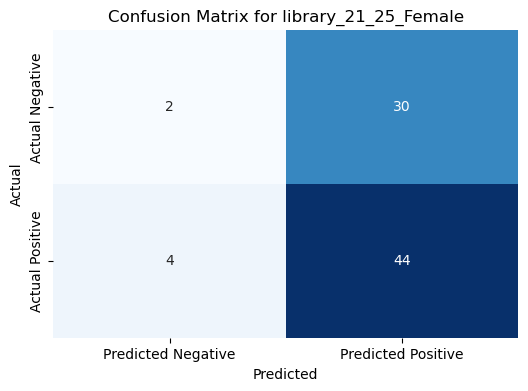

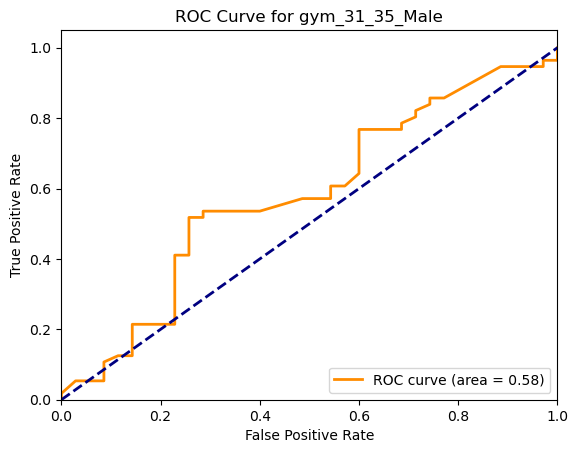

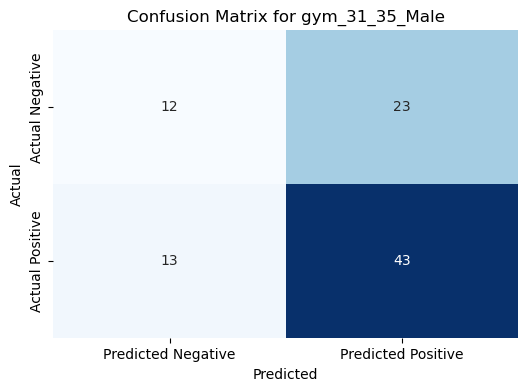

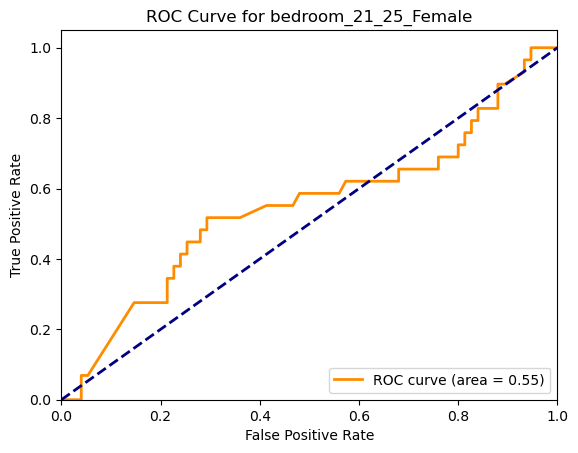

...

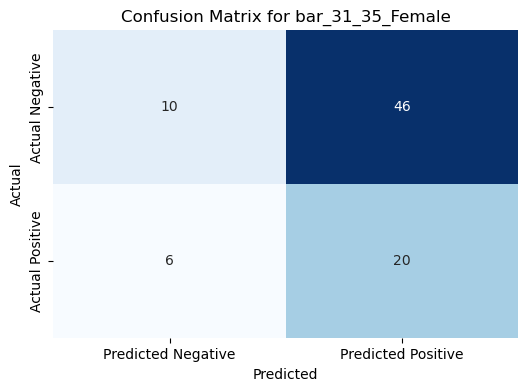

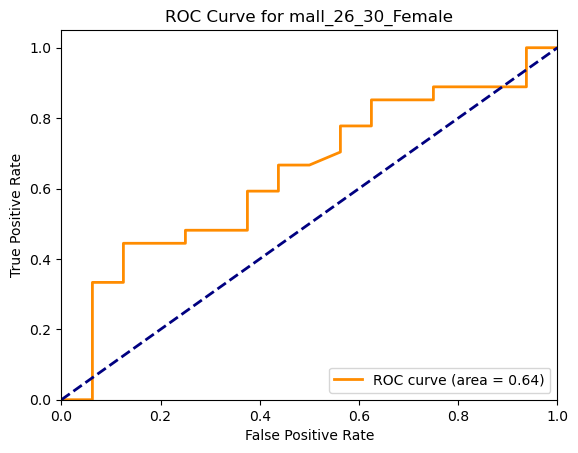

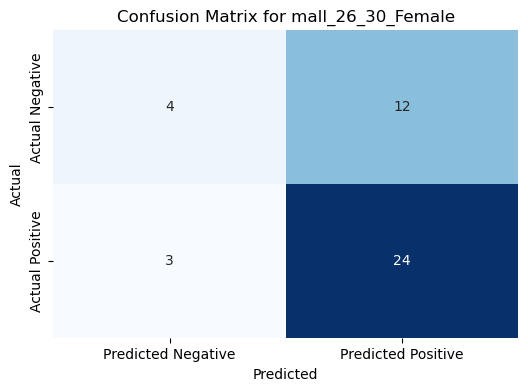

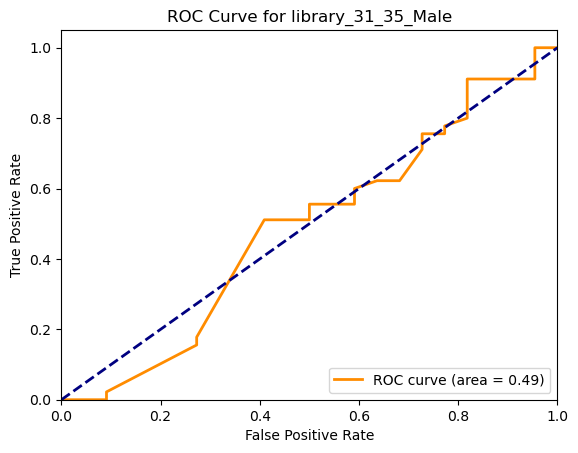

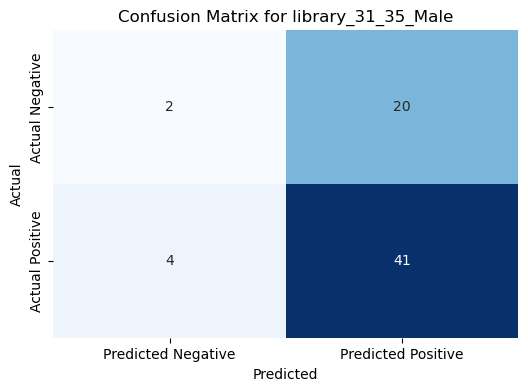

In [14]:
# Evaluate the model
metrics_roberta_valA, results_roberta_valA = evaluate_model_by_group(X_val_roberta, y_val, 'text_roberta', target_group_val_split, baseline_model_robertaA, k=20)


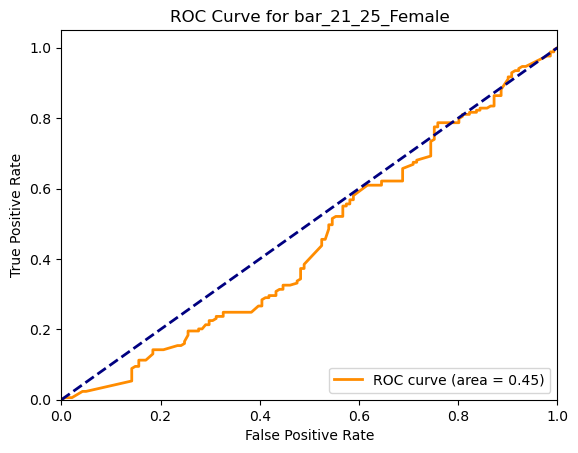

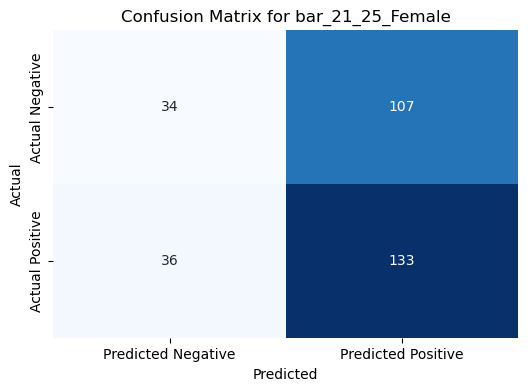

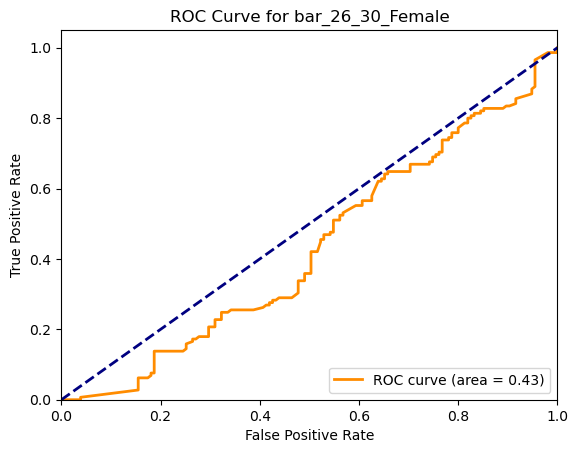

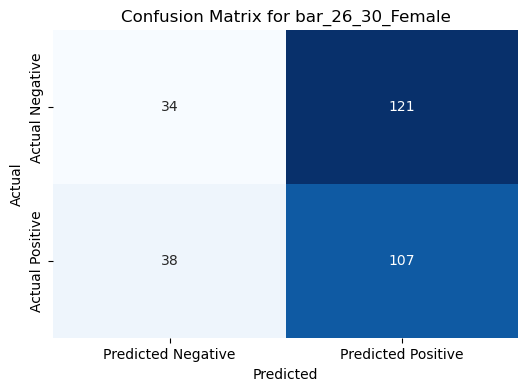

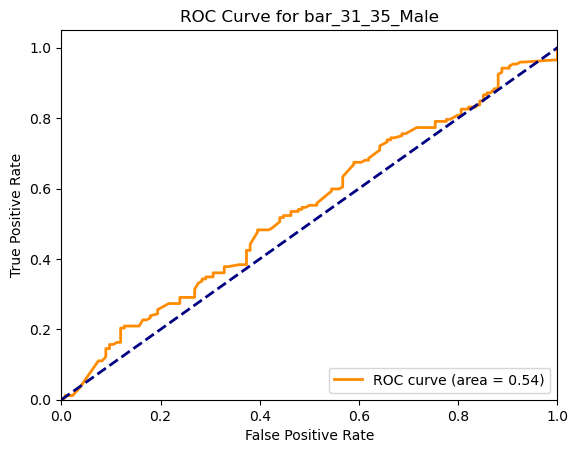

...

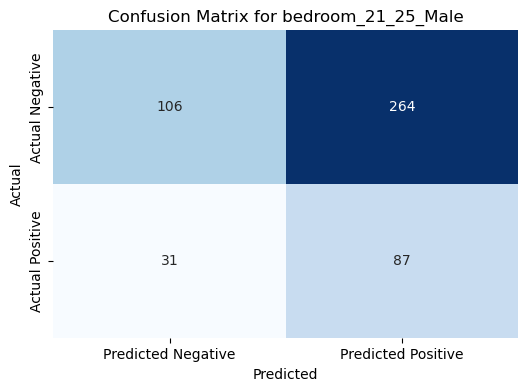

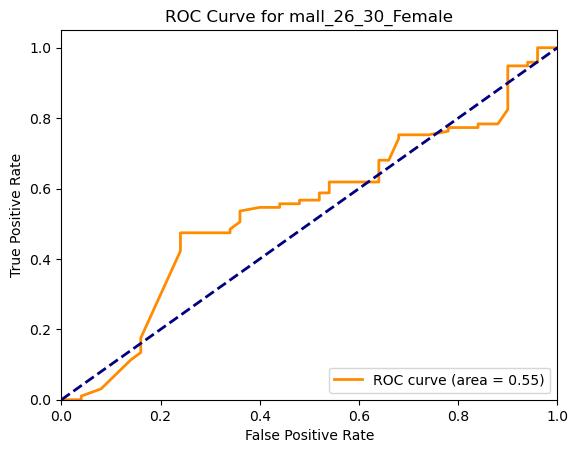

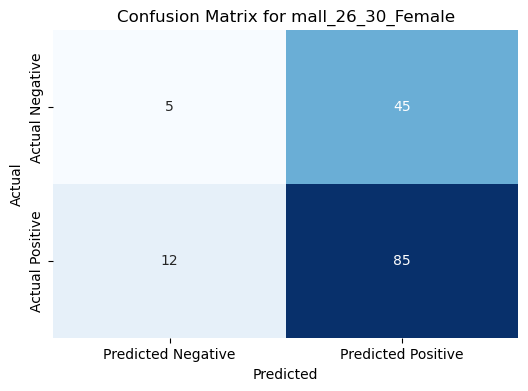

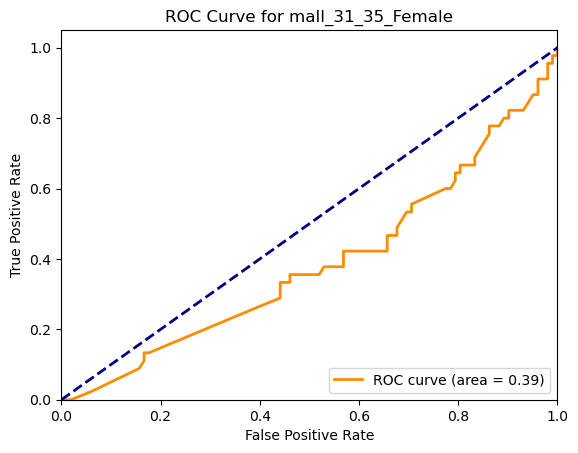

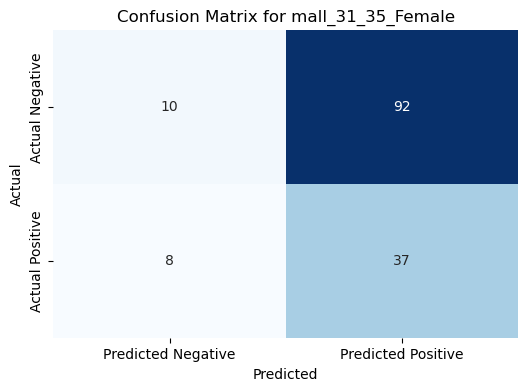

In [15]:
metrics_roberta_trainA, results_roberta_trainA  = evaluate_model_by_group(X_train_roberta_train, y_train_train, 'text_roberta', target_group_train_split, baseline_model_robertaA, k=20)


In [152]:
print('Mean Precision score for Baseline Model on Roberta Training Set:',metrics_roberta_trainA['precision_score'].mean())
print('Mean Precision score for Baseline Model on Roberta Validation Set:',metrics_roberta_valA['precision_score'].mean())

Mean Precision score for Baseline Model on Roberta Training Set: 0.5697916666666667
Mean Precision score for Baseline Model on Roberta Validation Set: 0.56875


* The baseline model generalised well for roberta data

### Second Model with Penalty L2 regularisation

While the baseline model generalised for Roberta, in 6.2, it overfitted for distilroberta data and distilroberta mitch data.

This second model was created to stop the overfitting in distilroberta and distilroberta mitch, however, for comparison it was applied to roberta

In [19]:
def lda_sgd_pipeline2(X_train, y_train, text_column):
    """
    Creates a pipeline for LDA + SGDClassifier and performs cross-validation.

    Args:
        X_train: Training features (pandas DataFrame).
        y_train: Training labels.
        text_column: Column containing text data.
        n_topics: Number of topics for LDA (default: 10).
        k_folds: Number of folds for cross-validation (default: 5).
        random_state: Random seed (default: 42).

    Returns:
        A tuple containing the trained pipeline, average precision score, and its standard deviation.
    """

    # Define the pipeline
    pipeline = Pipeline([
        ('vectorizer', CountVectorizer(stop_words='english')),  # Step 1: Vectorize text data
        ('lda', LatentDirichletAllocation(n_components=10, random_state=42)),  # Step 2: LDA for topics
        ('clf', SGDClassifier(random_state=42, loss='log_loss', penalty='l2', max_iter=1000, tol=1e-3))])
    
    # Perform K-fold cross-validation
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    precision_scores = cross_val_score(pipeline, X_train[text_column], y_train.values.ravel(), cv=kf, scoring='precision')

    # Calculate the average and std deviation of precision across all folds
    precision_mean = np.mean(precision_scores)
    precision_std = np.std(precision_scores)
    
    pipeline.fit(X_train[text_column], y_train.values.ravel())

    return pipeline, precision_mean, precision_std


In [20]:
model_robertaB, _, _ = lda_sgd_pipeline2(X_train_roberta_train, y_train_train, 'text_roberta')

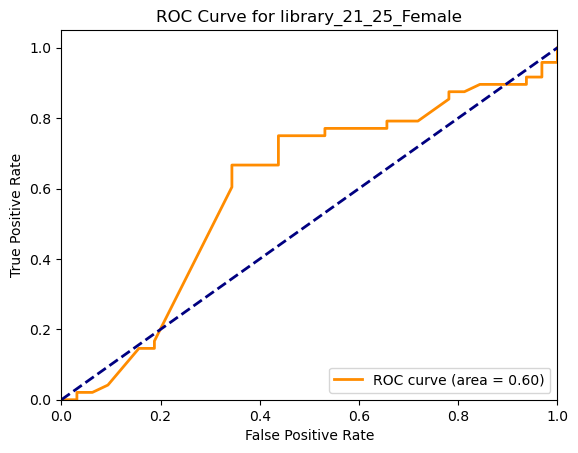

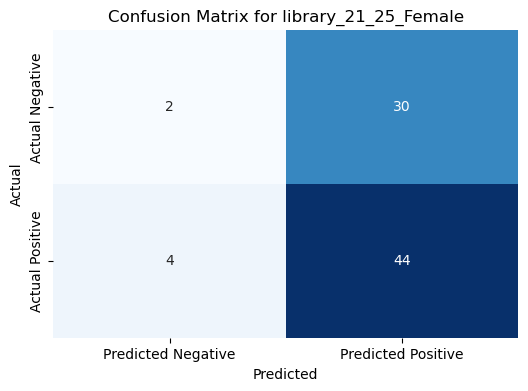

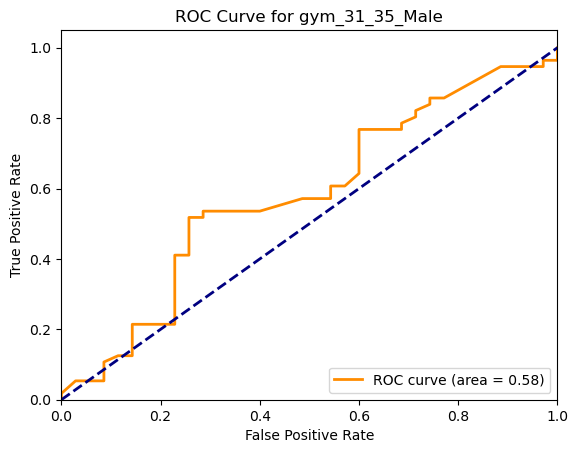

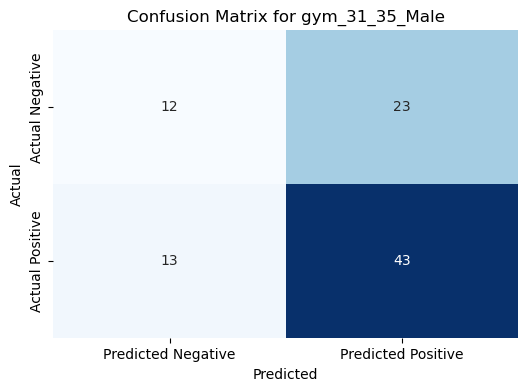

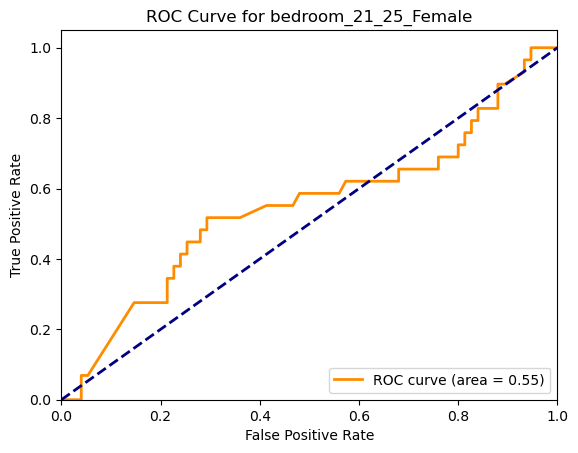

...

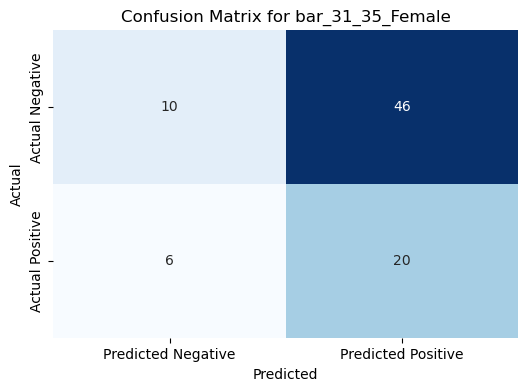

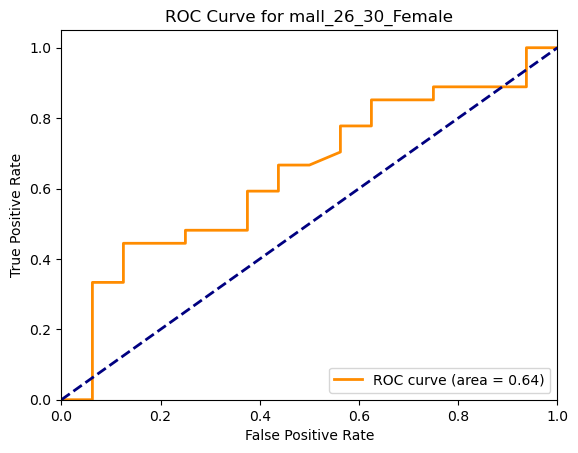

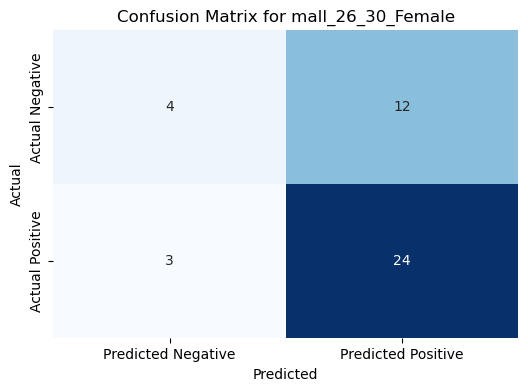

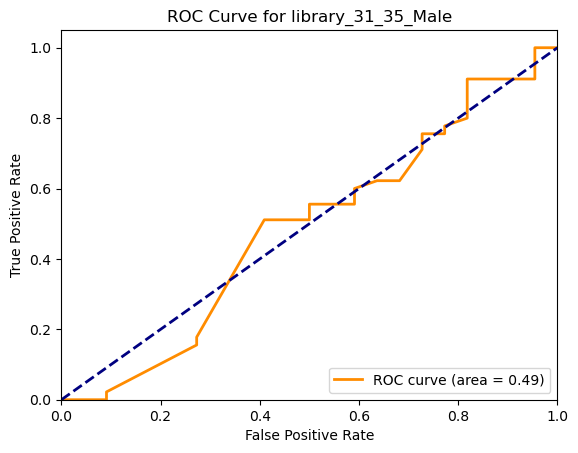

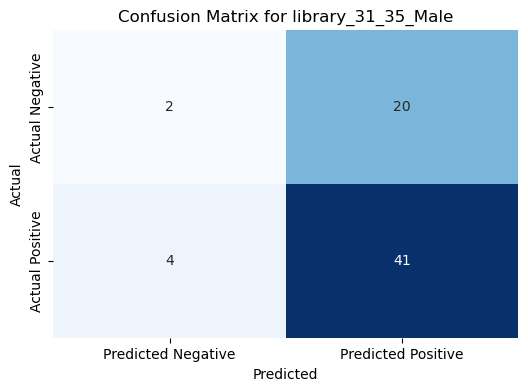

In [21]:
metrics_roberta_valB, results_roberta_valB = evaluate_model_by_group(X_val_roberta, y_val, 'text_roberta', target_group_val_split, model_robertaB, k=20)


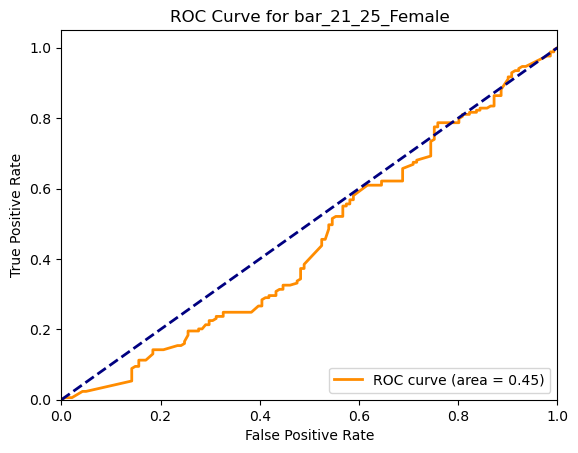

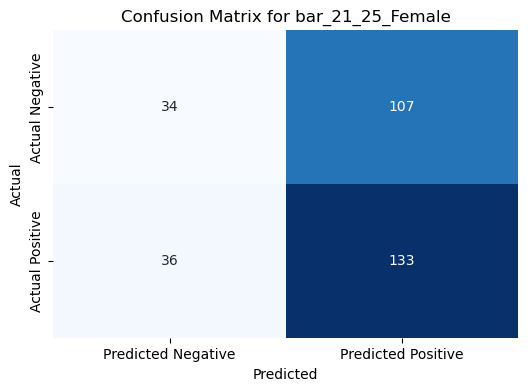

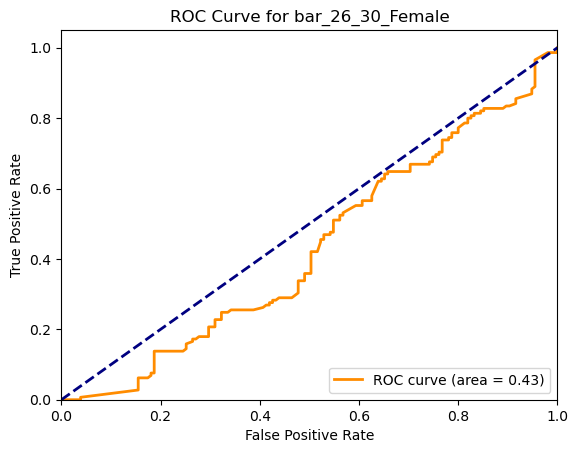

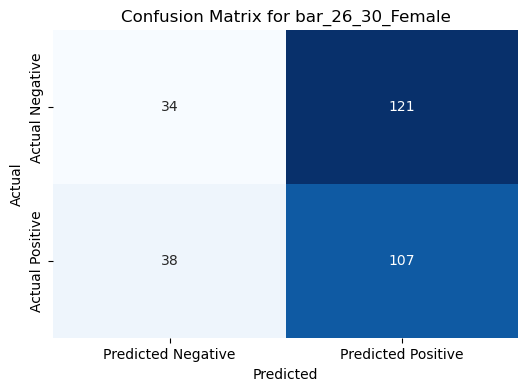

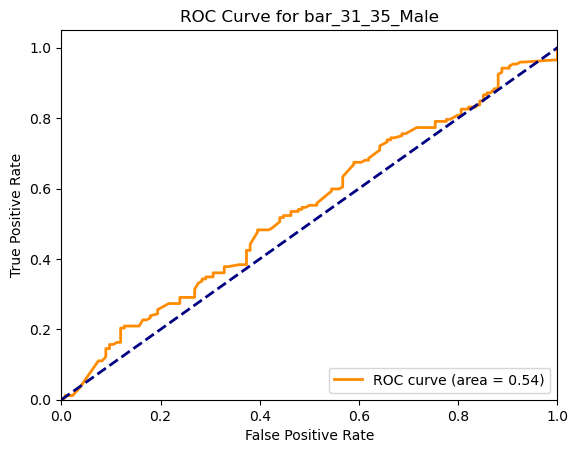

...

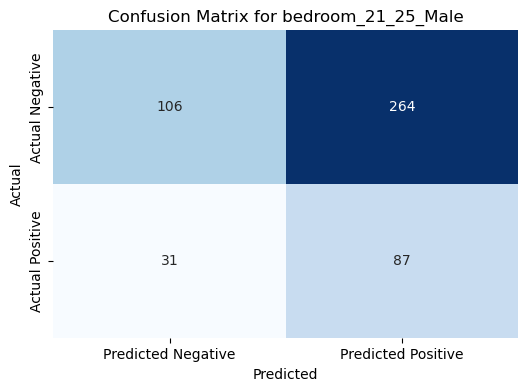

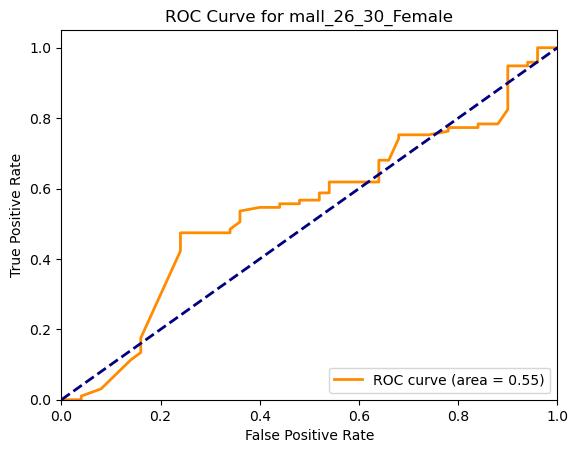

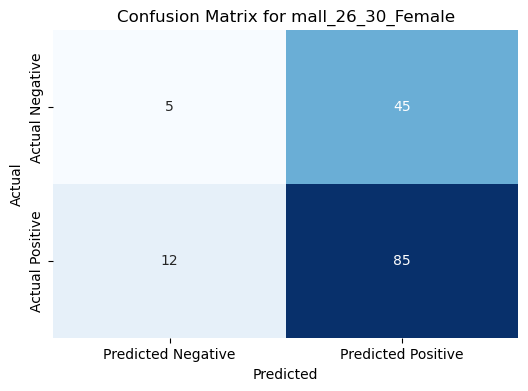

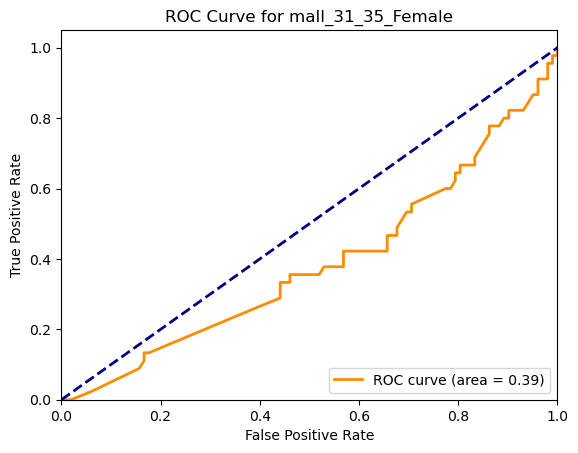

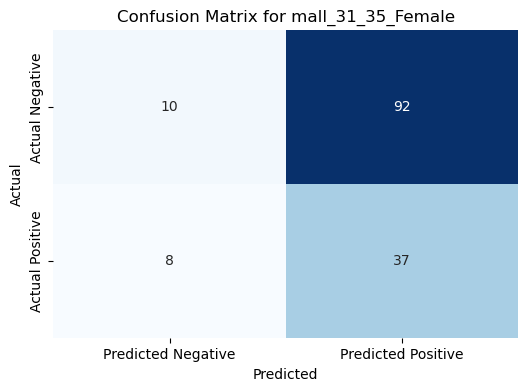

In [22]:
metrics_roberta_trainB, results_roberta_trainB  = evaluate_model_by_group(X_train_roberta_train, y_train_train, 'text_roberta', target_group_train_split, model_robertaB, k=20)


In [153]:
print('Mean Precision score for Second Model with L2 regularisation on Roberta Training Set:', metrics_roberta_trainB['precision_score'].mean())
print('Mean Precision score for Second Model with L2 regularisation on Roberta Validation Set:', metrics_roberta_valB['precision_score'].mean())

Mean Precision score for Second Model with L2 regularisation on Roberta Training Set: 0.5697916666666667
Mean Precision score for Second Model with L2 regularisation on Roberta Validation Set: 0.56875


### Third Model with early stopping

Overfitting still over in Distilroberta data, and I decided to add early stopping

In [25]:
def lda_sgd_pipeline3(X_train, y_train, text_column):
    """
    Creates a pipeline for LDA + SGDClassifier and performs cross-validation.

    Args:
        X_train: Training features (pandas DataFrame).
        y_train: Training labels.
        text_column: Column containing text data.
        n_topics: Number of topics for LDA (default: 10).
        k_folds: Number of folds for cross-validation (default: 5).
        random_state: Random seed (default: 42).

    Returns:
        A tuple containing the trained pipeline, average precision score, and its standard deviation.
    """

    # Define the pipeline
    pipeline = Pipeline([
        ('vectorizer', CountVectorizer(stop_words='english')),  # Vectorize text data
        ('lda', LatentDirichletAllocation(n_components=10, random_state=42)),  # Step 2: LDA for topics
        ('clf', SGDClassifier(random_state=42, loss='log_loss', penalty='l2', max_iter=1000, tol=1e-3,
                              early_stopping=True, n_iter_no_change=5))])
    
    # Perform K-fold cross-validation
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    precision_scores = cross_val_score(pipeline, X_train[text_column], y_train.values.ravel(), cv=kf, scoring='precision')

    # Calculate the average and std deviation of precision across all folds
    precision_mean = np.mean(precision_scores)
    precision_std = np.std(precision_scores)
    
    pipeline.fit(X_train[text_column], y_train.values.ravel())

    return pipeline, precision_mean, precision_std


In [26]:
model_roberta3, _, _ = lda_sgd_pipeline3(X_train_roberta_train, y_train_train, 'text_roberta')

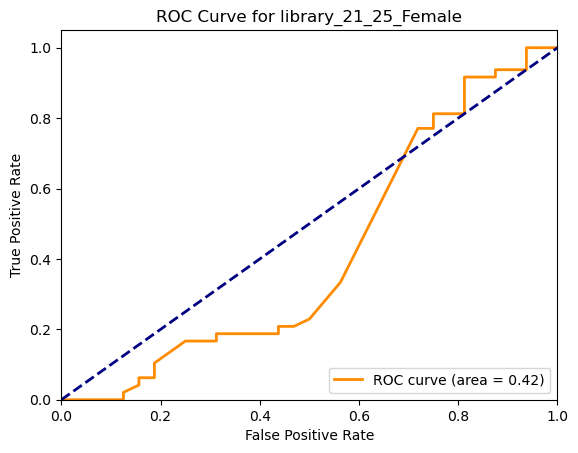

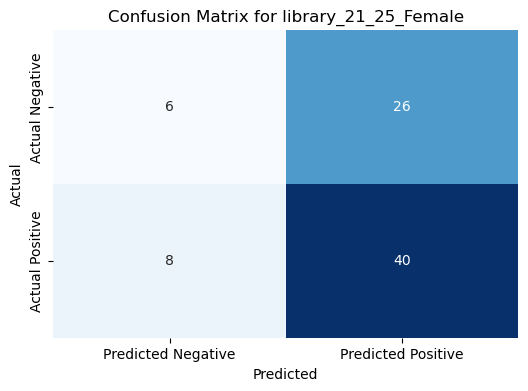

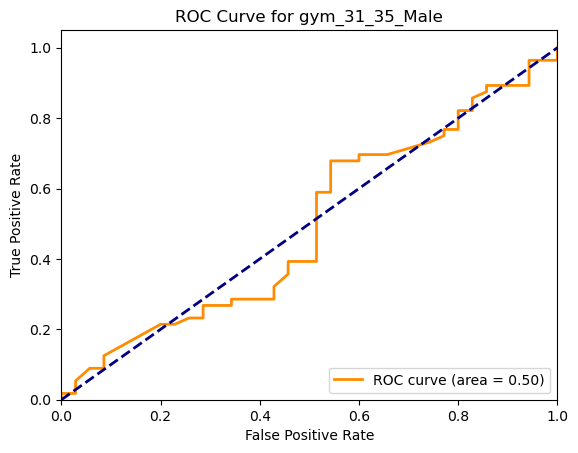

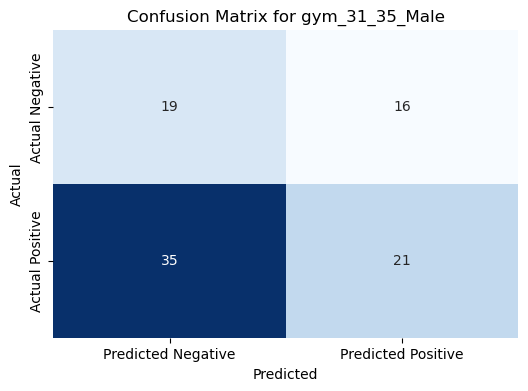

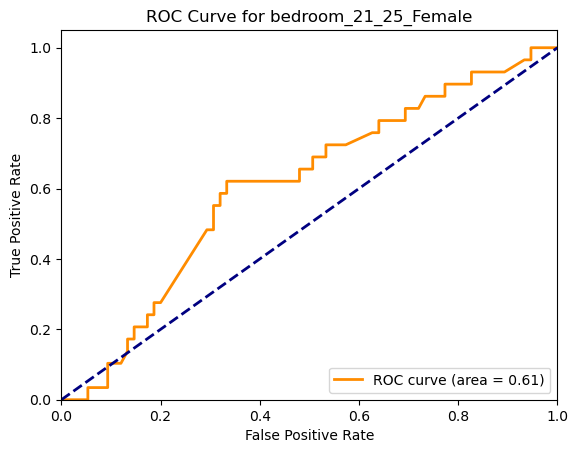

...

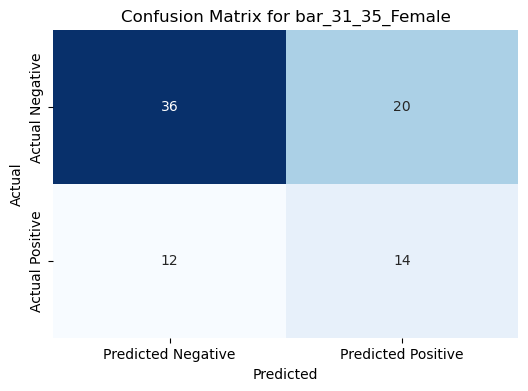

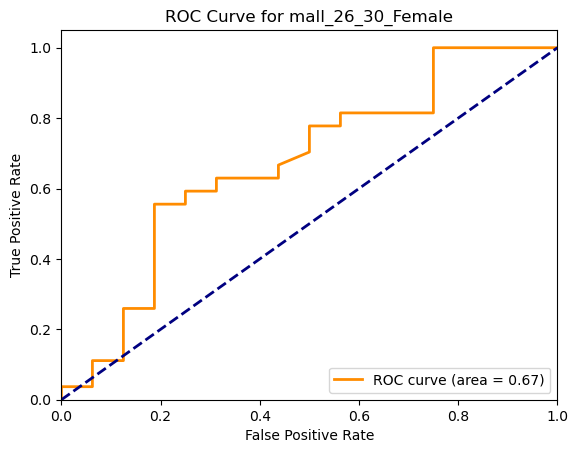

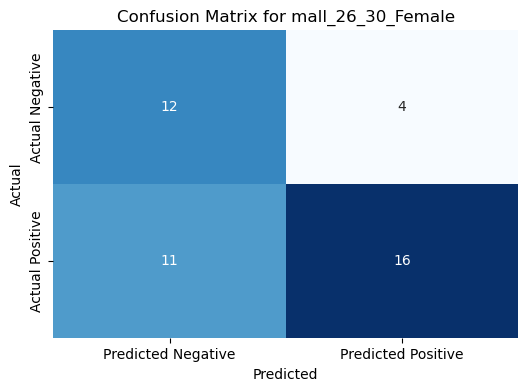

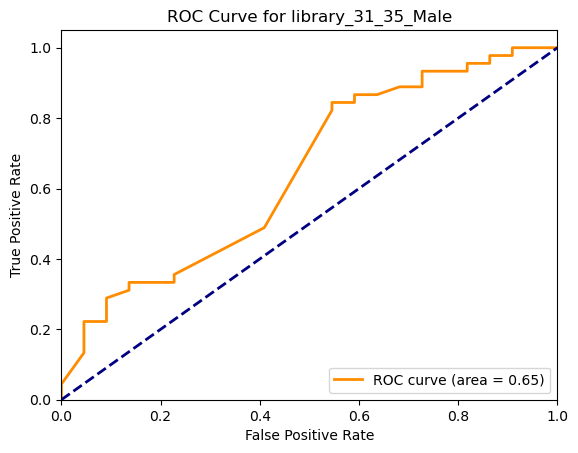

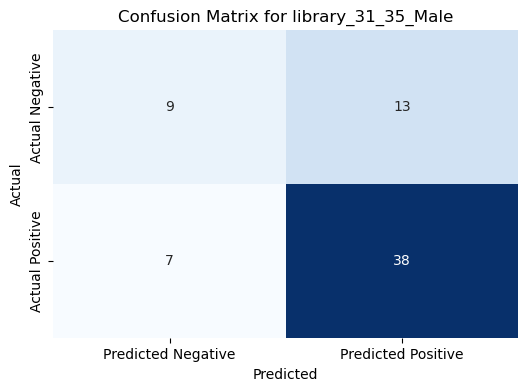

In [27]:
metrics_roberta_valC, results_roberta_valC = evaluate_model_by_group(X_val_roberta, y_val, 'text_roberta', target_group_val_split, model_roberta3, k=20)


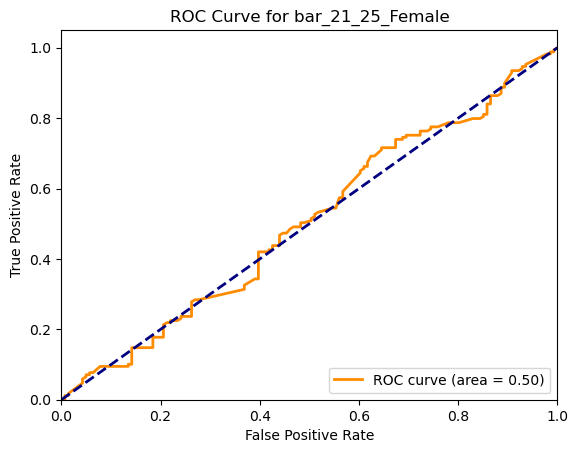

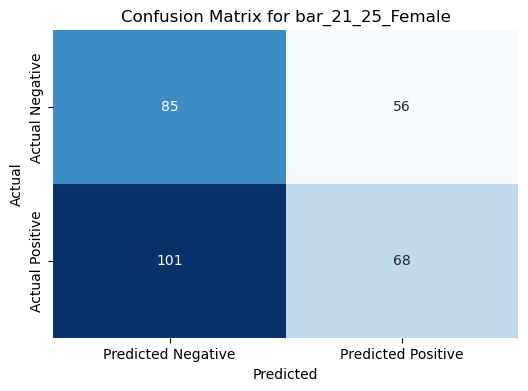

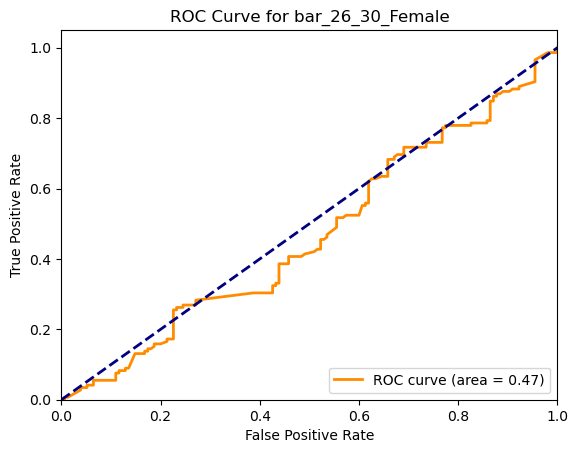

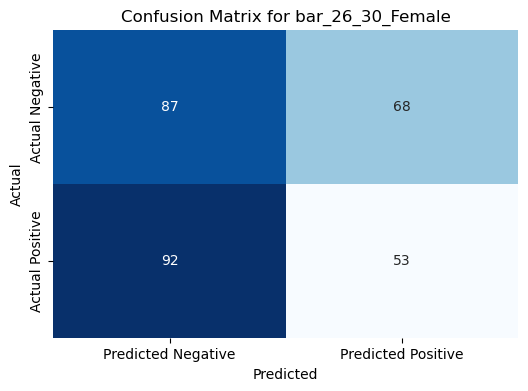

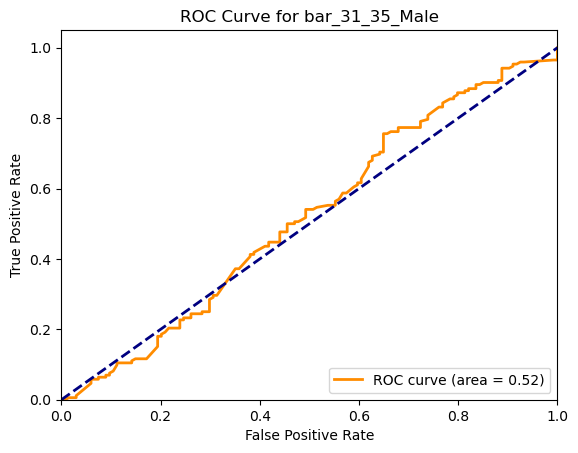

...

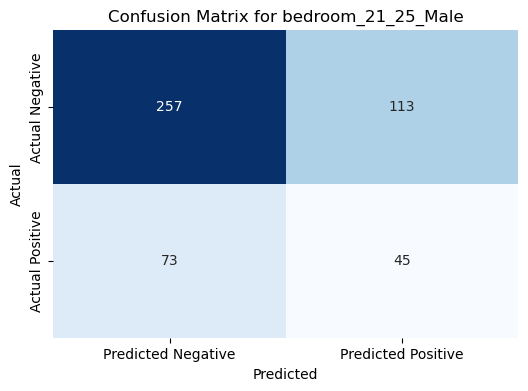

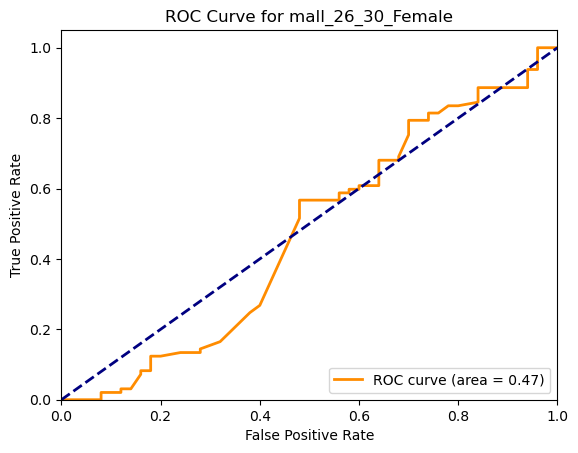

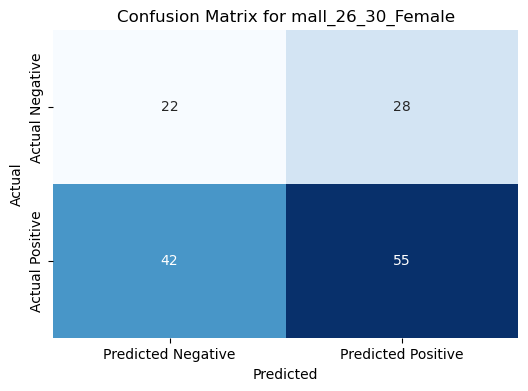

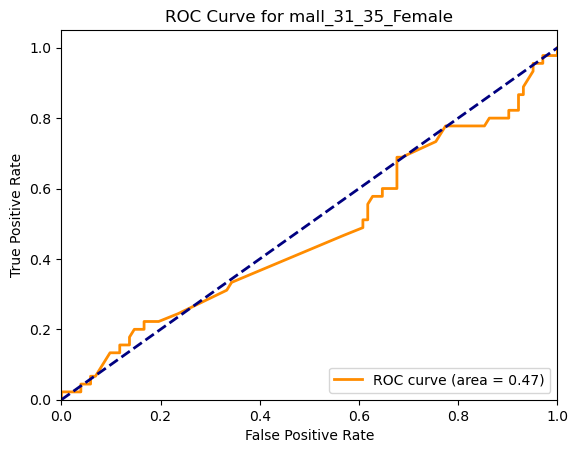

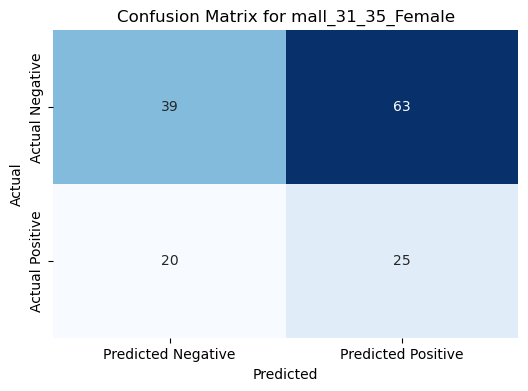

In [28]:
metrics_roberta_trainC, results_roberta_trainC = evaluate_model_by_group(X_train_roberta_train, y_train_train, 'text_roberta', target_group_train_split, model_roberta3, k=20)
                                                                         

In [154]:
print('Mean Precision score for Third Model with L2 regularisation and early stopping  on Roberta Training Set:',metrics_roberta_trainC['precision_score'].mean())
print('Mean Precision score for Third Model with L2 regularisation and early stopping on Roberta Validation Set:', metrics_roberta_valC['precision_score'].mean())

Mean Precision score for Third Model with L2 regularisation and early stopping  on Roberta Training Set: 0.5656249999999999
Mean Precision score for Third Model with L2 regularisation and early stopping on Roberta Validation Set: 0.5472756410256411


### Hyperparameter Tuning

Using the early stopping criteria corrected overfitting in distilroberta, but a common challenge is that none of the validation set had a score over 0.6 and the ROC Curve shows that some target groups are guessing rather than predicting. To optimise performance I did a grid search hyperparameter tuning

In [31]:
def lda_grid_search(X_train, y_train, text_column):
    """
    Performs Grid Search for a pipeline of LDA + SGDClassifier, focusing on LDA parameters.
    
    Args:
        X_train: Training data (Pandas DataFrame) containing the text data.
        y_train: Target labels for classification.
        text_column: The name of the column containing text data in X_train.
        
    Returns:
        grid_search: The fitted GridSearchCV object.
        best_params: The best parameters found during GridSearchCV.
        best_score: The best score (precision) obtained during GridSearchCV.
    """
    
    # Define the pipeline with LDA and SGDClassifier
    pipeline = Pipeline([
        ('vectorizer', CountVectorizer(stop_words='english')),
        ('lda', LatentDirichletAllocation(random_state=42)),
        ('clf', SGDClassifier(random_state=42, loss='log_loss', penalty='l2', max_iter=1000, tol=1e-3,
                              early_stopping=True, n_iter_no_change=5))
    ])

    # Simplified LDA parameter grid
    param_grid = {
        'lda__n_components': [5, 25, 50, 75, 100],  # Fewer components to try
        'lda__doc_topic_prior': [0.05, 0.1, 0.5],  
        'lda__topic_word_prior': [0.01, 0.05, 0.1],
        'lda__max_iter': [100, 200]  # Reducing number of iterations
    }

    # Set up GridSearchCV with 3-fold CV to speed things up
    grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='precision', verbose=2, n_jobs=-1)

    # Fit the GridSearchCV on the training data
    grid_search.fit(X_train[text_column], y_train.values.ravel())
    
    # Access precision scores for each parameter combination
    precision_scores = grid_search.cv_results_['mean_test_score']
    parameter_combinations = grid_search.cv_results_['params']

    # Print precision scores and corresponding parameter combinations
    for score, params in zip(precision_scores, parameter_combinations):
        print(f"Precision: {score:.3f}, Parameters: {params}")
        
    # Get the best parameters and the best score
    best_params = grid_search.best_params_
    best_score = grid_search.best_score_
    best_model = grid_search.best_estimator_
    

    # Print the best parameters and score
    print("\nBest parameters found: ", best_params)
    print("Best precision score: ", best_score)

    # Return the fitted GridSearchCV object and the best results
    return best_model, best_params, best_score


In [32]:
best_model_roberta, best_params_roberta, best_score_roberta = lda_grid_search(X_train_roberta_train, y_train_train, 'text_roberta')
print("Best Parameters:", best_params_roberta)
print("Best Precision Score:", best_score_roberta)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Precision: 0.547, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.01}
Precision: 0.547, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.05}
Precision: 0.547, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.1}
Precision: 0.559, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.01}
Precision: 0.563, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.05}
Precision: 0.561, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.1}
Precision: 0.569, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 50, '

In [ ]:
# The best parameter for roberta:
# Best parameters found:  {'lda__doc_topic_prior': 0.1, 'lda__max_iter': 200, 'lda__n_components': 50, 'lda__topic_word_prior': 0.01}
# Best precision score:  0.5697614663299565

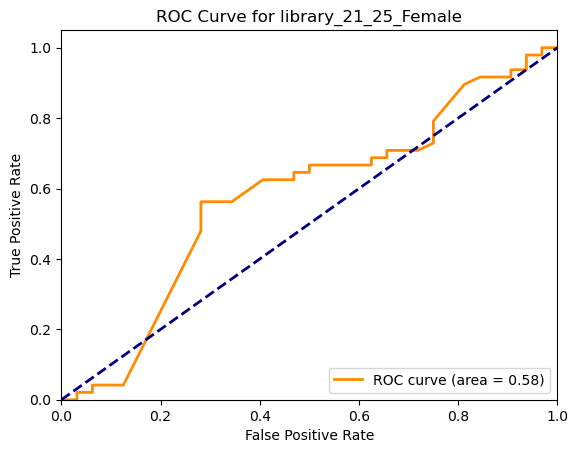

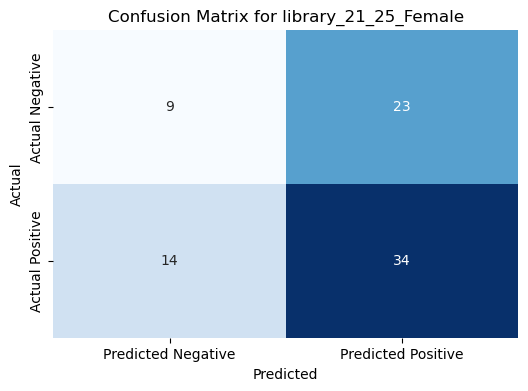

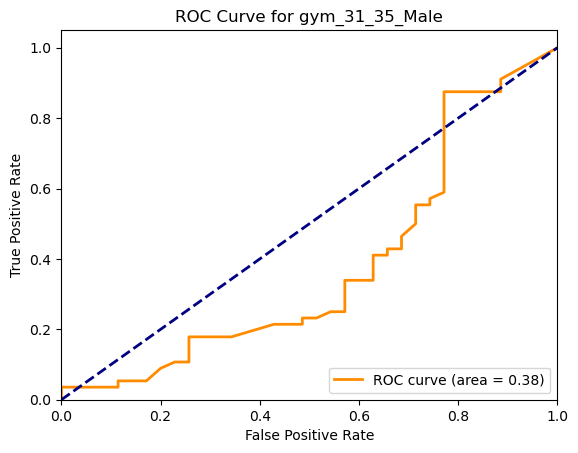

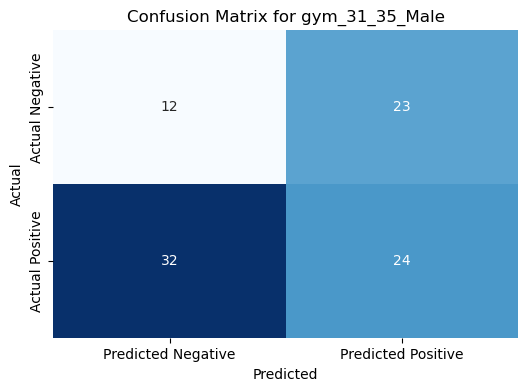

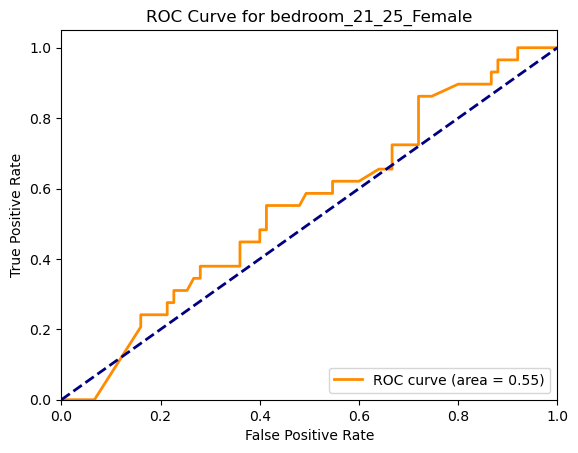

...

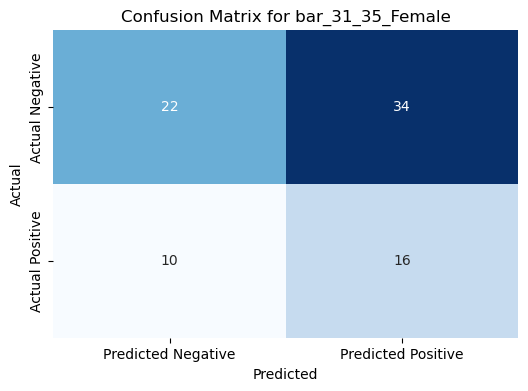

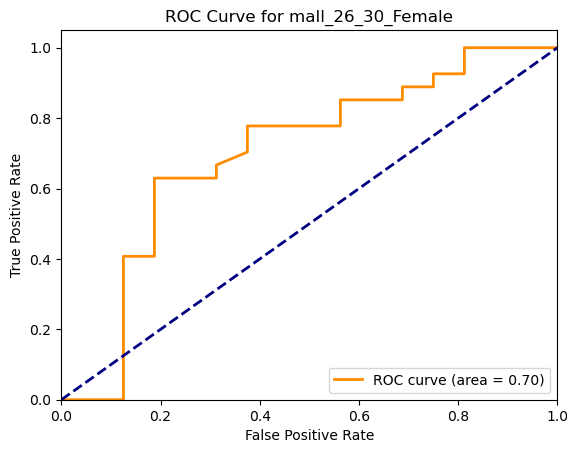

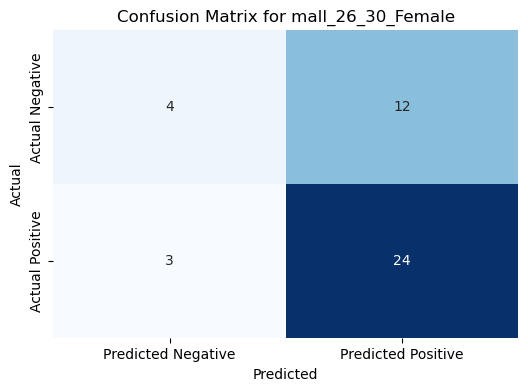

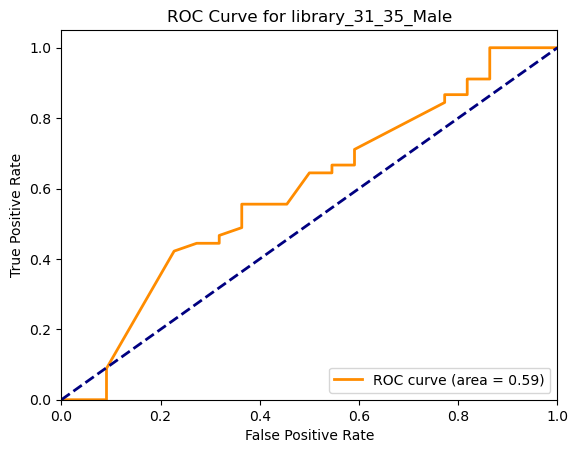

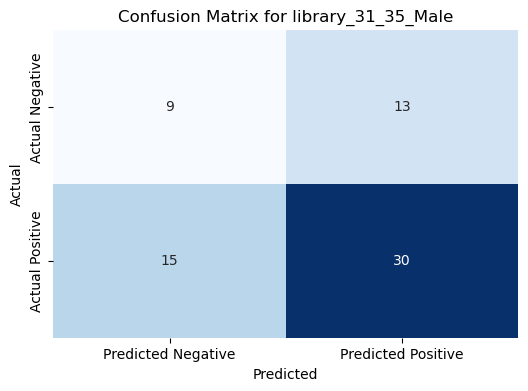

In [33]:
metrics_roberta_valD, results_roberta_valD = evaluate_model_by_group(X_val_roberta, y_val, 'text_roberta', target_group_val_split, best_model_roberta, k=20)


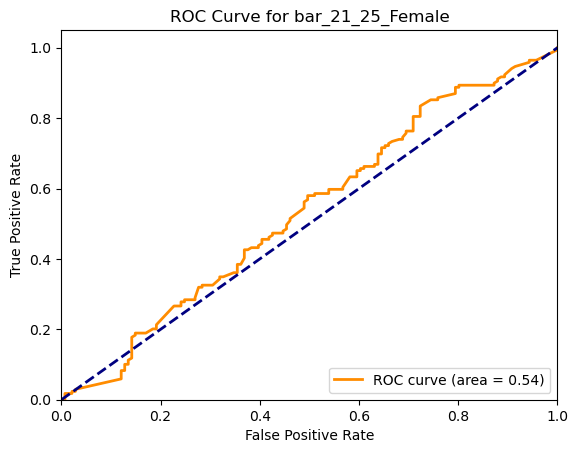

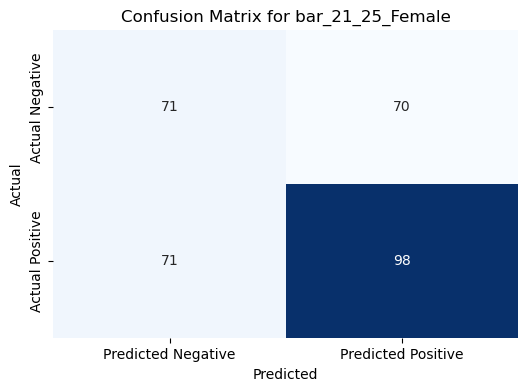

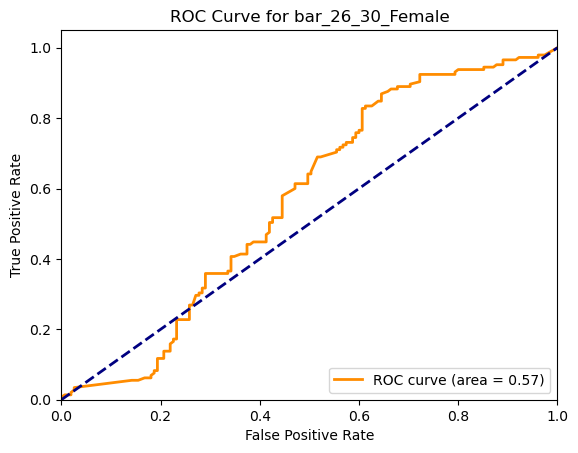

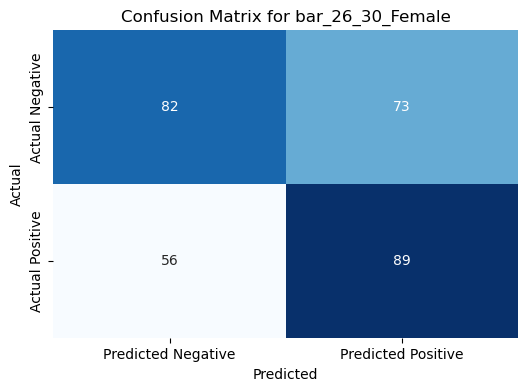

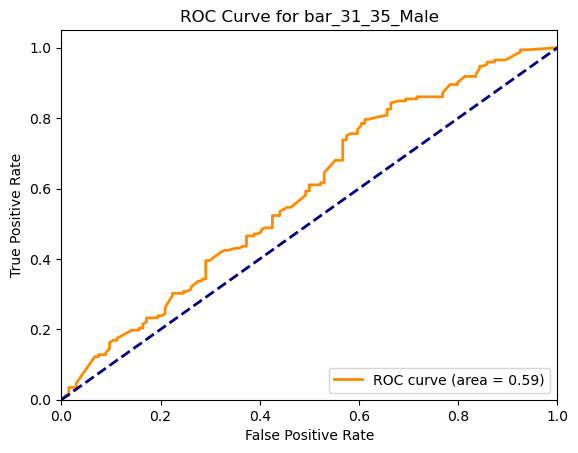

...

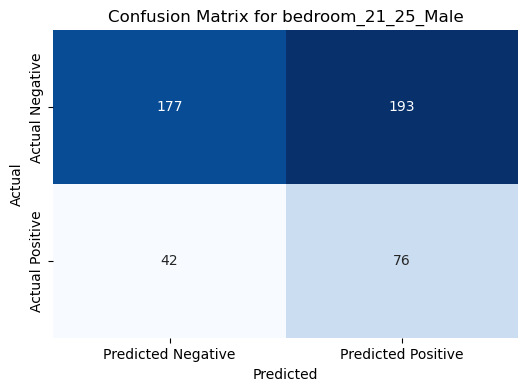

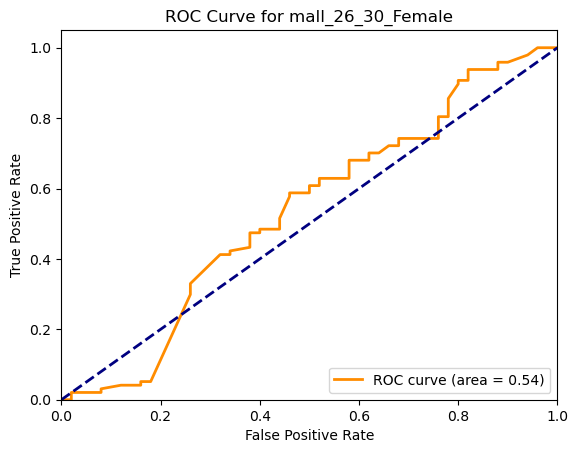

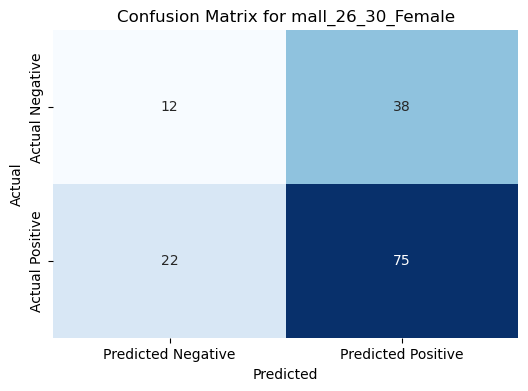

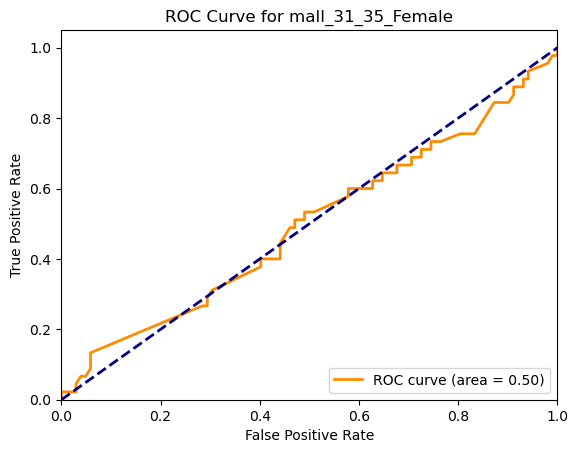

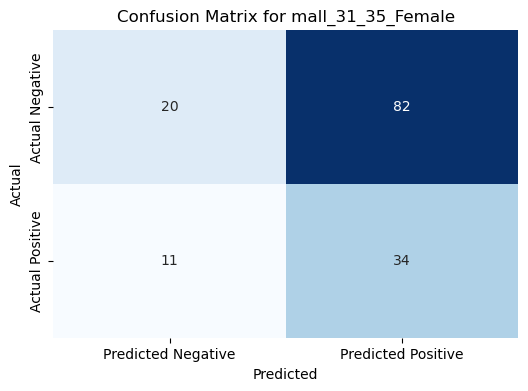

In [35]:
metrics_roberta_trainD, results_roberta_trainD = evaluate_model_by_group(X_train_roberta_train, y_train_train, 'text_roberta', target_group_train_split, best_model_roberta, k=20)


In [155]:
print('Mean Precision score for Hyperparameter Tuning Best Model for Roberta:',metrics_roberta_trainD['precision_score'].mean())
print('Mean Precision score for Hyperparameter Tuning Best Model for Roberta:', metrics_roberta_valD['precision_score'].mean())

Mean Precision score for Hyperparameter Tuning Best Model for Roberta: 0.6354166666666666
Mean Precision score for Hyperparameter Tuning Best Model for Roberta: 0.5885416666666666


* Overfitting was worse after hyperparameter tuning was done

### Roberta Score Summary 

In [125]:
print('Baseline Model: taining',metrics_roberta_trainA['precision_score'].mean())
print('Baseline Model: validation',metrics_roberta_valA['precision_score'].mean())
print('---------------------------------------')
print('Model 2: training',metrics_roberta_trainB['precision_score'].mean())
print('Model 2: validation',metrics_roberta_valB['precision_score'].mean())
print('---------------------------------------')
print('Model 3: training', metrics_roberta_trainC['precision_score'].mean())
print('Model 3: validation',metrics_roberta_valC['precision_score'].mean())
print('---------------------------------------')
print('Hyperparameter Tuning Best Model:training',metrics_roberta_trainD['precision_score'].mean())
print('Hyperparameter Tuning Best Model:vaildation', metrics_roberta_valD['precision_score'].mean())

Baseline Model: taining 0.5697916666666667
Baseline Model: validation 0.56875
---------------------------------------
Model 2: training 0.5697916666666667
Model 2: validation 0.56875
---------------------------------------
Model 3: training 0.5656249999999999
Model 3: validation 0.5472756410256411
---------------------------------------
Hyperparameter Tuning Best Model:training 0.6354166666666666
Hyperparameter Tuning Best Model:vaildation 0.5885416666666666


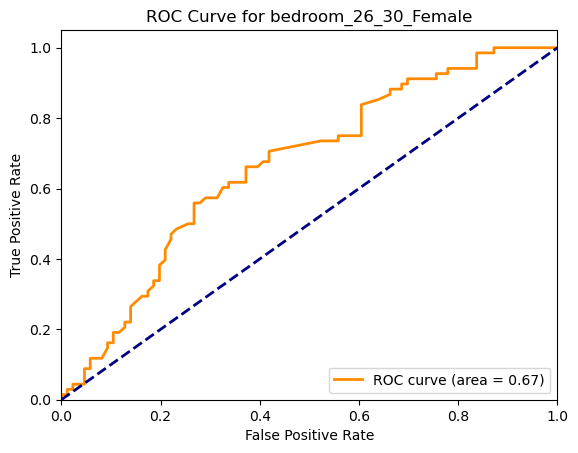

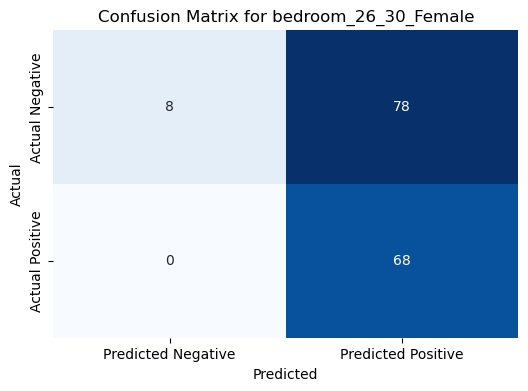

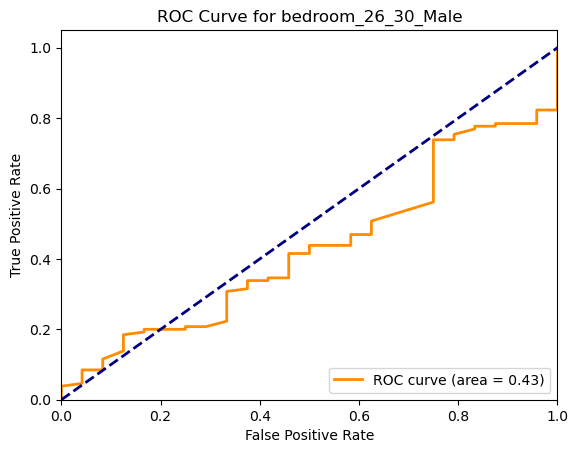

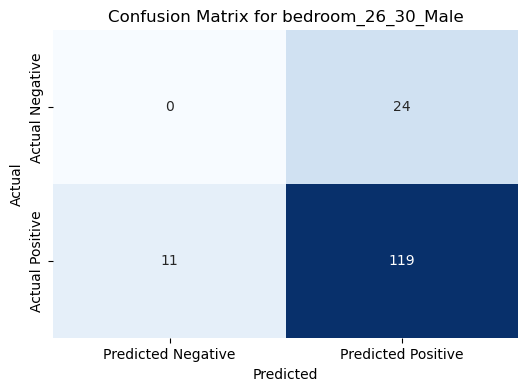

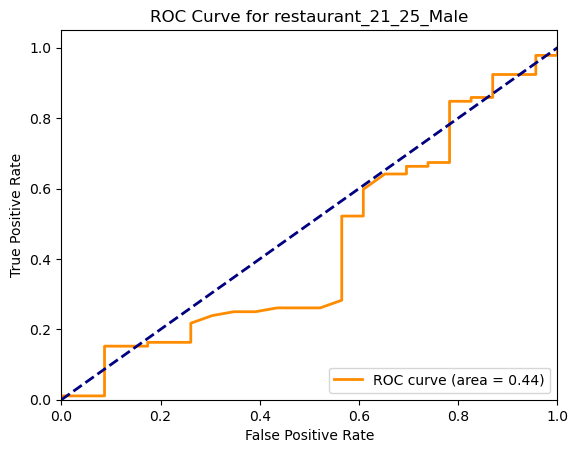

...

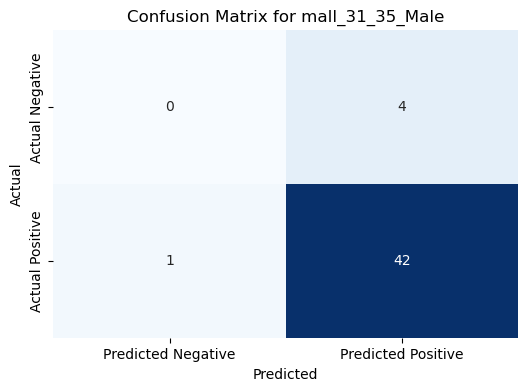

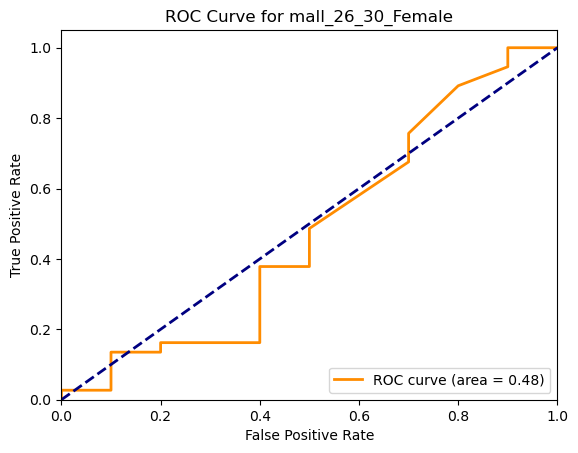

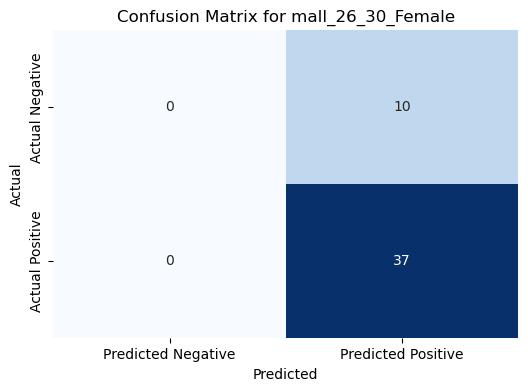

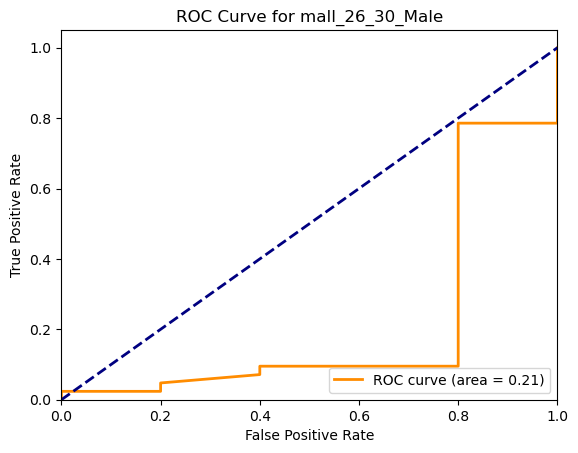

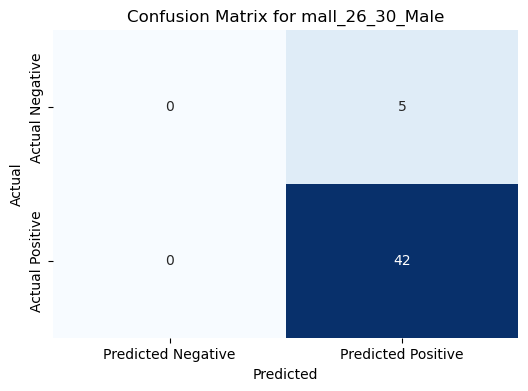

In [85]:
metrics_distilroberta_test, results_distilroberta_test = evaluate_model_by_group(X_test_distilroberta, y_test, 'text_distilroberta', target_group_test, model_distilrobertaC, k=20)


## Distilroberta

### Implement baseline model on distilroberta

In [36]:
baseline_model_distilrobertaA, _, _ = lda_sgd_pipeline(X_train_distilroberta_train, y_train_train, 'text_distilroberta')

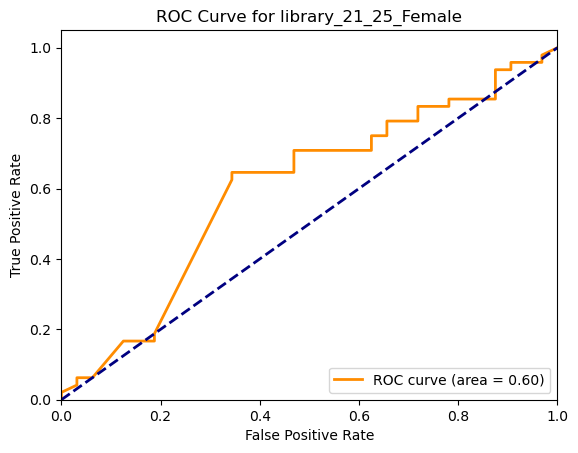

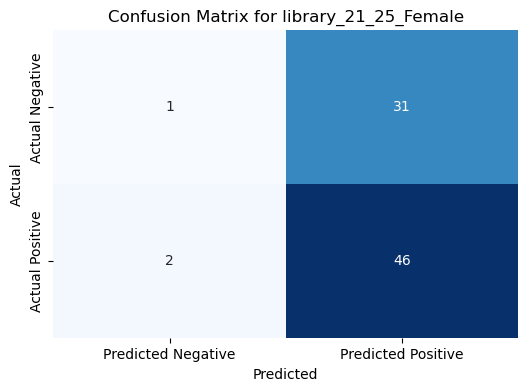

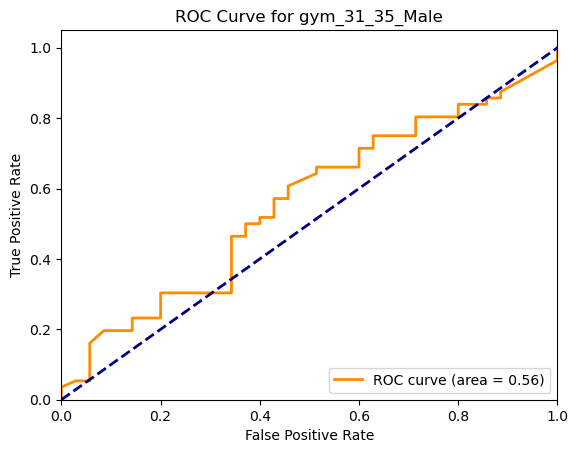

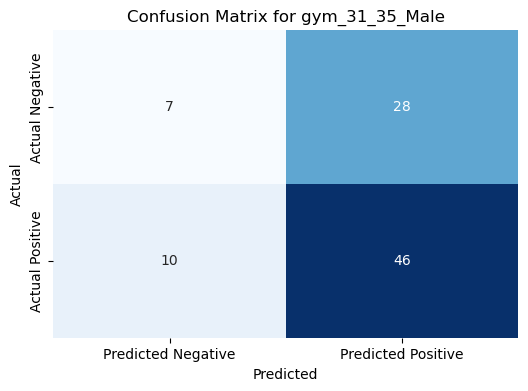

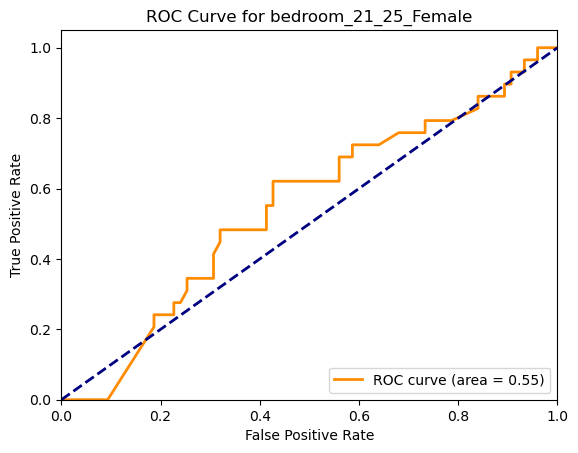

...

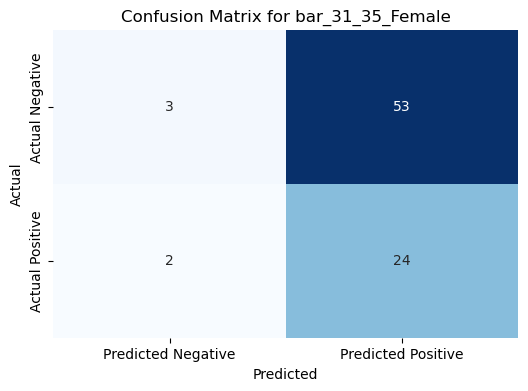

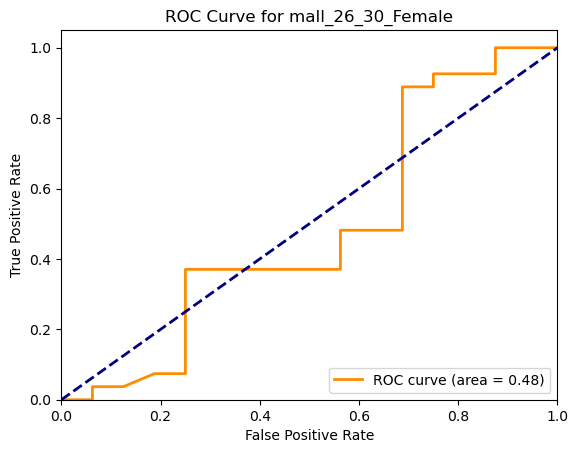

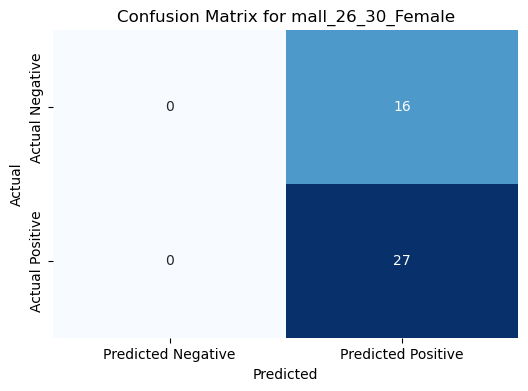

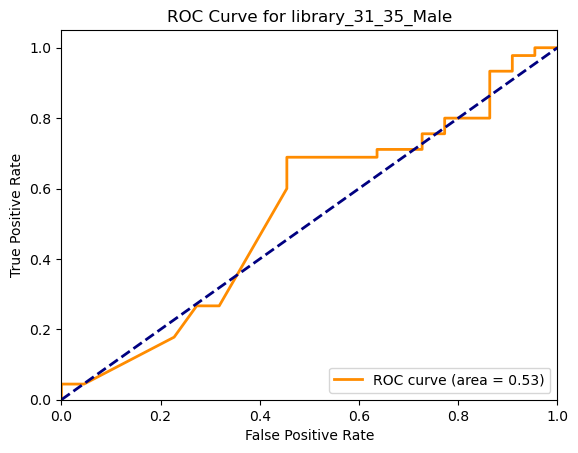

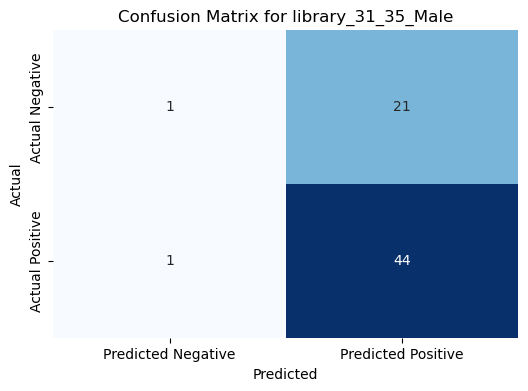

In [38]:
metrics_distilroberta_valA, results_distilroberta_valA = evaluate_model_by_group(X_val_distilroberta, y_val, 'text_distilroberta', target_group_val_split, baseline_model_distilrobertaA, k=20)


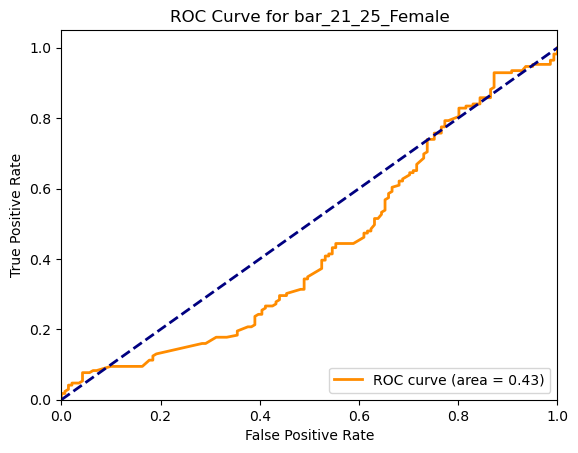

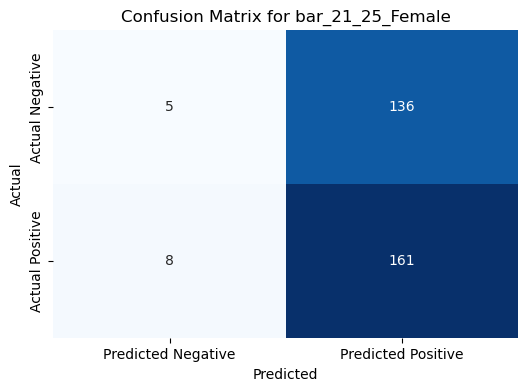

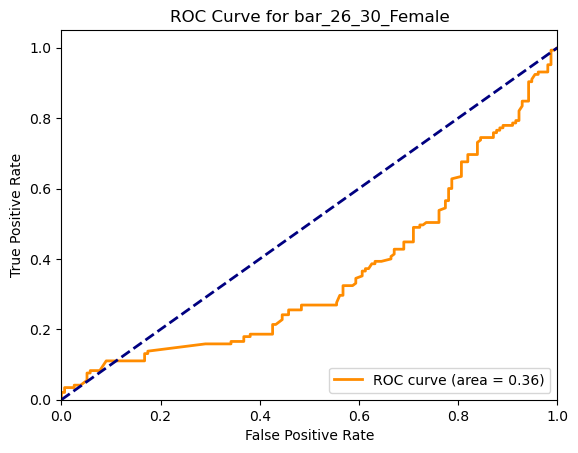

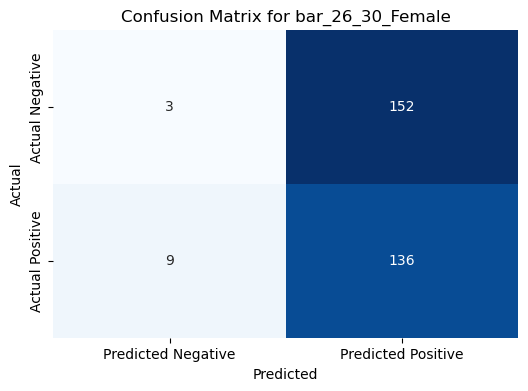

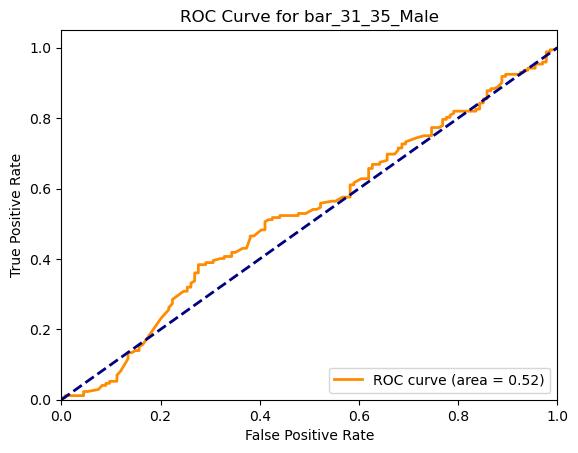

...

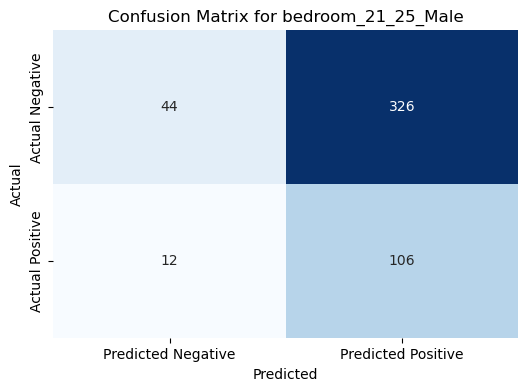

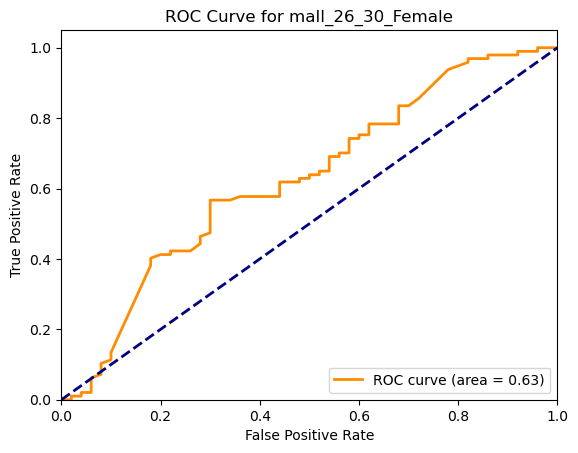

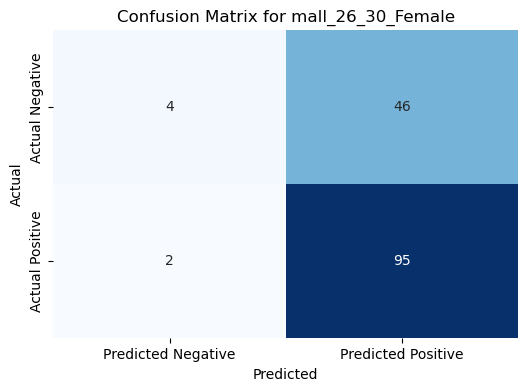

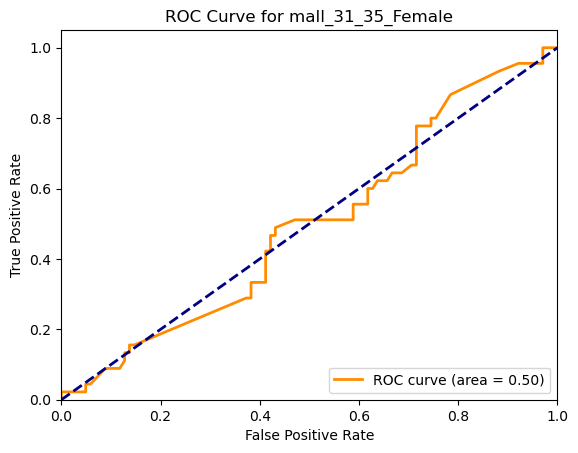

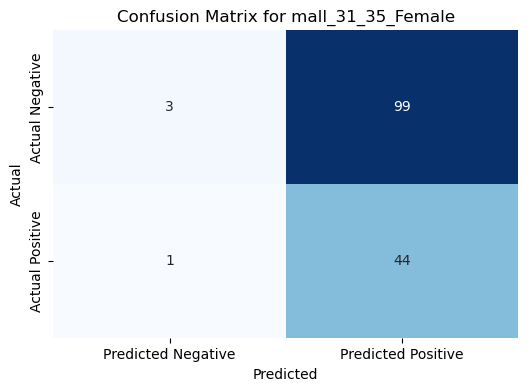

In [39]:
metrics_distilroberta_trainA, results_distilroberta_trainA  = evaluate_model_by_group(X_train_distilroberta_train, y_train_train, 'text_distilroberta', target_group_train_split, baseline_model_distilrobertaA, k=20)


In [156]:
print('Mean Precision score for Baseline Model on Distilroberta Training Set:', metrics_distilroberta_trainA['precision_score'].mean())
print('Mean Precision score for Baseline Model on Distilroberta Validation Set:', metrics_distilroberta_valA['precision_score'].mean())

Mean Precision score for Baseline Model on Distilroberta Training Set: 0.5906250000000001
Mean Precision score for Baseline Model on Distilroberta Validation Set: 0.55625


### Second Model: L2 regularisation

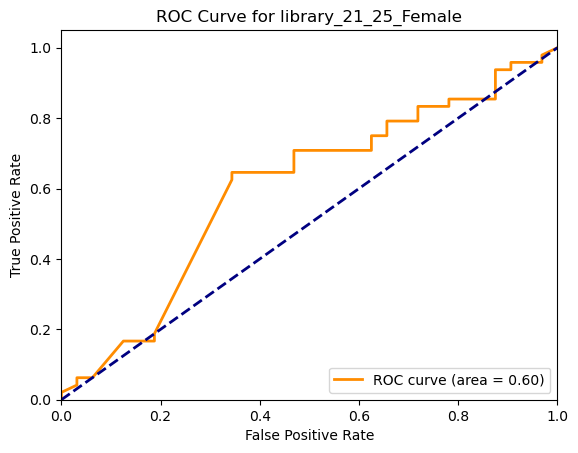

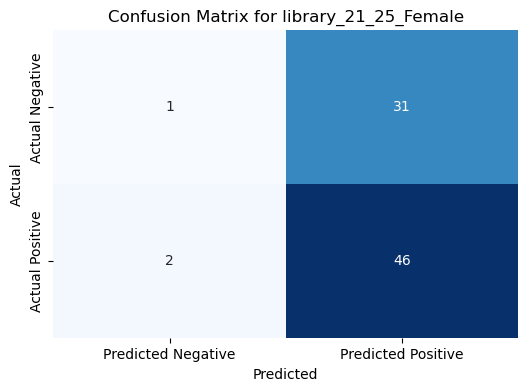

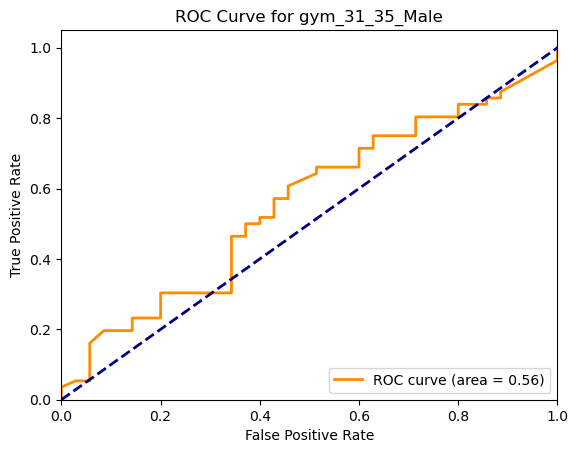

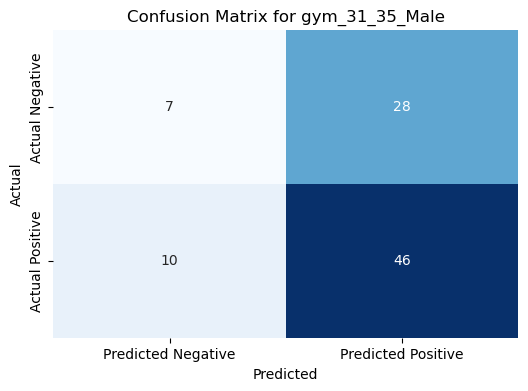

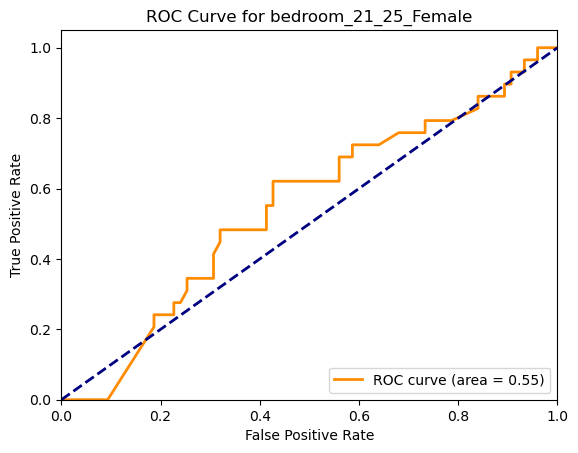

...

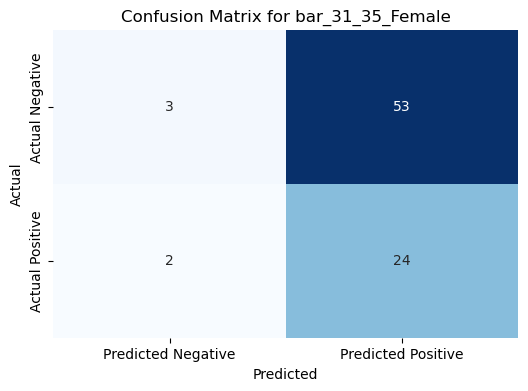

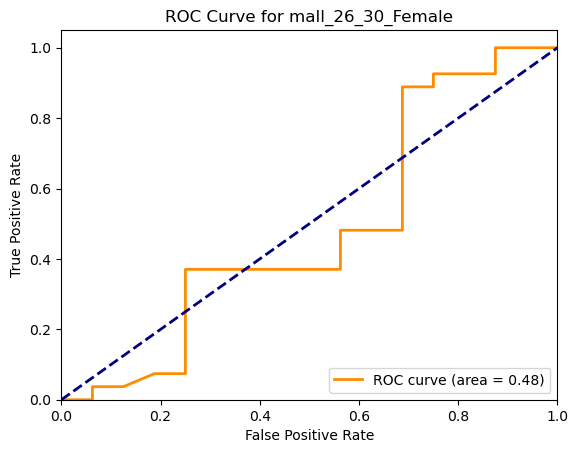

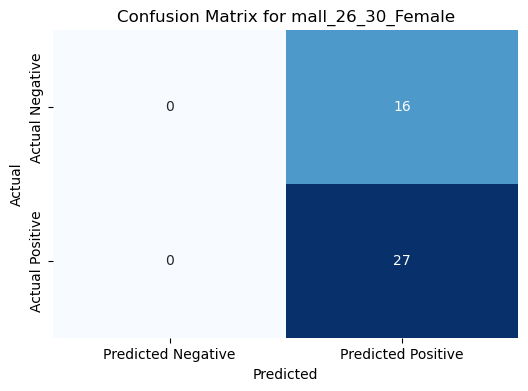

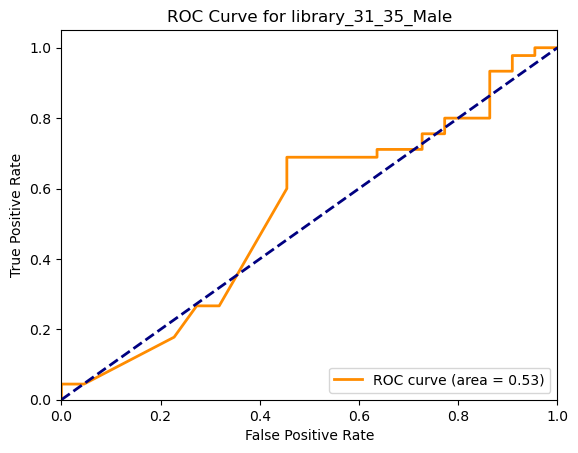

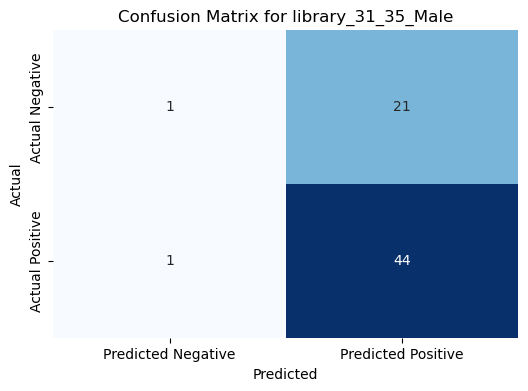

In [41]:
model_distilrobertaB, _, _ = lda_sgd_pipeline2(X_train_distilroberta_train, y_train_train, 'text_distilroberta')
metrics_distilroberta_valB, results_distilroberta_valB = evaluate_model_by_group(X_val_distilroberta, y_val, 'text_distilroberta', target_group_val_split, model_distilrobertaB, k=20)


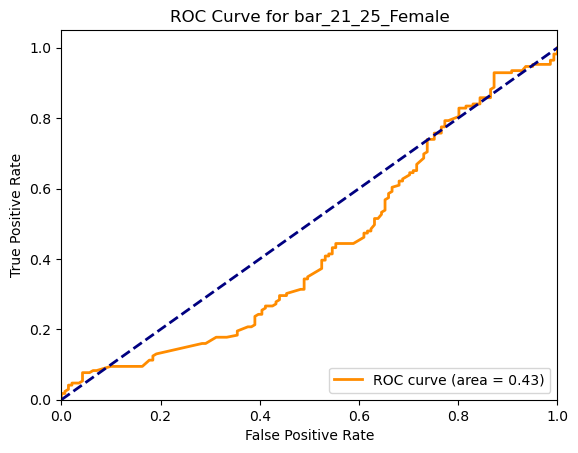

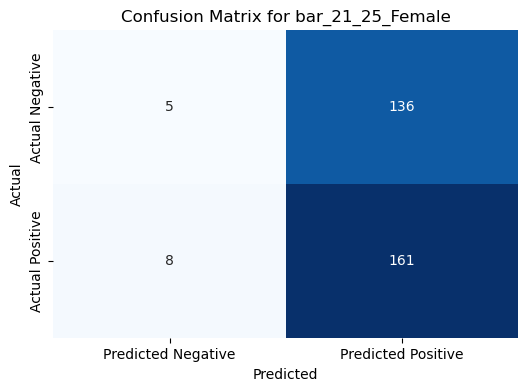

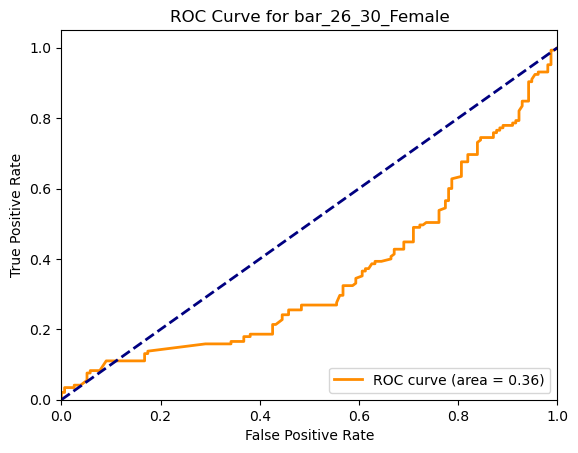

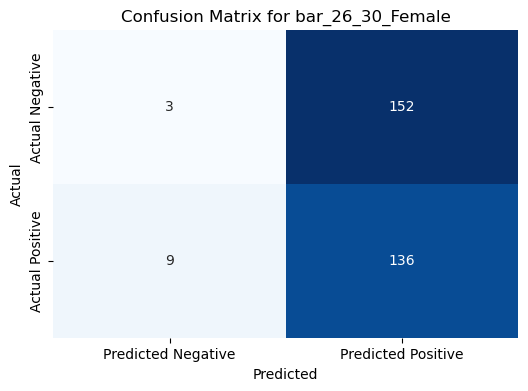

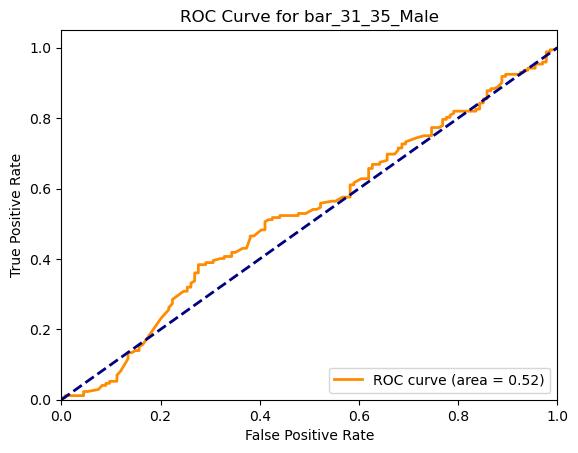

...

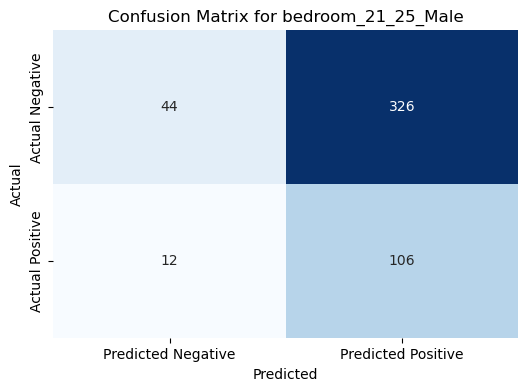

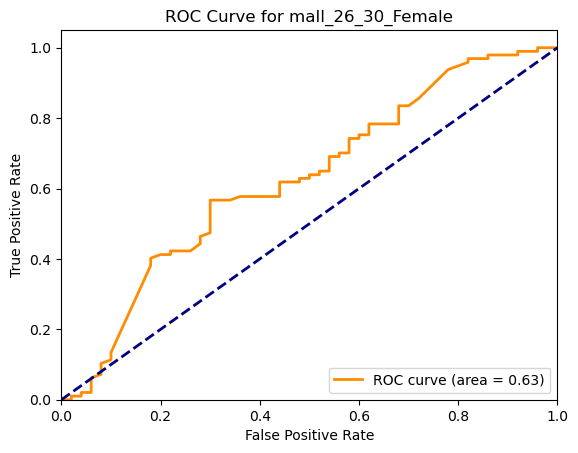

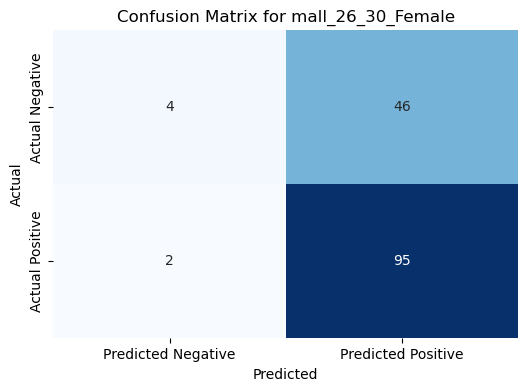

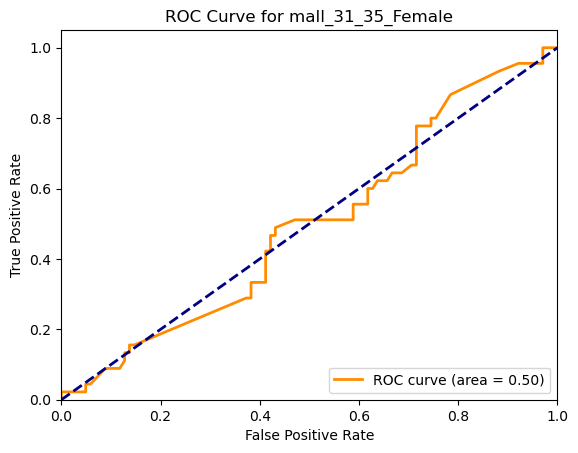

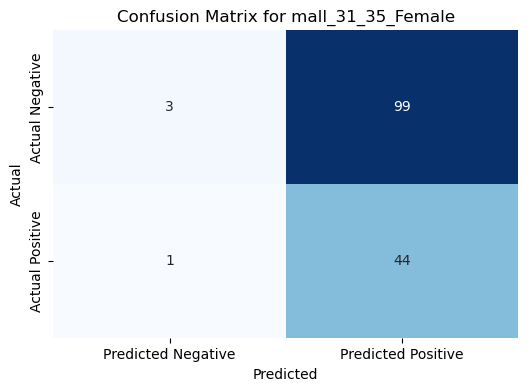

In [42]:
metrics_distilroberta_trainB, results_distilroberta_trainB  = evaluate_model_by_group(X_train_distilroberta_train, y_train_train, 'text_distilroberta', target_group_train_split, model_distilrobertaB, k=20)


In [157]:
print('Mean Precision score for Second Model with L2 regularisation on Distilroberta Training Set:', metrics_distilroberta_trainB['precision_score'].mean())
print('Mean Precision score for Second Model with L2 regularisation on Distilroberta validation Set:', metrics_distilroberta_valB['precision_score'].mean())

Mean Precision score for Second Model with L2 regularisation on Distilroberta Training Set: 0.5906250000000001
Mean Precision score for Second Model with L2 regularisation on Distilroberta validation Set: 0.55625


* Model is performed slightly better in training data

### Third Model: Early stopping added

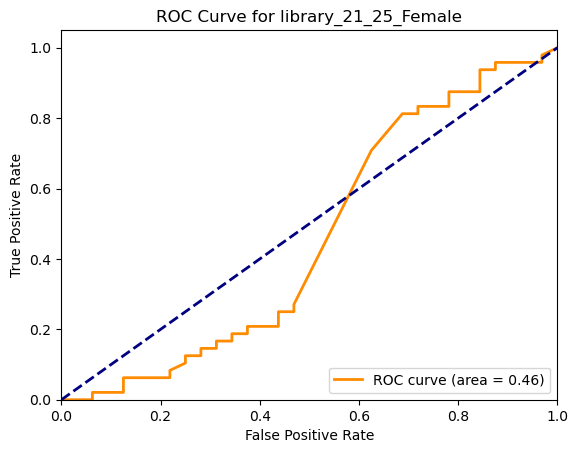

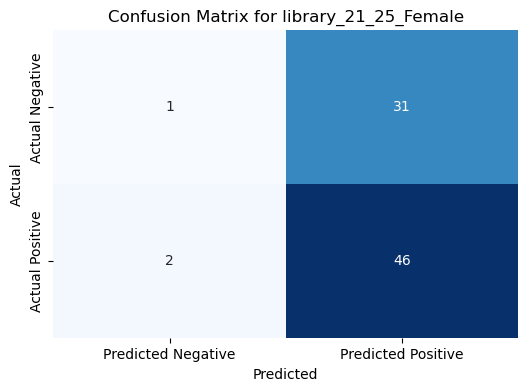

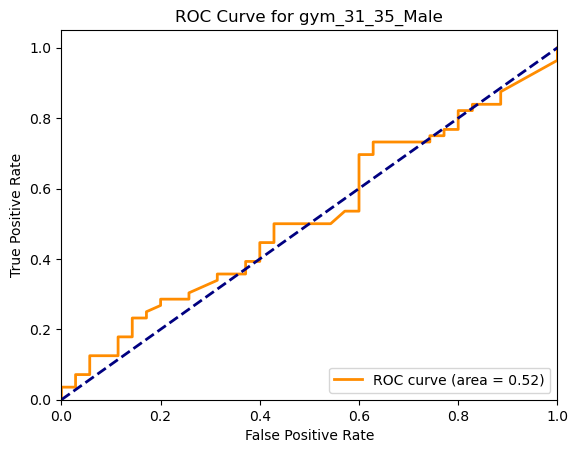

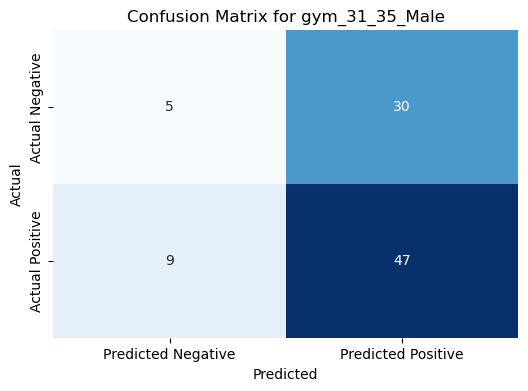

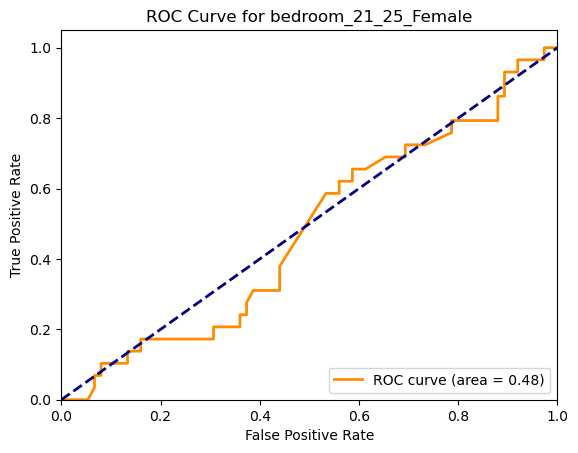

...

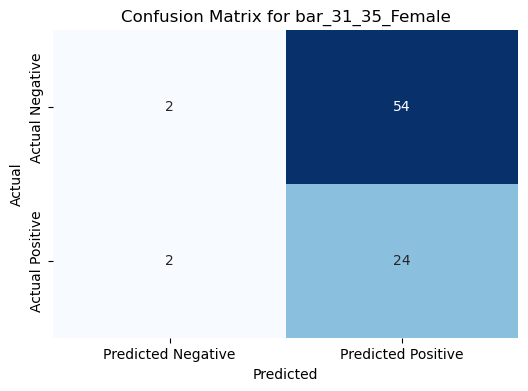

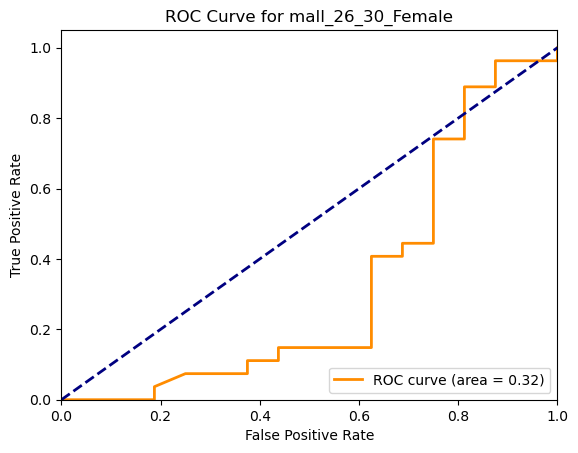

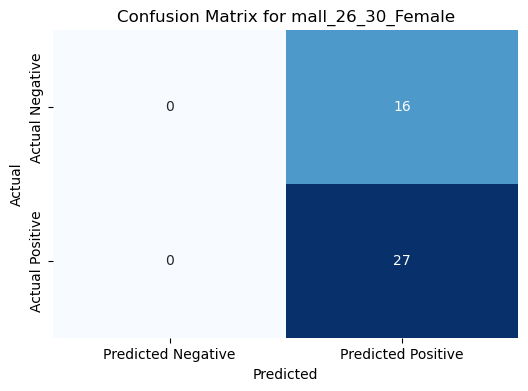

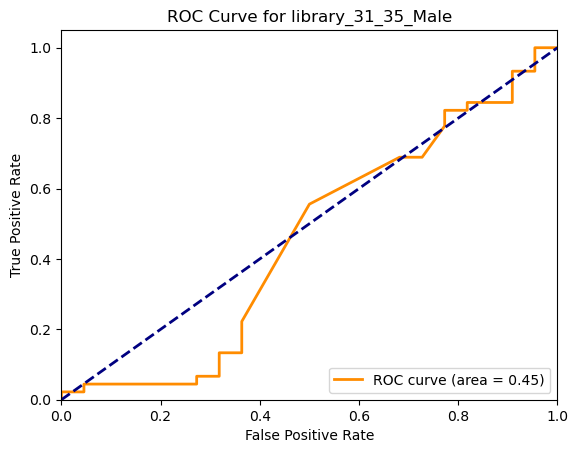

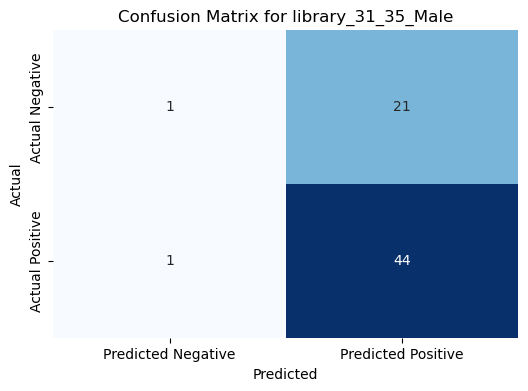

In [44]:
model_distilrobertaC, _, _ = lda_sgd_pipeline3(X_train_distilroberta_train, y_train_train, 'text_distilroberta')
metrics_distilroberta_valC, results_distilroberta_valC = evaluate_model_by_group(X_val_distilroberta, y_val, 'text_distilroberta', target_group_val_split, model_distilrobertaC, k=20)


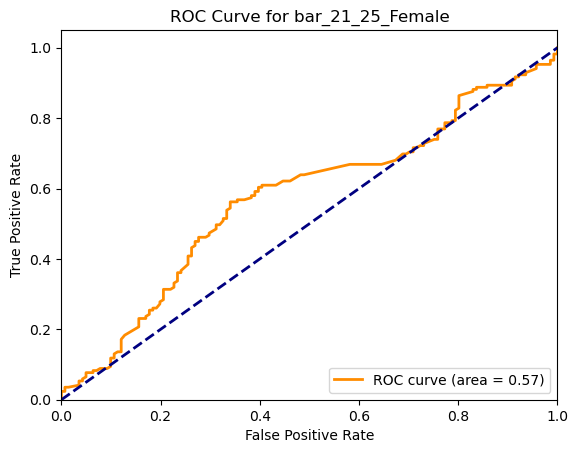

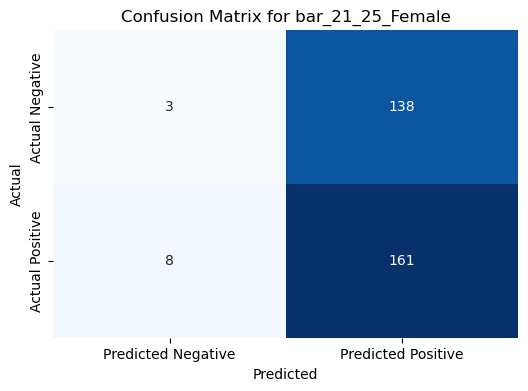

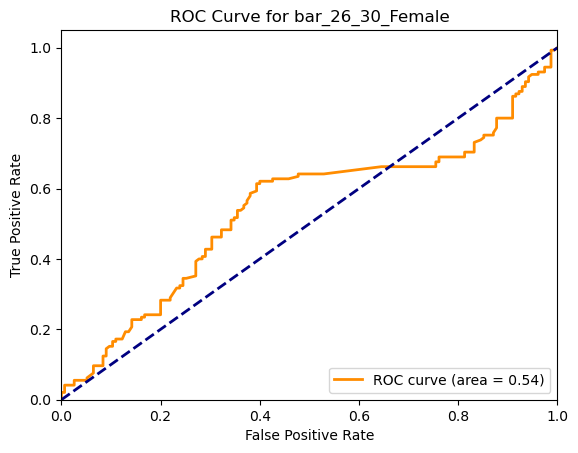

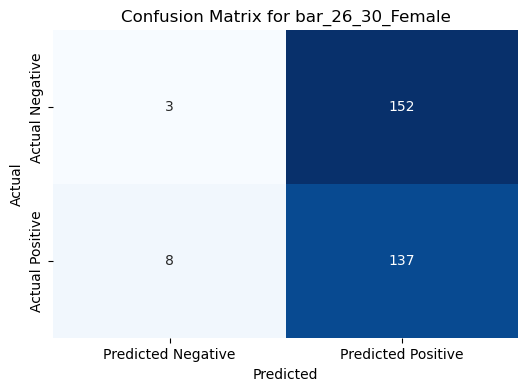

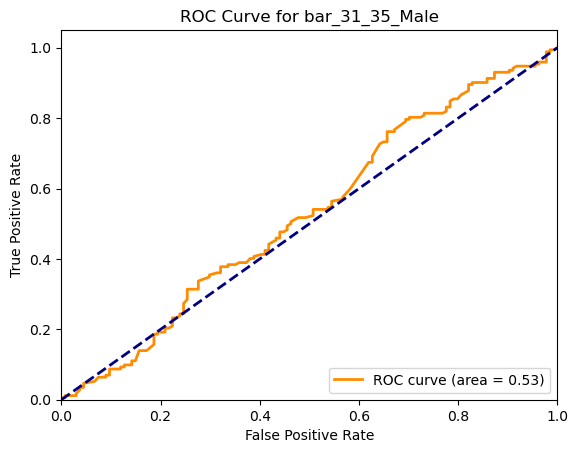

...

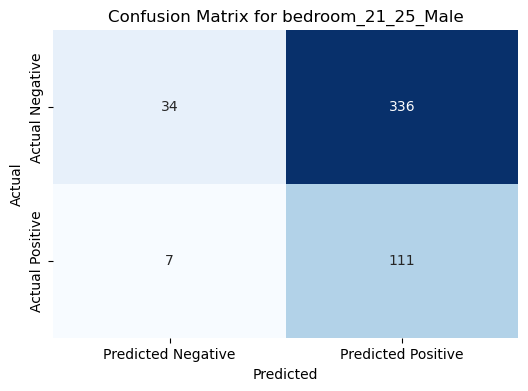

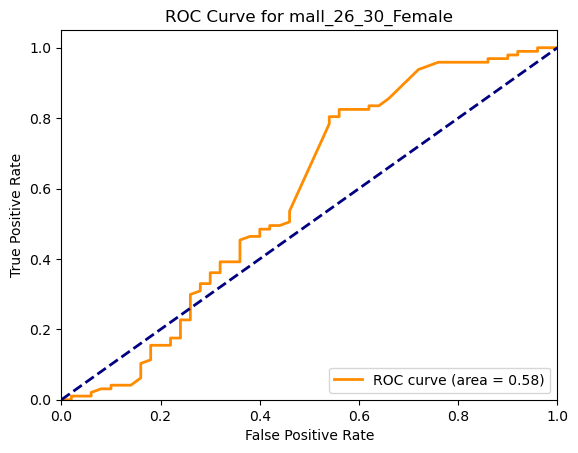

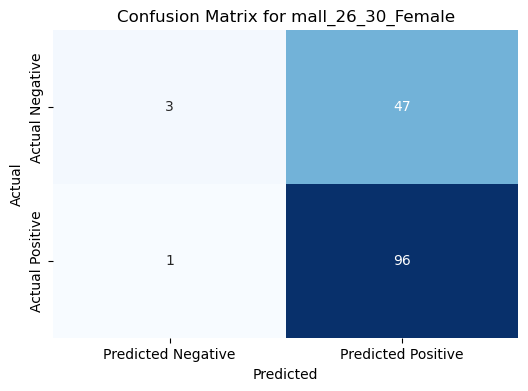

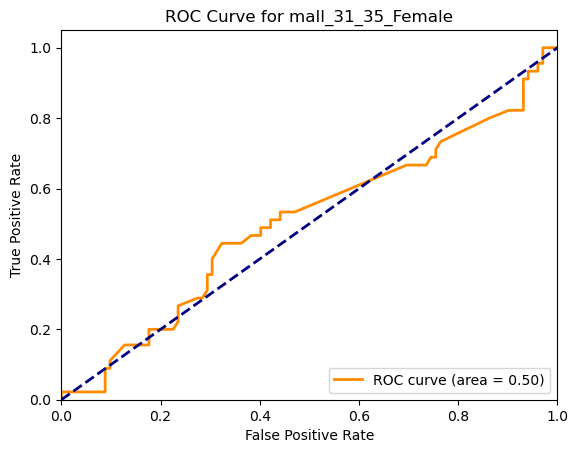

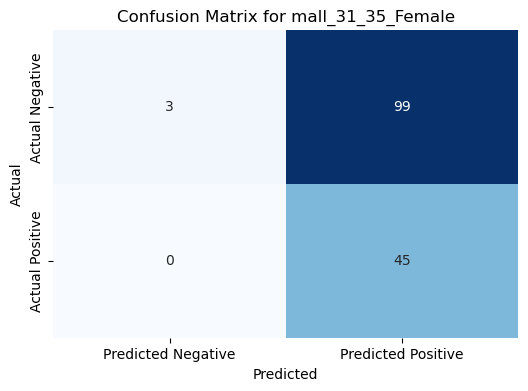

In [45]:
metrics_distilroberta_trainC, results_distilroberta_trainC  = evaluate_model_by_group(X_train_distilroberta_train, y_train_train, 'text_distilroberta', target_group_train_split, model_distilrobertaC, k=20)


In [158]:
print('Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Training Set:',metrics_distilroberta_trainC['precision_score'].mean())
print('Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Validation Set:',metrics_distilroberta_valC['precision_score'].mean())

Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Training Set: 0.5791666666666667
Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Validation Set: 0.5572916666666666


* Generalisability performance slightly better

### Hyperparameter tuning

In [46]:
best_model_distilroberta, best_params_distilroberta, best_score_distilroberta = lda_grid_search(X_train_distilroberta_train, y_train_train, 'text_distilroberta')
print("Best Parameters:", best_params_distilroberta)
print("Best Precision Score:", best_score_distilroberta)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Precision: 0.542, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.01}
Precision: 0.542, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.05}
Precision: 0.542, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.1}
Precision: 0.560, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.01}
Precision: 0.556, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.05}
Precision: 0.555, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.1}
Precision: 0.548, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 50, '

In [ ]:
#Best parameters found:  {'lda__doc_topic_prior': 0.5, 'lda__max_iter': 100, 'lda__n_components': 75, 'lda__topic_word_prior': 0.05}
#Best precision score:  0.5753603067766682

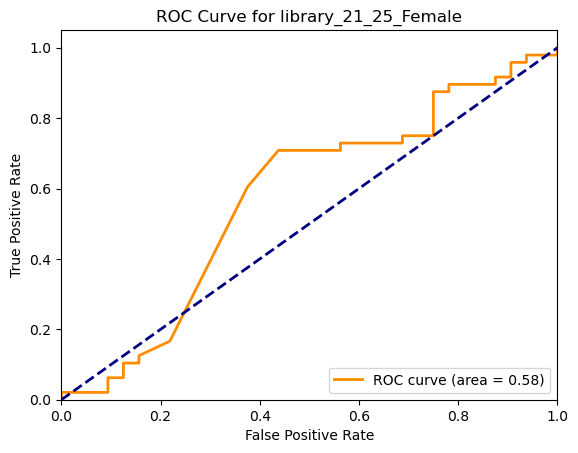

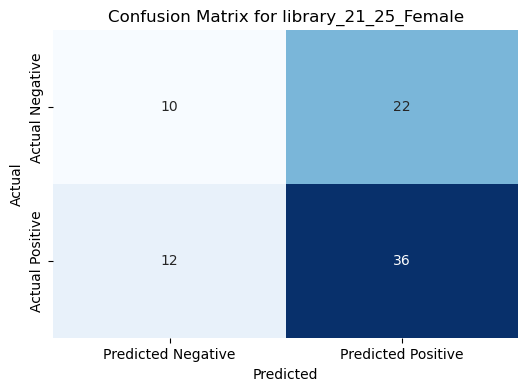

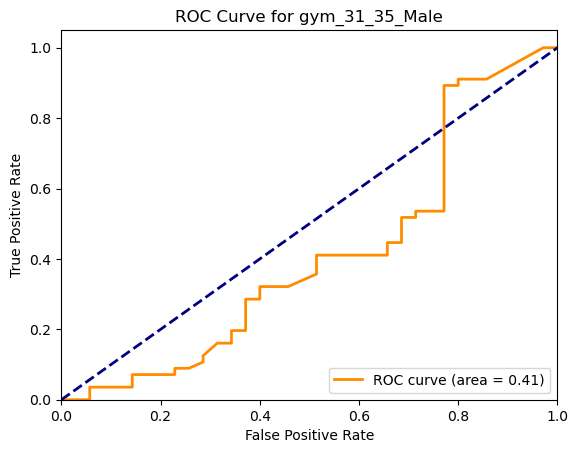

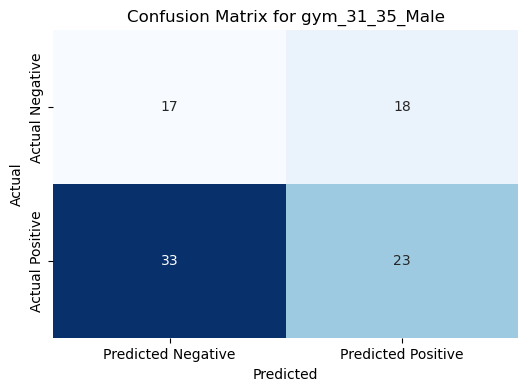

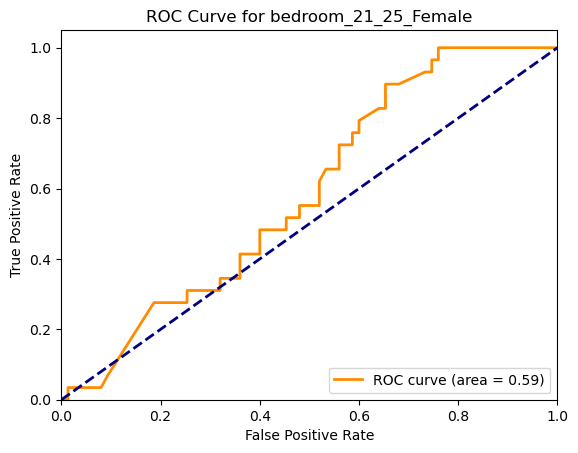

...

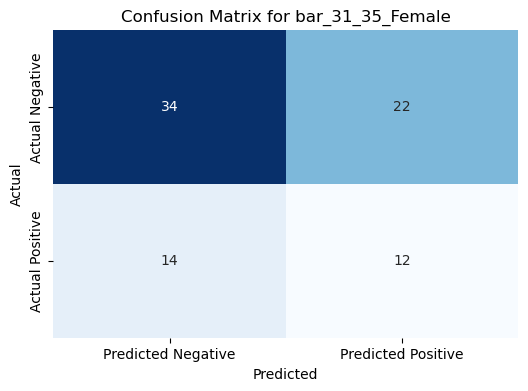

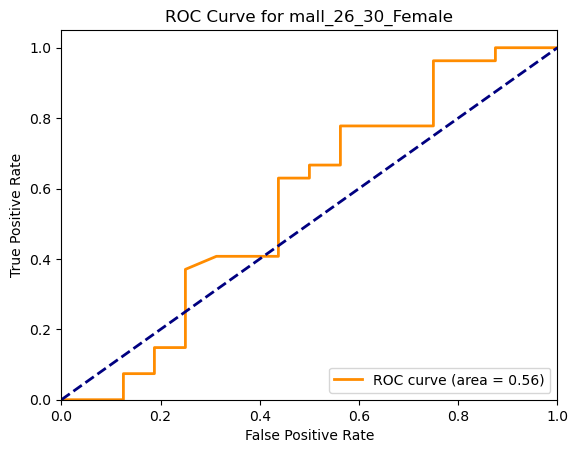

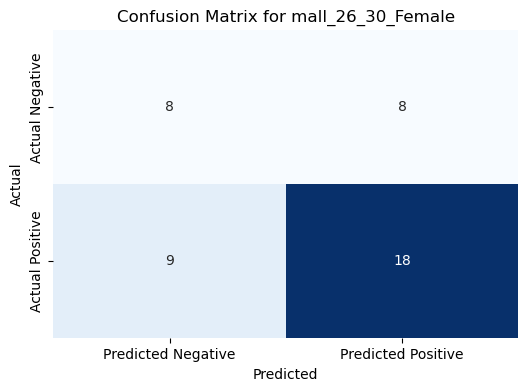

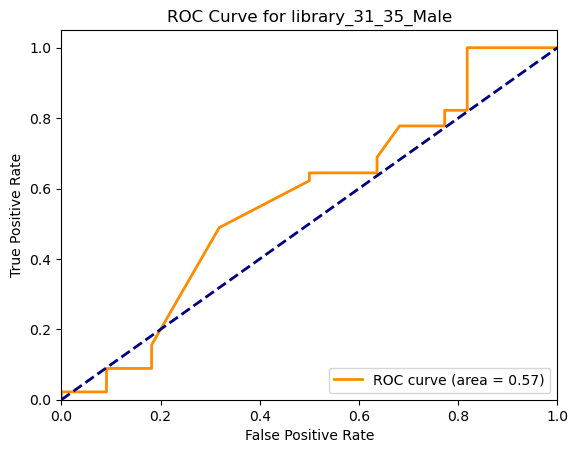

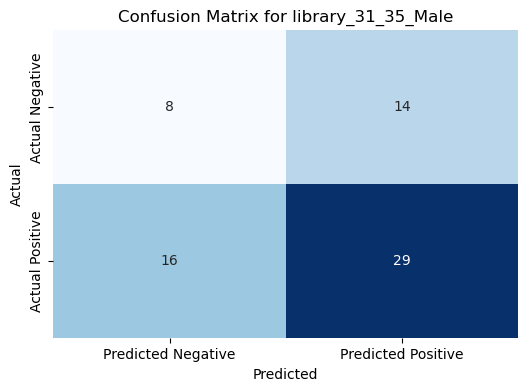

In [47]:
metrics_distilroberta_valD, results_distilroberta_valD = evaluate_model_by_group(X_val_distilroberta, y_val, 'text_distilroberta', target_group_val_split, best_model_distilroberta, k=20)


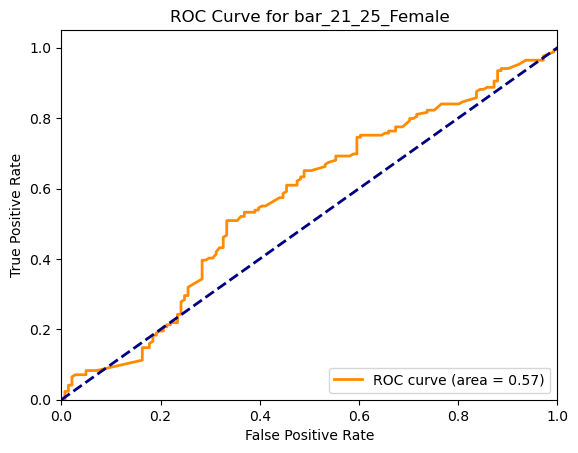

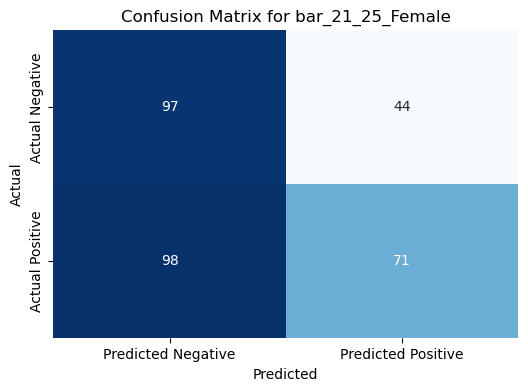

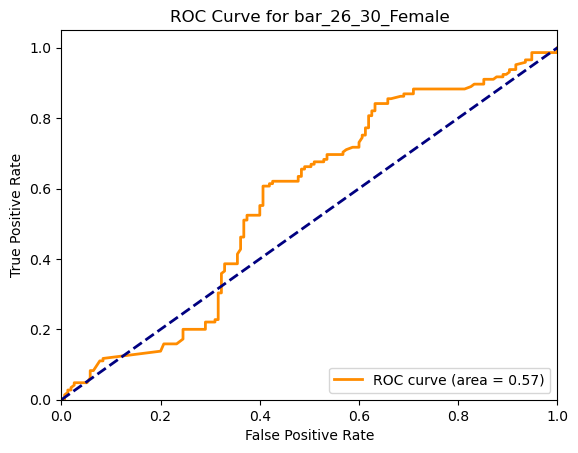

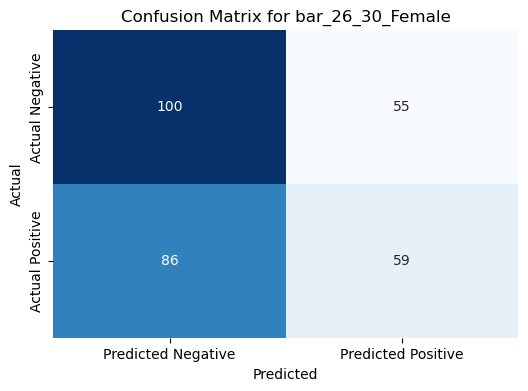

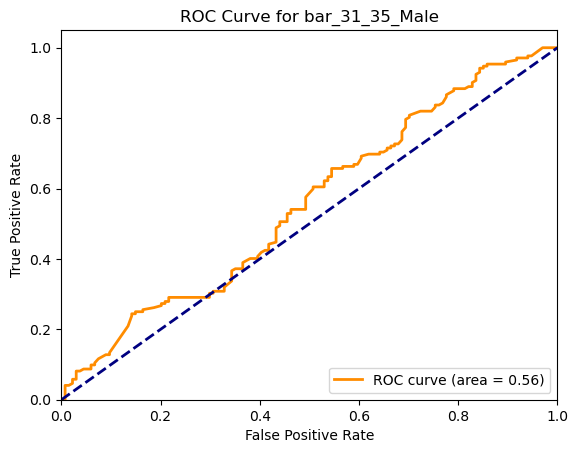

...

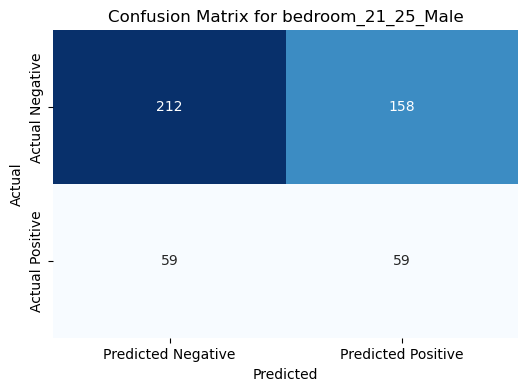

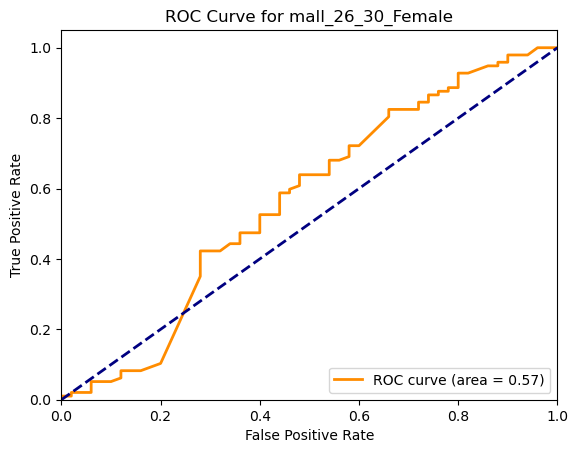

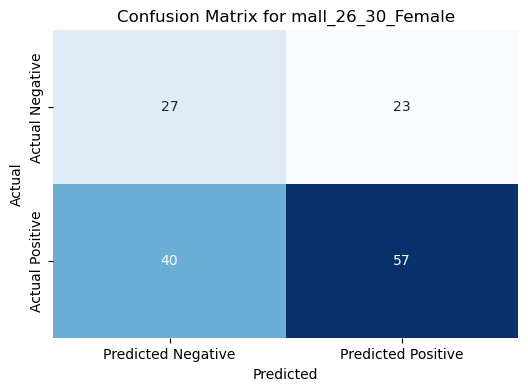

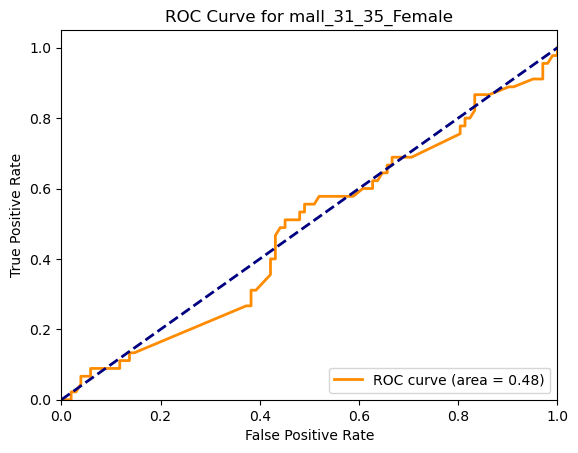

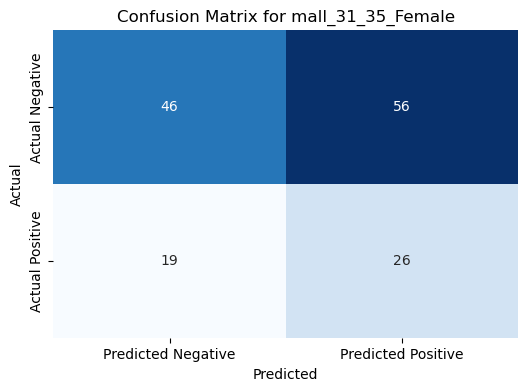

In [48]:
metrics_distilroberta_trainD, results_distilroberta_trainD  = evaluate_model_by_group(X_train_distilroberta_train, y_train_train, 'text_distilroberta', target_group_train_split, best_model_distilroberta, k=20)


In [159]:
print('Mean Precision score for Hyperparameter Tuning Best Model for Distilroberta:',metrics_distilroberta_trainD['precision_score'].mean())
print('Mean Precision score for Hyperparameter Tuning Best Model for Distilroberta:', metrics_distilroberta_valD['precision_score'].mean())

Mean Precision score for Hyperparameter Tuning Best Model for Distilroberta: 0.6406249999999999
Mean Precision score for Hyperparameter Tuning Best Model for Distilroberta: 0.5804050567595459


* Overfitting. Similar to hyperparameter in Roberta

### Distilroberta Score Summary

In [131]:
print('Baseline Model: training', metrics_distilroberta_trainA['precision_score'].mean())
print('Baseline Model: validation', metrics_distilroberta_valA['precision_score'].mean())
print('---------------------------------------')
print('Model 2: training', metrics_distilroberta_trainB['precision_score'].mean())
print('Model 2: validation', metrics_distilroberta_valB['precision_score'].mean())
print('---------------------------------------')
print('Model 3: training', metrics_distilroberta_trainC['precision_score'].mean())
print('Model 3: validation', metrics_distilroberta_valC['precision_score'].mean())
print('---------------------------------------')
print('Best Hyperparameter Model: training', metrics_distilroberta_trainD['precision_score'].mean())
print('Best Hyperparameter Model: validation', metrics_distilroberta_valD['precision_score'].mean())

Baseline Model: training 0.5906250000000001
Baseline Model: validation 0.55625
---------------------------------------
Model 2: training 0.5906250000000001
Model 2: validation 0.55625
---------------------------------------
Model 3: training 0.5791666666666667
Model 3: validation 0.5572916666666666
---------------------------------------
Best Hyperparameter Model: training 0.6406249999999999
Best Hyperparameter Model: validation 0.5804050567595459


## Distilroberta mitch

### Baseline Model

In [49]:
baseline_model_distilroberta_mitchA, _, _ = lda_sgd_pipeline(X_train_distilroberta_mitch_train, y_train_train, 'text_distilroberta_mitch')


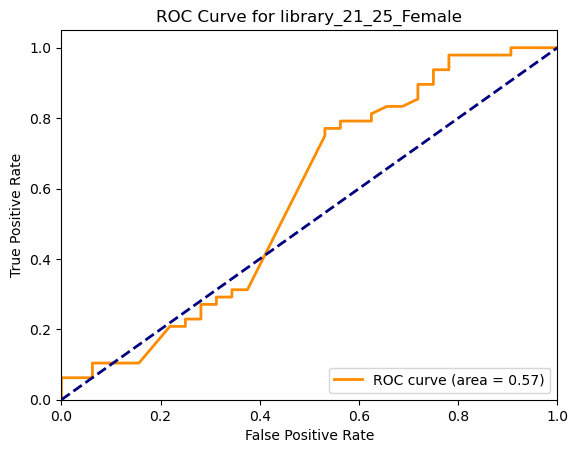

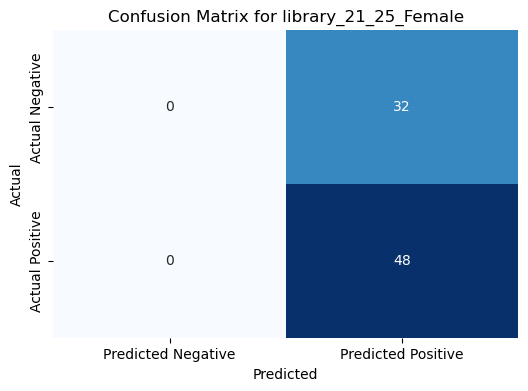

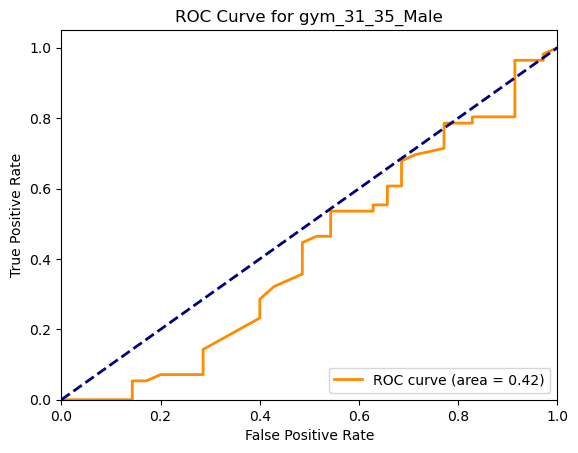

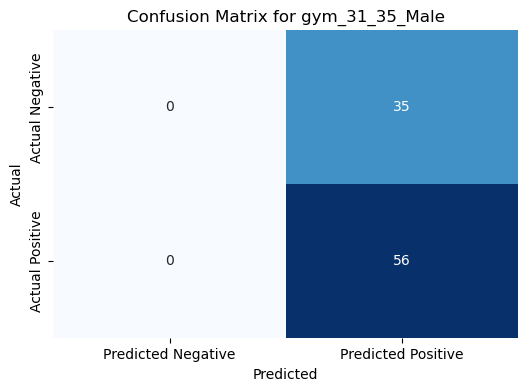

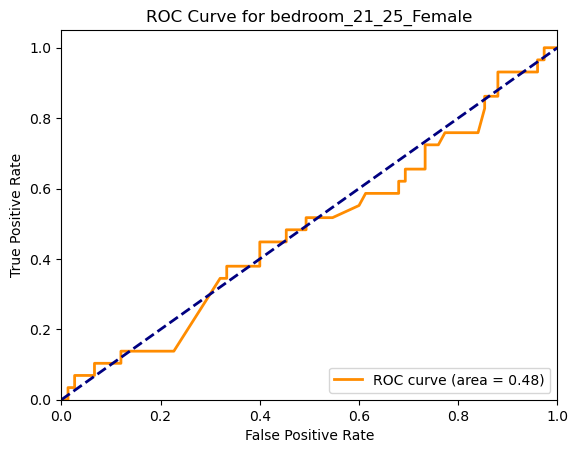

...

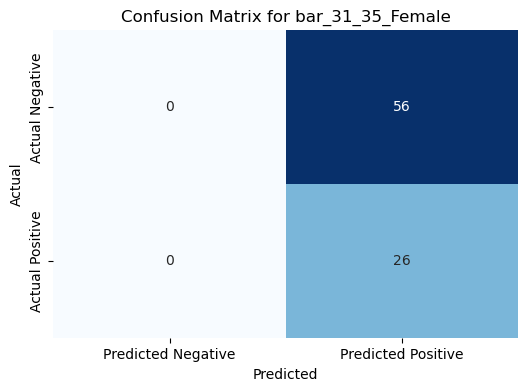

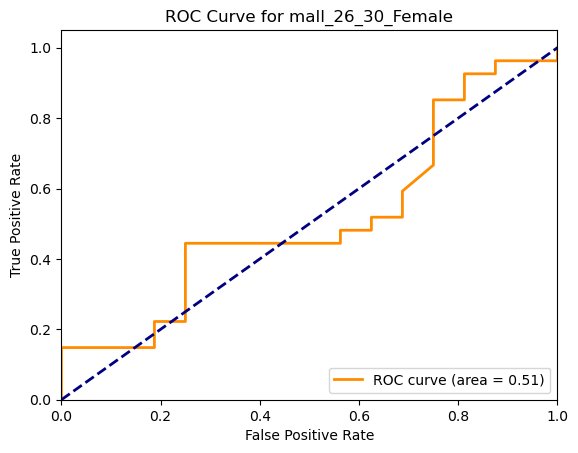

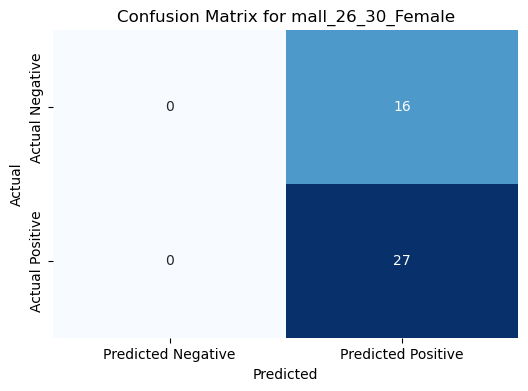

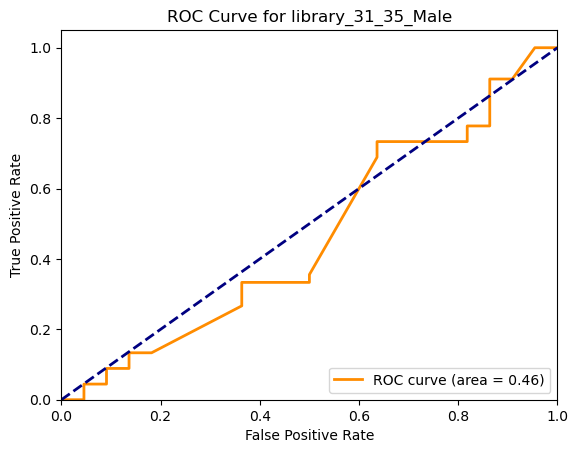

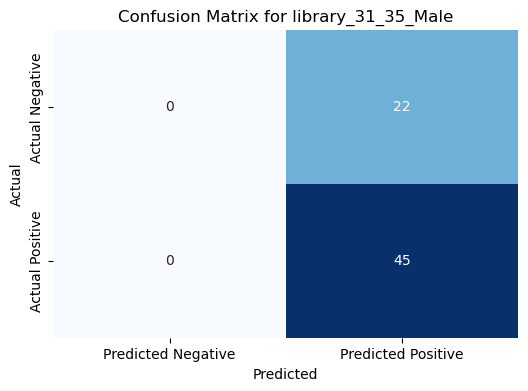

In [58]:
metrics_distilroberta_mitch_valA, results_distilroberta_mitch_valA = evaluate_model_by_group(X_val_distilroberta_mitch,
                                                                                             y_val,
                                                                                             'text_distilroberta_mitch', 
                                                                                             target_group_val_split,
                                                                                             baseline_model_distilroberta_mitchA,
                                                                                             k=20)


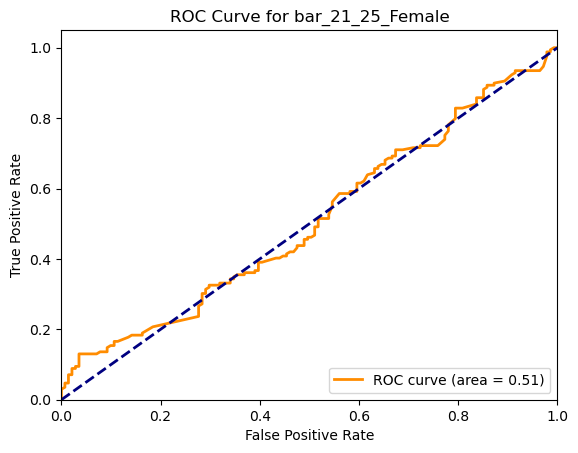

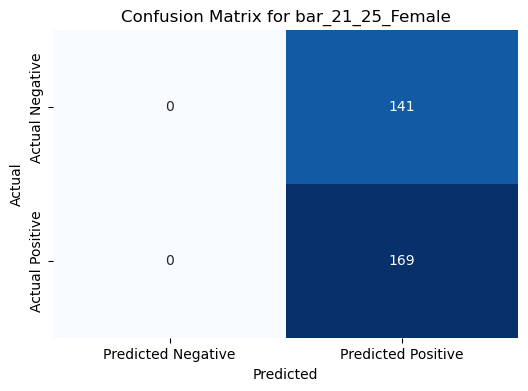

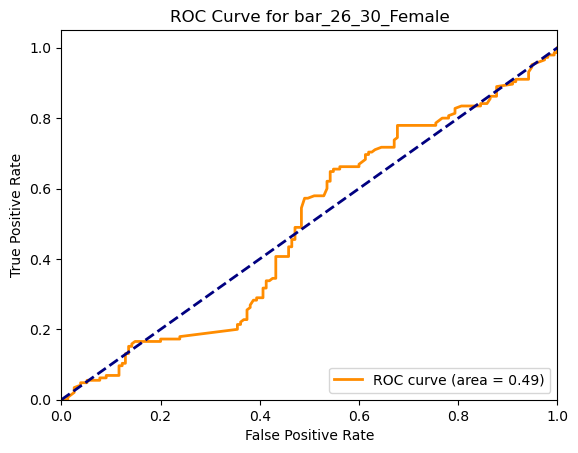

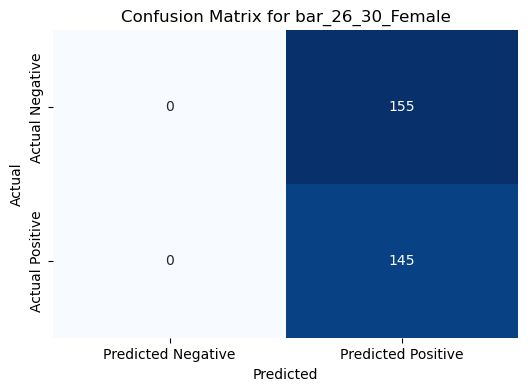

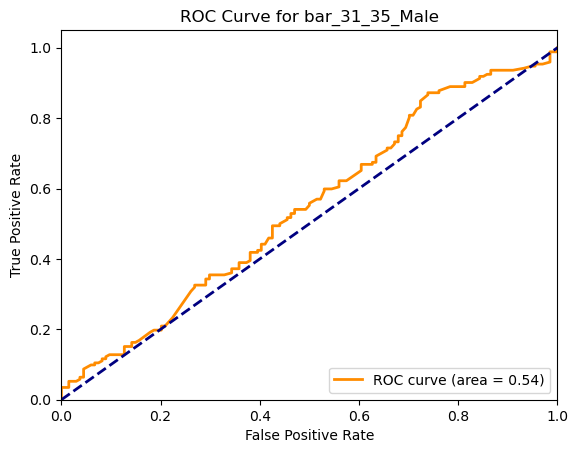

...

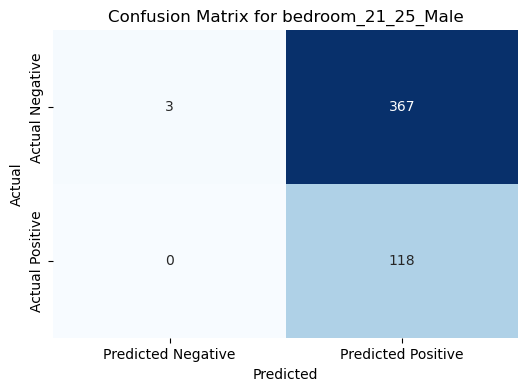

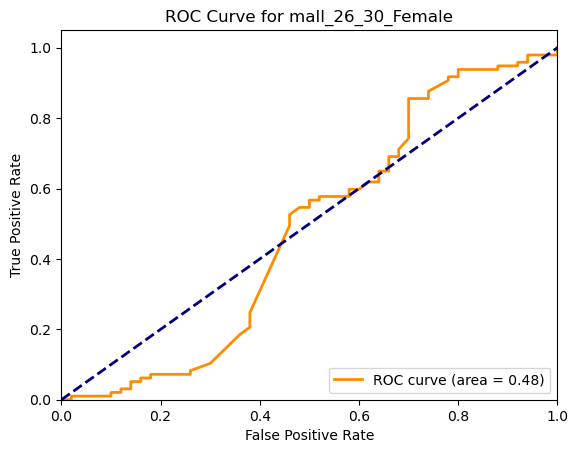

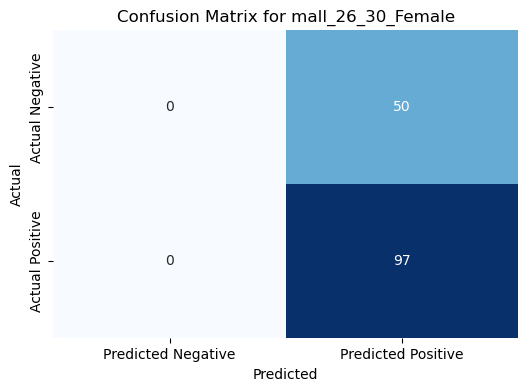

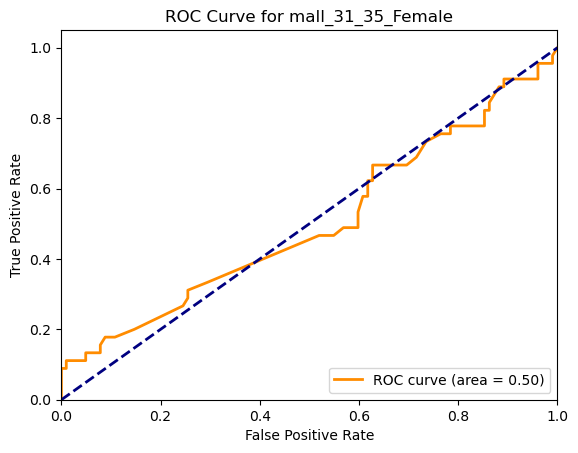

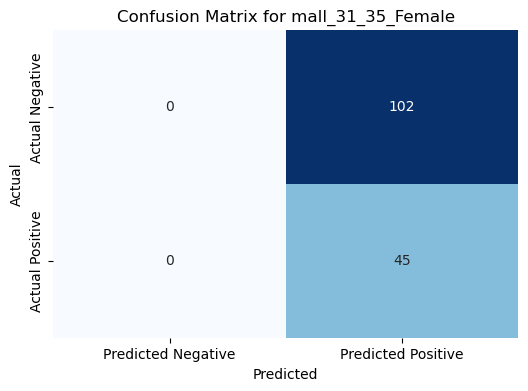

In [59]:
metrics_distilroberta_mitch_trainA, results_distilroberta_mitch_trainA  = evaluate_model_by_group(X_train_distilroberta_mitch_train,
                                                                                                  y_train_train,
                                                                                                  'text_distilroberta_mitch',
                                                                                                  target_group_train_split,
                                                                                                  baseline_model_distilroberta_mitchA,
                                                                                                  k=20)


In [160]:
print('Mean Precision score for Baseline Model on Distilroberta Mitch Training Set:', metrics_distilroberta_mitch_trainA['precision_score'].mean())
print('Mean Precision score for Baseline Model on Distilroberta Mitch Validation Set:', metrics_distilroberta_mitch_valA['precision_score'].mean())

Mean Precision score for Baseline Model on Distilroberta Mitch Training Set: 0.5629710286100263
Mean Precision score for Baseline Model on Distilroberta Mitch Validation Set: 0.5565811130034142


* The baseline model overfitted to the distilroberta

### Second Model: L2 Regularisation

In [52]:
model_distilroberta_mitchB, _, _ = lda_sgd_pipeline2(X_train_distilroberta_mitch_train, 
                                                     y_train_train, 
                                                     'text_distilroberta_mitch')

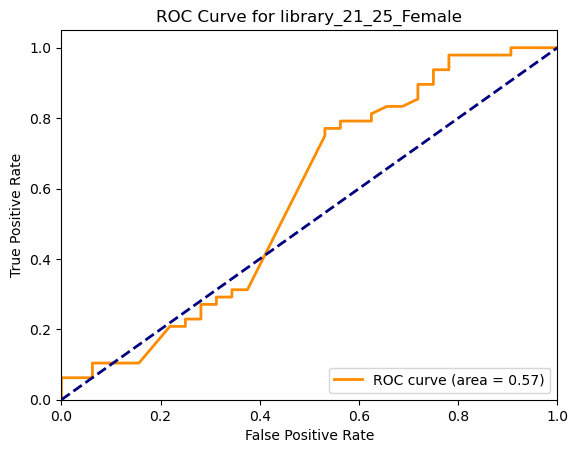

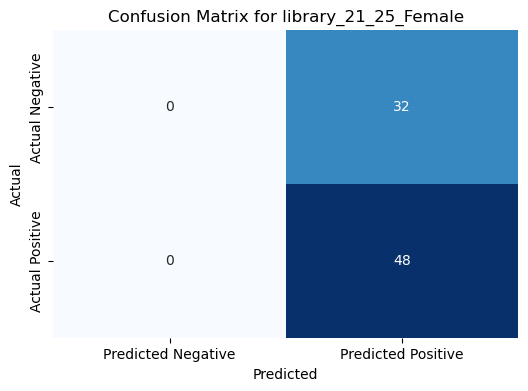

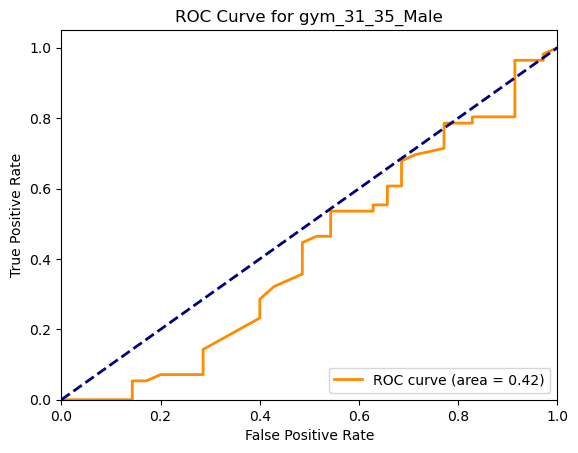

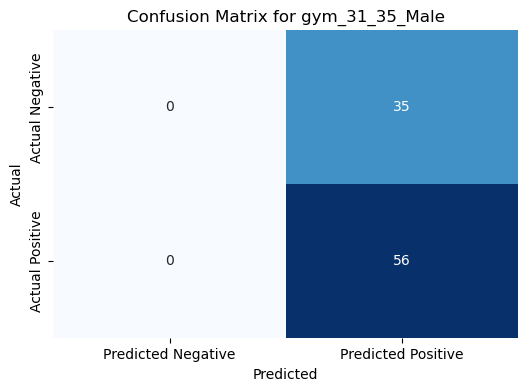

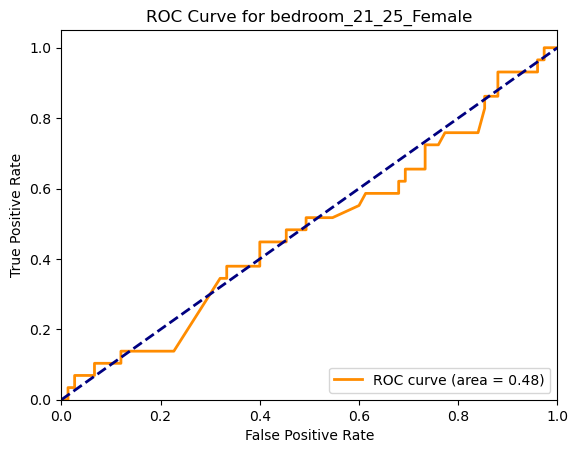

...

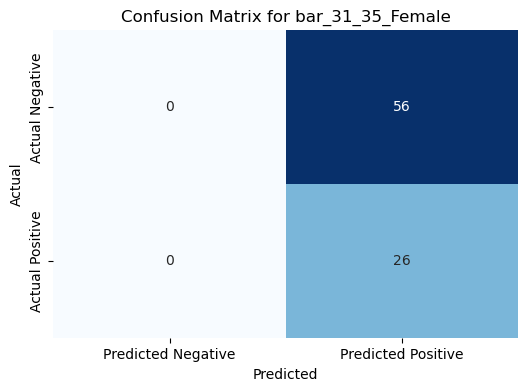

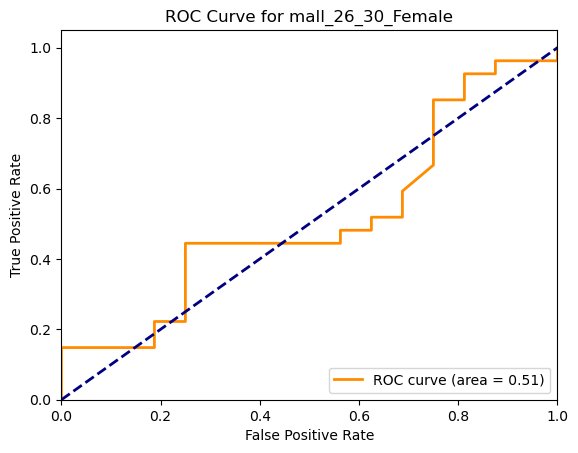

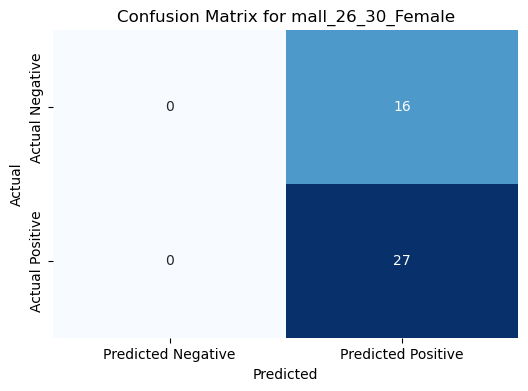

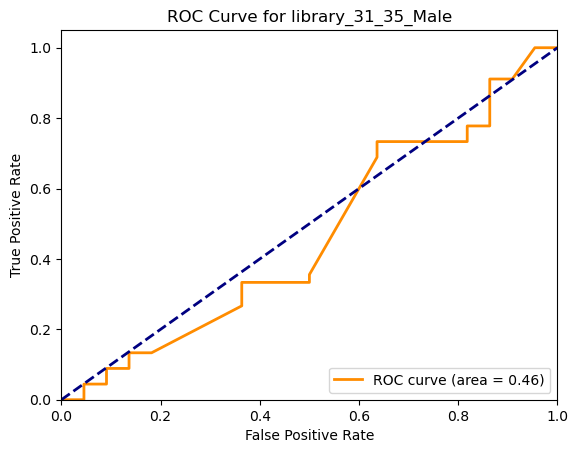

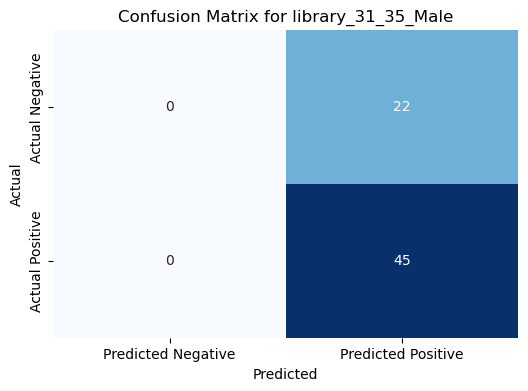

In [60]:
metrics_distilroberta_mitch_valB, results_distilroberta_mitch_valB = evaluate_model_by_group(X_val_distilroberta_mitch,
                                                                                             y_val,
                                                                                             'text_distilroberta_mitch', 
                                                                                             target_group_val_split,
                                                                                             model_distilroberta_mitchB,
                                                                                             k=20)


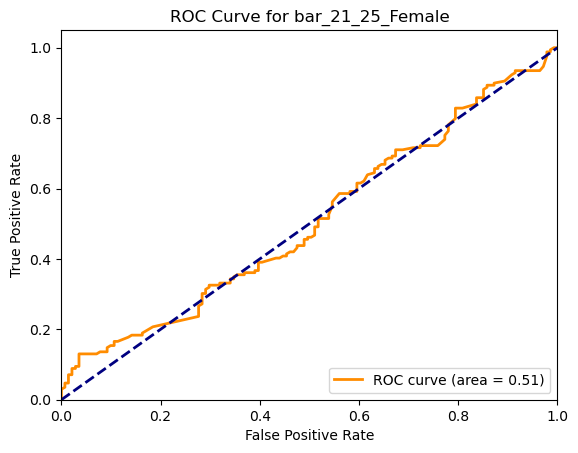

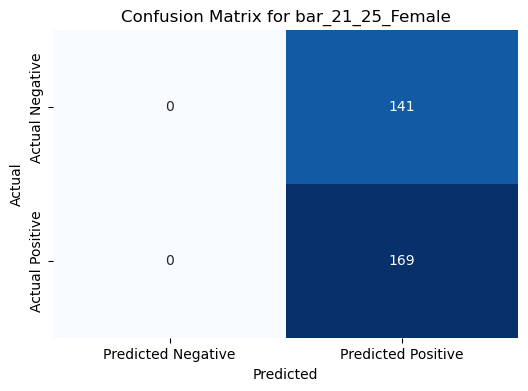

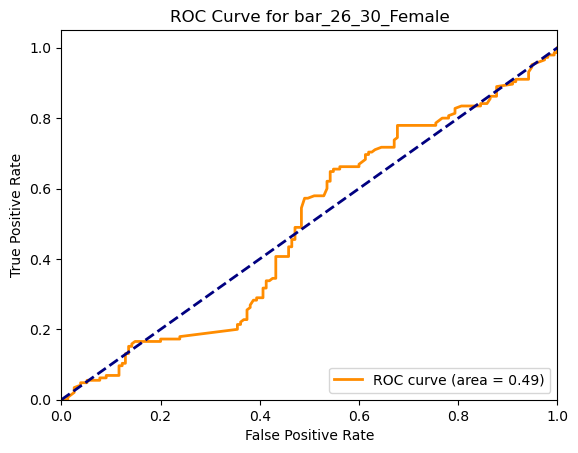

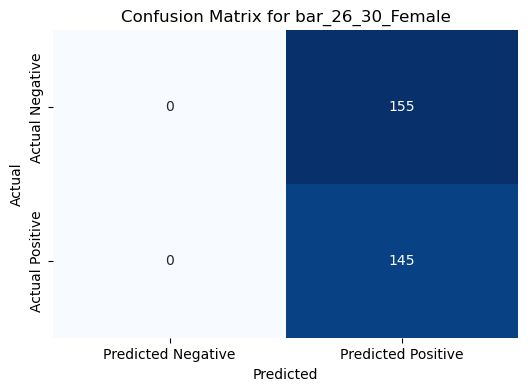

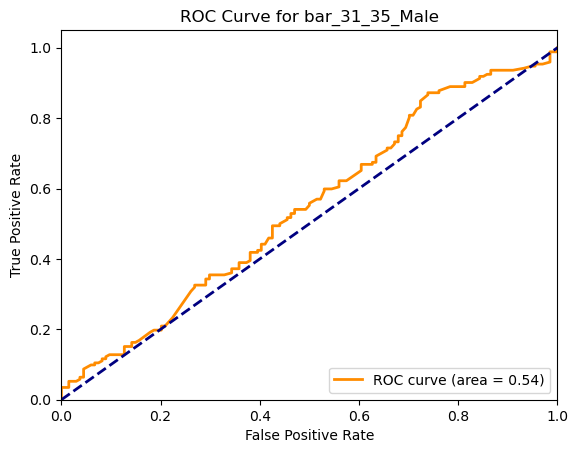

...

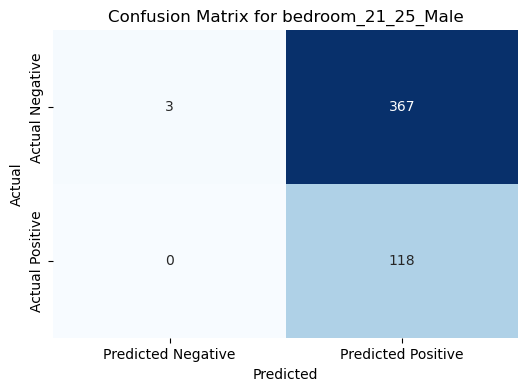

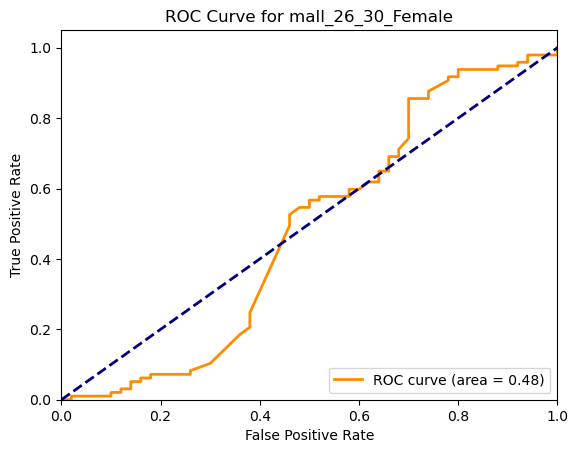

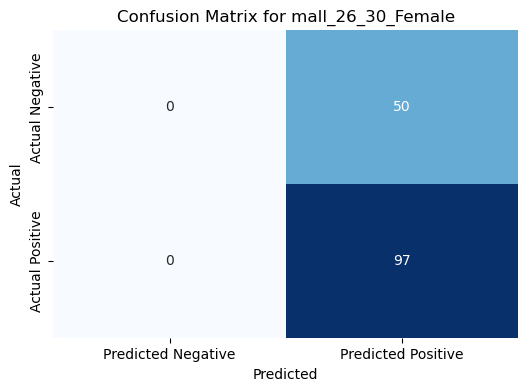

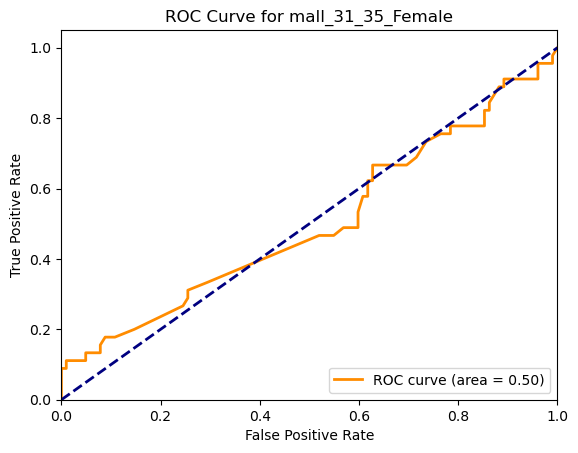

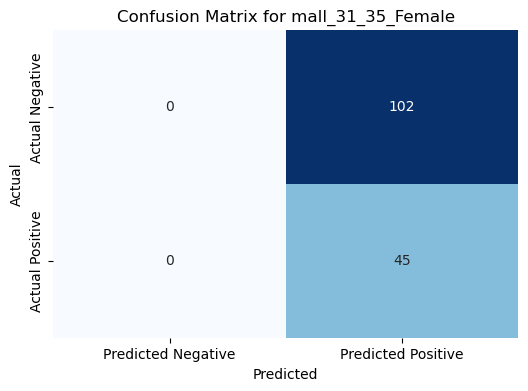

In [55]:
metrics_distilroberta_mitch_trainB, results_distilroberta_mitch_trainB  = evaluate_model_by_group(X_train_distilroberta_mitch_train,
                                                                                                  y_train_train,
                                                                                                  'text_distilroberta_mitch',
                                                                                                  target_group_train_split,
                                                                                                  model_distilroberta_mitchB,
                                                                                                  k=20)


In [161]:
print('Mean Precision score for Second Model with L2 regularisation on Distilroberta Mitch Training Set:', metrics_distilroberta_mitch_trainB['precision_score'].mean())
print('Mean Precision score for Second Model with L2 regularisation on Distilroberta Mitch Validation Set:', metrics_distilroberta_mitch_valB['precision_score'].mean())

Mean Precision score for Second Model with L2 regularisation on Distilroberta Mitch Training Set: 0.61875
Mean Precision score for Second Model with L2 regularisation on Distilroberta Mitch Validation Set: 0.5750000000000001


### Third Model: Early stopping added

In [56]:
model_distilroberta_mitchC, _, _ = lda_sgd_pipeline3(X_train_distilroberta_mitch_train, 
                                                     y_train_train, 
                                                     'text_distilroberta_mitch')

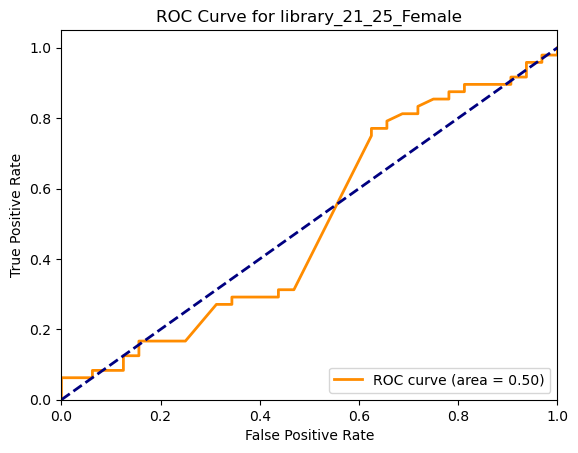

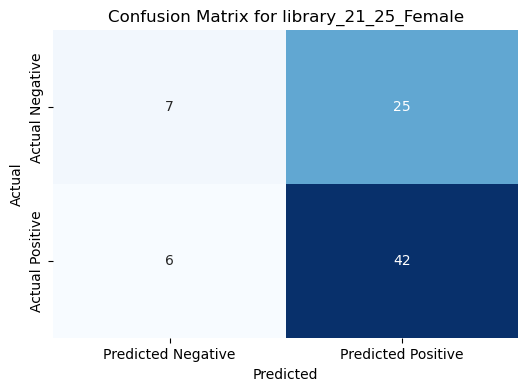

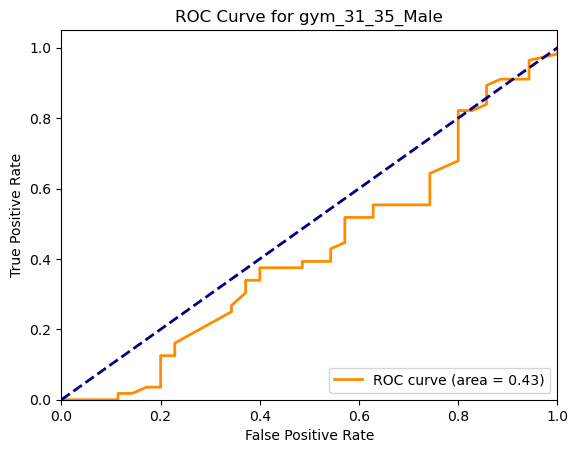

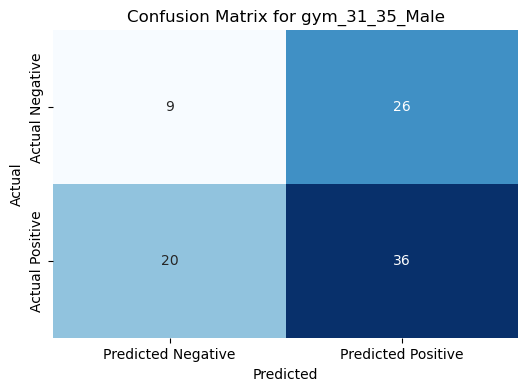

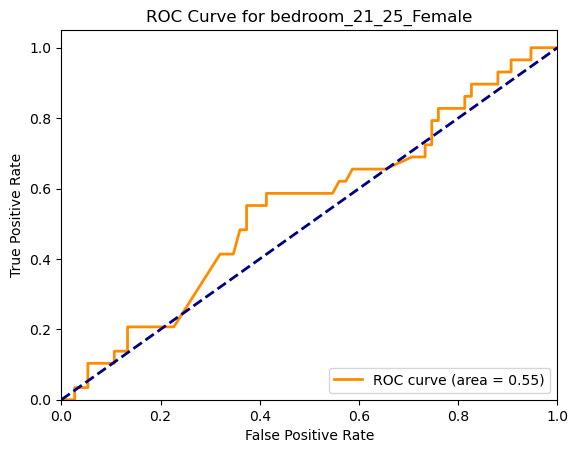

...

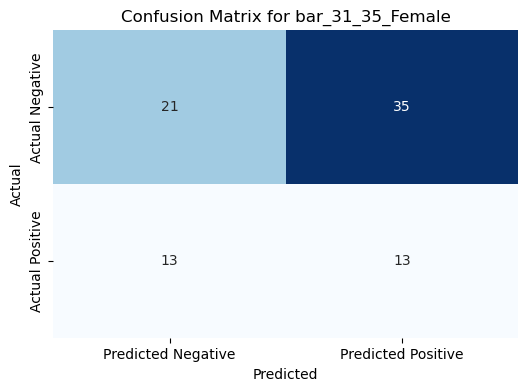

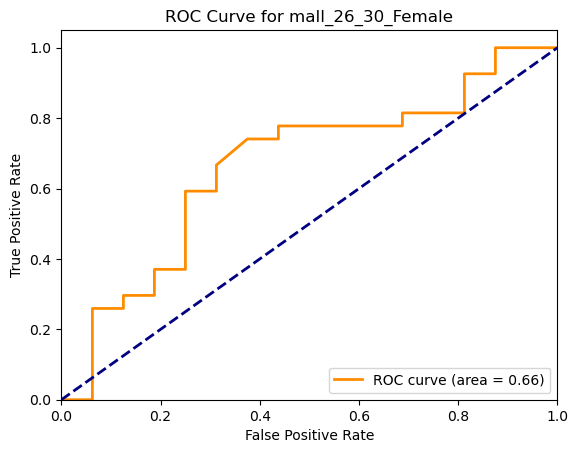

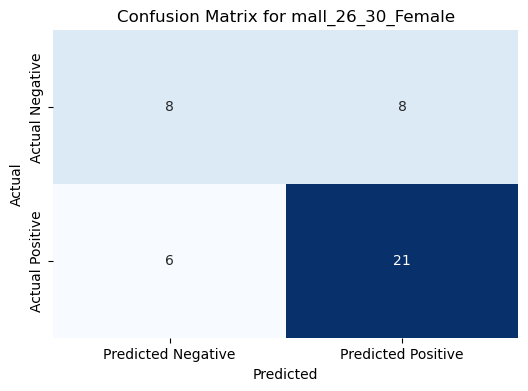

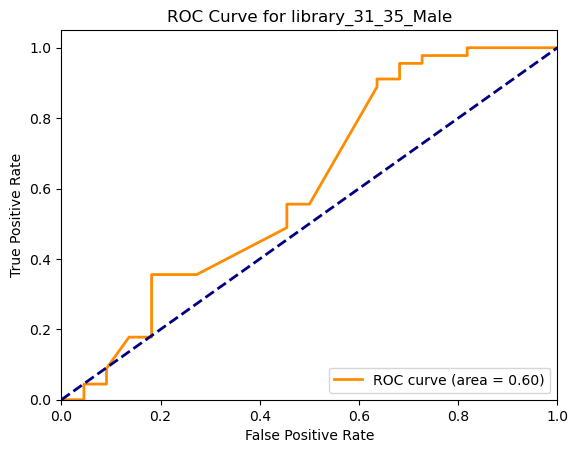

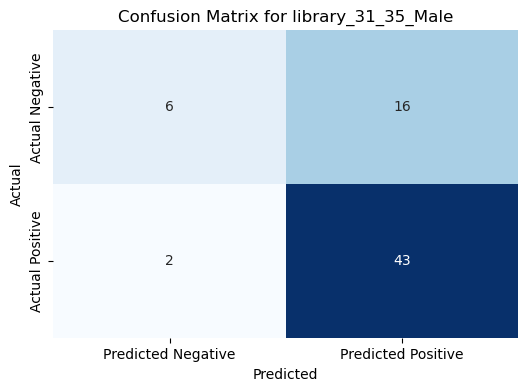

In [61]:
metrics_distilroberta_mitch_valC, results_distilroberta_mitch_valC = evaluate_model_by_group(X_val_distilroberta_mitch,
                                                                                             y_val,
                                                                                             'text_distilroberta_mitch', 
                                                                                             target_group_val_split,
                                                                                             model_distilroberta_mitchC,
                                                                                             k=20)


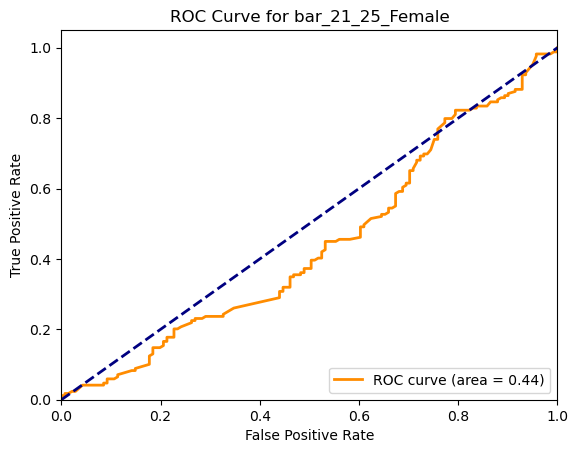

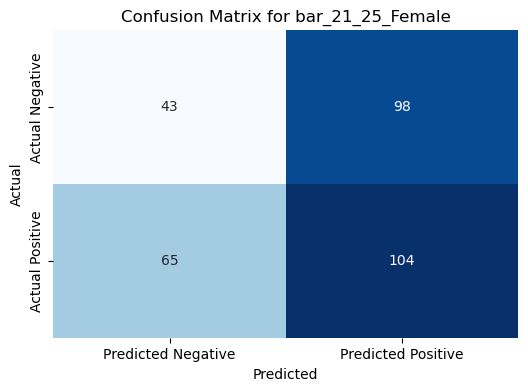

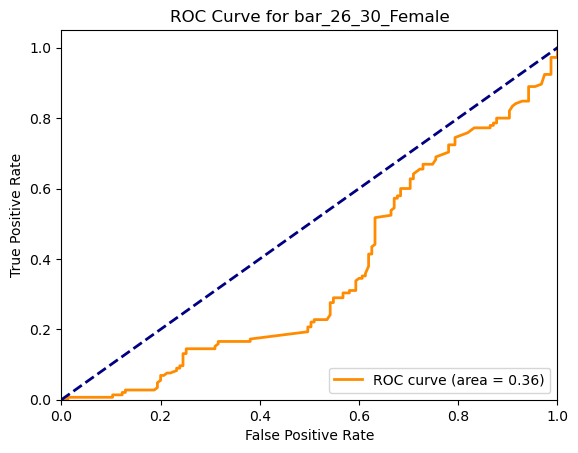

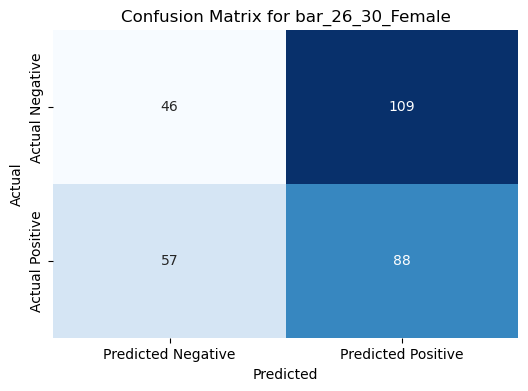

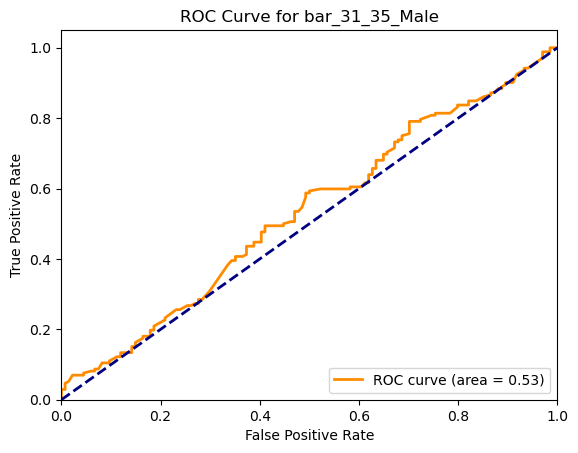

...

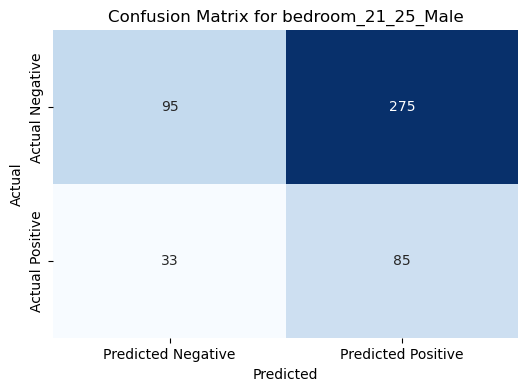

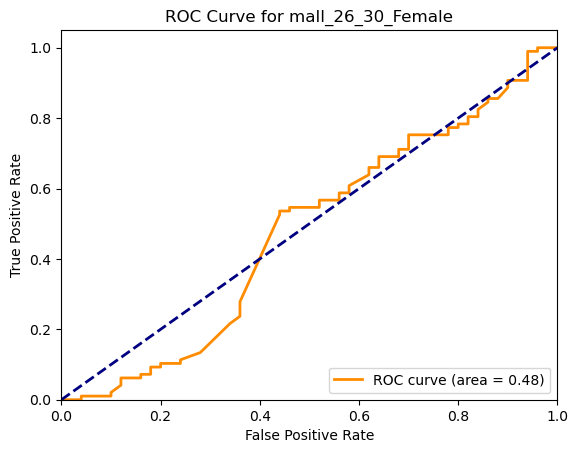

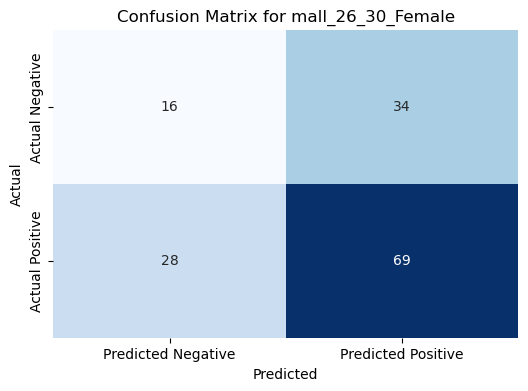

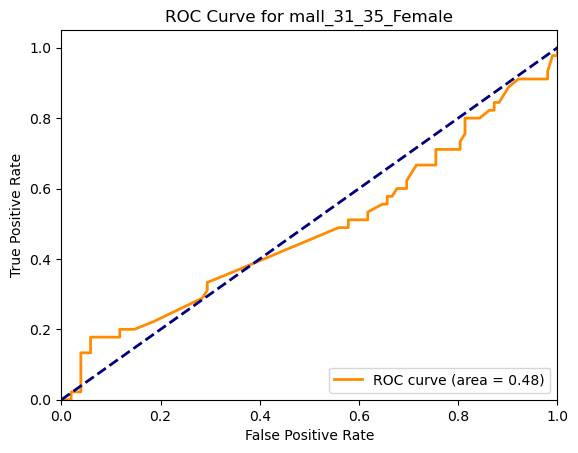

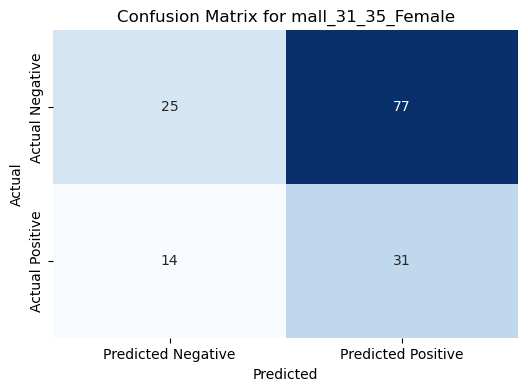

In [57]:
metrics_distilroberta_mitch_trainC, results_distilroberta_mitch_trainC  = evaluate_model_by_group(X_train_distilroberta_mitch_train, 
                                                                                                  y_train_train,
                                                                                                  'text_distilroberta_mitch',
                                                                                                  target_group_train_split, 
                                                                                                  model_distilroberta_mitchC,
                                                                                                  k=20)


In [162]:
print('Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Mitch Training Set:', metrics_distilroberta_mitch_trainC['precision_score'].mean())
print('Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Mitch Validation Set:', metrics_distilroberta_mitch_valC['precision_score'].mean())

Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Mitch Training Set: 0.5958333333333333
Mean Precision score for Third Model with L2 regularisation and early stopping on Distilroberta Mitch Validation Set: 0.5604166666666667


### Hyperparameter Tuning

In [62]:
best_model_distilroberta_mitch, best_params_distilroberta_mitch, best_score_distilroberta_mitch = lda_grid_search(X_train_distilroberta_mitch_train, y_train_train, 'text_distilroberta_mitch')


Fitting 5 folds for each of 90 candidates, totalling 450 fits
Precision: 0.550, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.01}
Precision: 0.550, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.05}
Precision: 0.551, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 5, 'lda__topic_word_prior': 0.1}
Precision: 0.548, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.01}
Precision: 0.554, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.05}
Precision: 0.552, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 25, 'lda__topic_word_prior': 0.1}
Precision: 0.561, Parameters: {'lda__doc_topic_prior': 0.05, 'lda__max_iter': 100, 'lda__n_components': 50, '

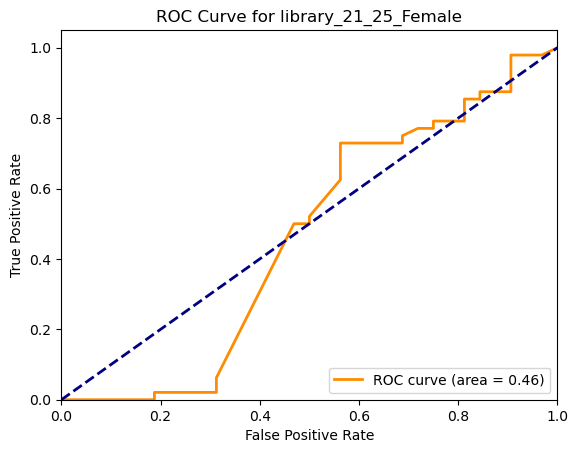

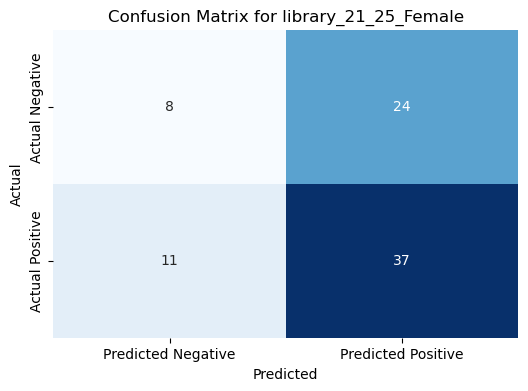

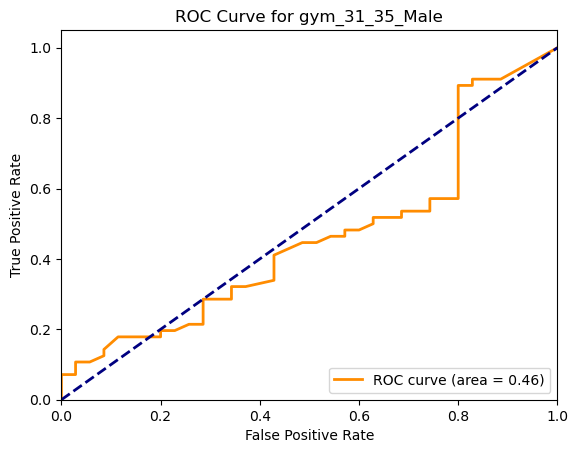

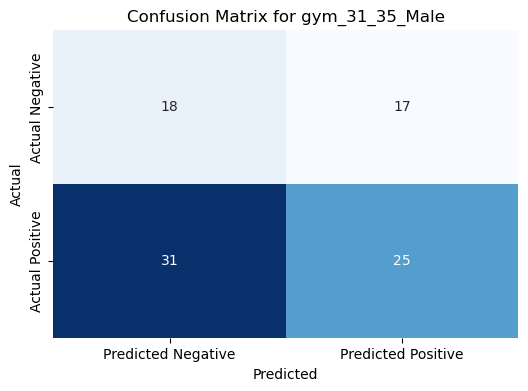

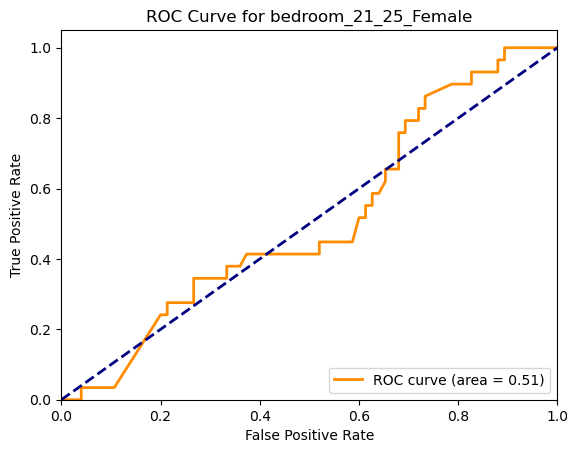

...

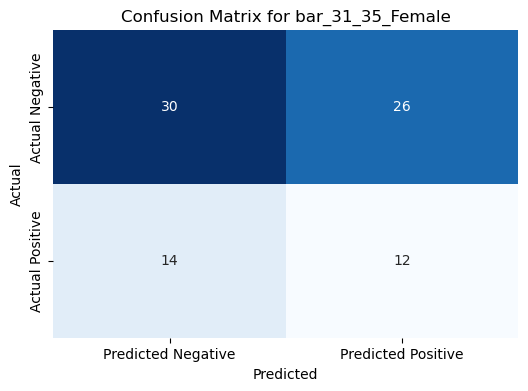

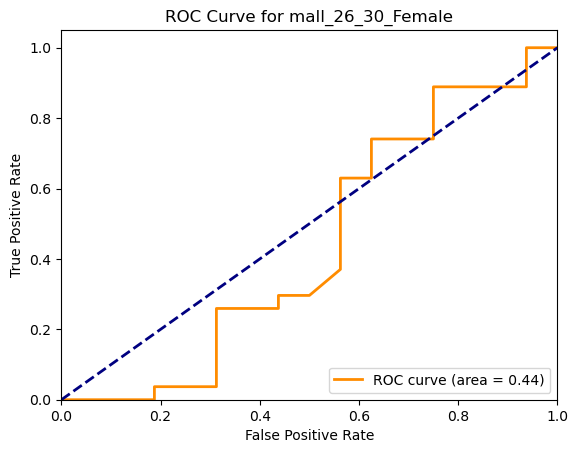

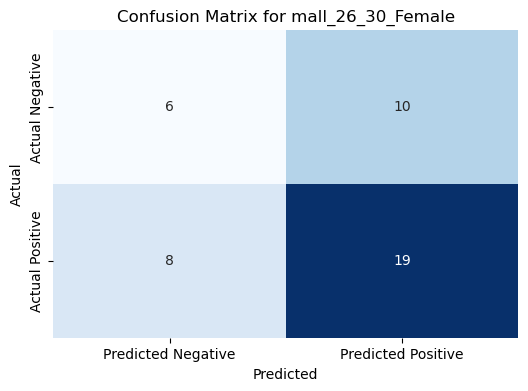

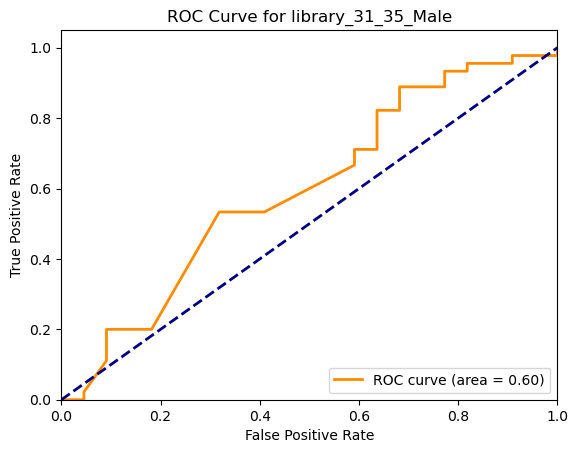

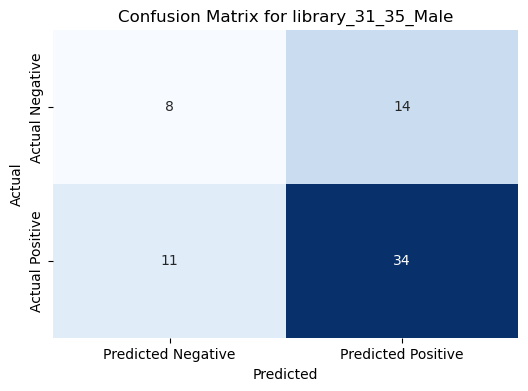

In [94]:
metrics_distilroberta_mitch_valD, results_distilroberta_mitch_valD = evaluate_model_by_group(X_val_distilroberta_mitch,
                                                                                             y_val,
                                                                                             'text_distilroberta_mitch', 
                                                                                             target_group_val_split,
                                                                                             best_model_distilroberta_mitch,
                                                                                             k=20)


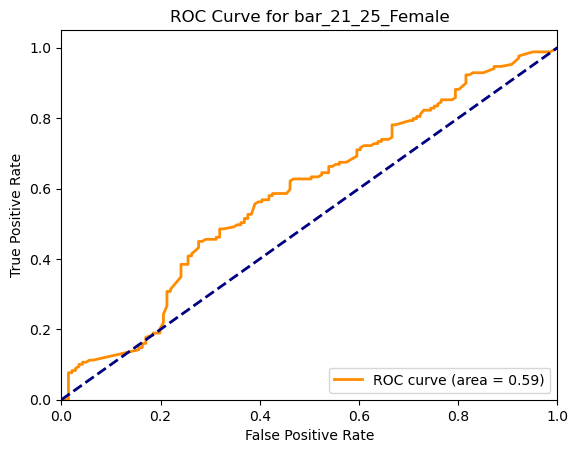

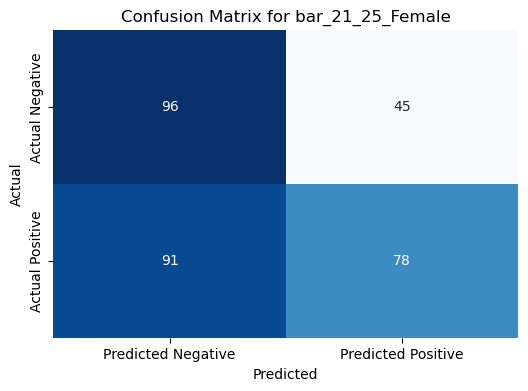

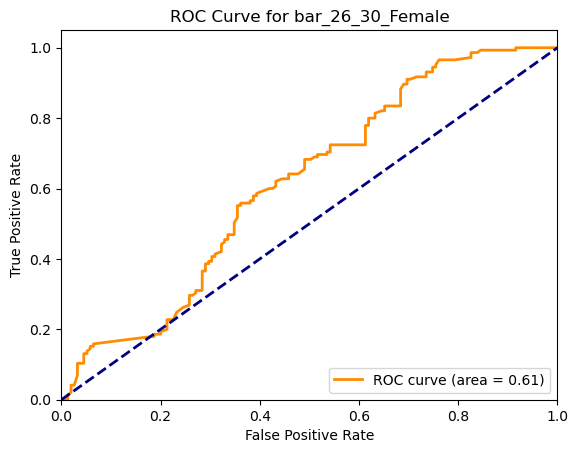

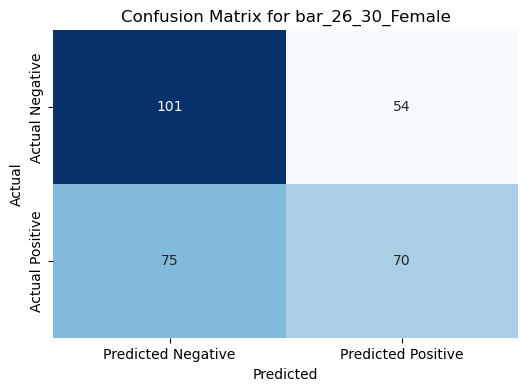

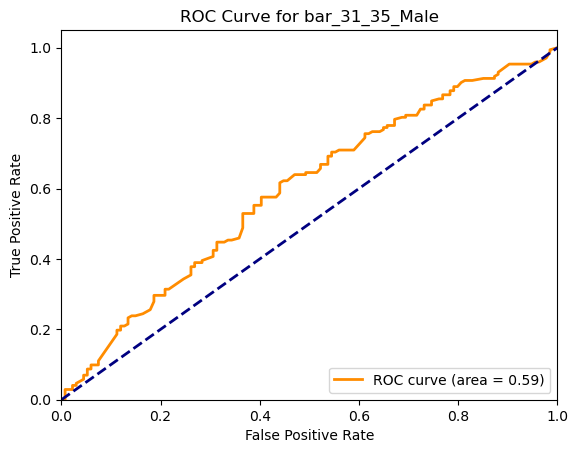

...

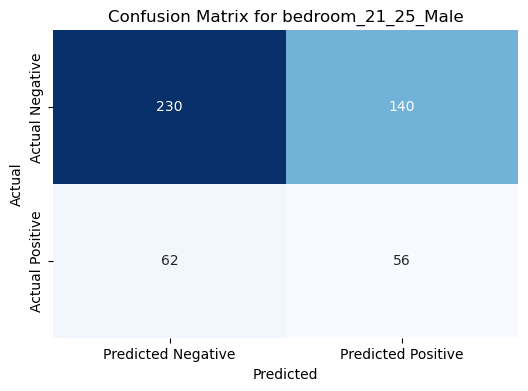

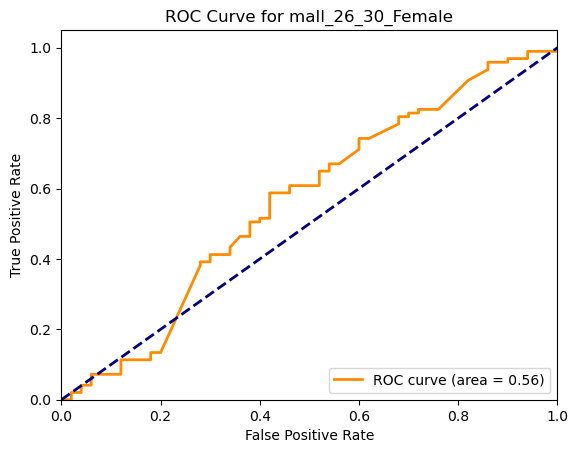

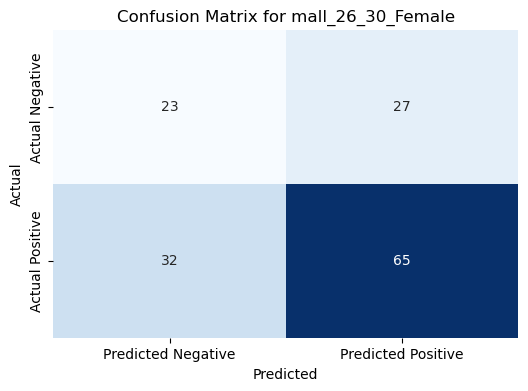

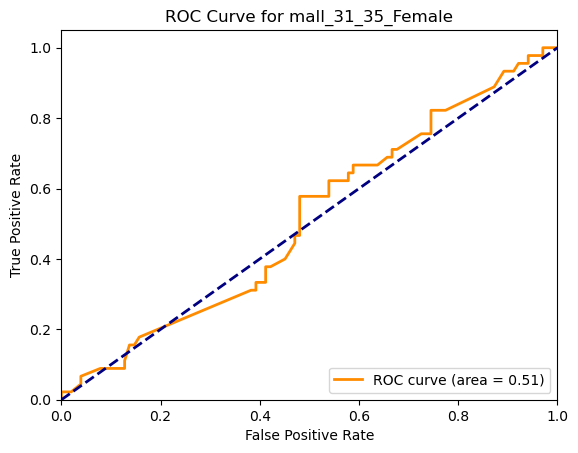

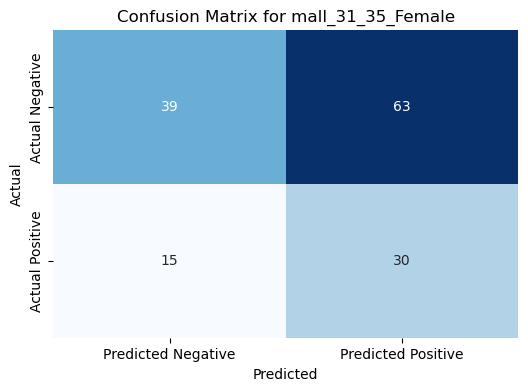

In [95]:
metrics_distilroberta_mitch_trainD, results_distilroberta_mitch_D = evaluate_model_by_group(X_train_distilroberta_mitch_train,
                                                                                             y_train_train,
                                                                                             'text_distilroberta_mitch', 
                                                                                             target_group_train_split,
                                                                                             best_model_distilroberta_mitch,
                                                                                             k=20)


In [163]:
print('Mean Precision score for Hyperparameter Tuning Best Model for Distilrobertan Mitch train:',metrics_distilroberta_mitch_trainD['precision_score'].mean())
print('Mean Precision score for Hyperparameter Tuning Best Model for Distilroberta Mitch val:',metrics_distilroberta_mitch_valD['precision_score'].mean())

Mean Precision score for Hyperparameter Tuning Best Model for Distilrobertan Mitch train: 0.6510416666666666
Mean Precision score for Hyperparameter Tuning Best Model for Distilroberta Mitch val: 0.5893518518518518


* high overfitting

### Distilroberta Mitch Score Summary

In [141]:
print('Baseline Model: training', metrics_distilroberta_mitch_trainA['precision_score'].mean())
print('Baseline Model: validation', metrics_distilroberta_mitch_valA['precision_score'].mean())
print('---------------------------------------')
print('Model 2: training', metrics_distilroberta_mitch_trainB['precision_score'].mean())
print('Model 2: validation', metrics_distilroberta_mitch_valB['precision_score'].mean())
print('---------------------------------------')
print('Model 3: training', metrics_distilroberta_mitch_trainC['precision_score'].mean())
print('Model 3: validation',metrics_distilroberta_mitch_valC['precision_score'].mean())
print('---------------------------------------')
print('Hyperparameter Best Model: training', metrics_distilroberta_mitch_trainD['precision_score'].mean())
print('Hyperparameter Best Model: validation',metrics_distilroberta_mitch_valD['precision_score'].mean())

Baseline Model: training 0.61875
Baseline Model: validation 0.5750000000000001
---------------------------------------
Model 2: training 0.61875
Model 2: validation 0.5750000000000001
---------------------------------------
Model 3: training 0.5958333333333333
Model 3: validation 0.5604166666666667
---------------------------------------
Hyperparameter Best Model: training 0.6510416666666666
Hyperparameter Best Model: validation 0.5893518518518518


# Evaluate on Test Set using most generalisable model - Model 3: L2 regularisation with early stopping

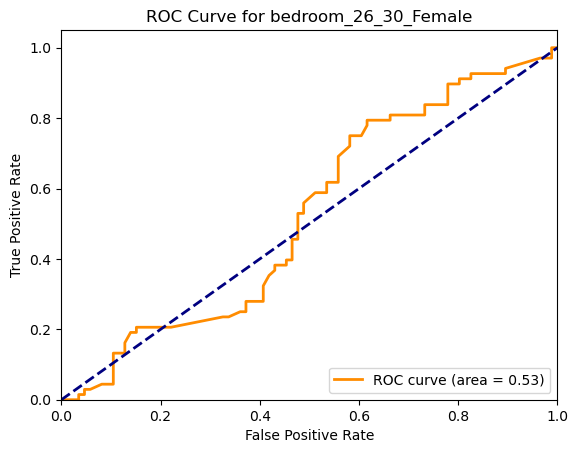

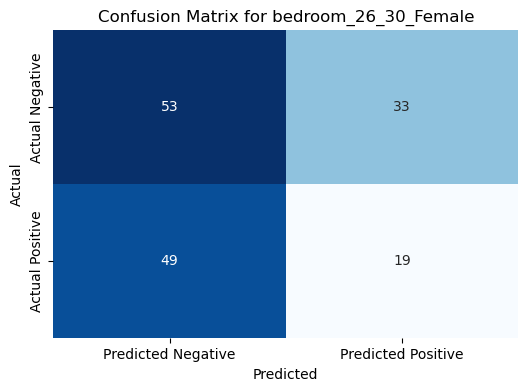

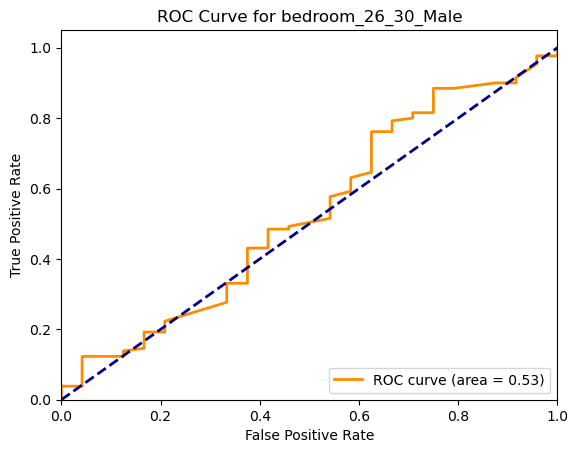

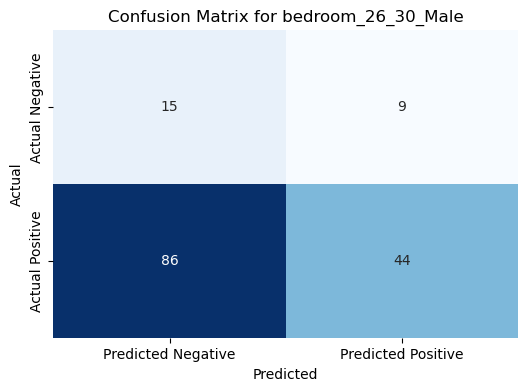

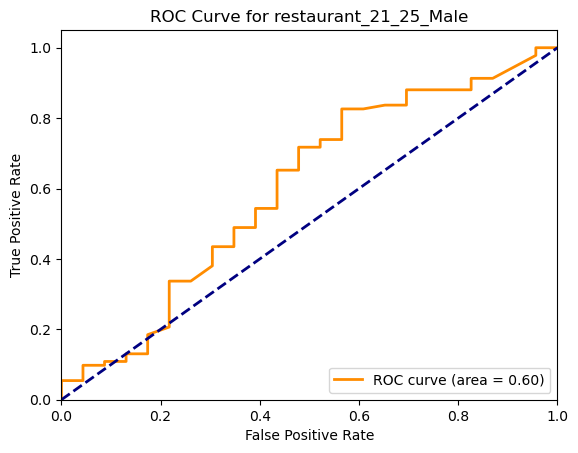

...

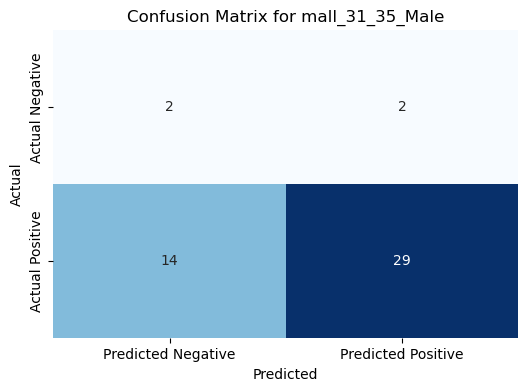

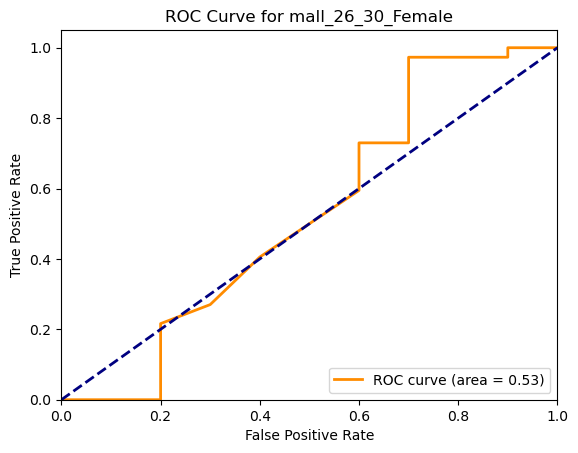

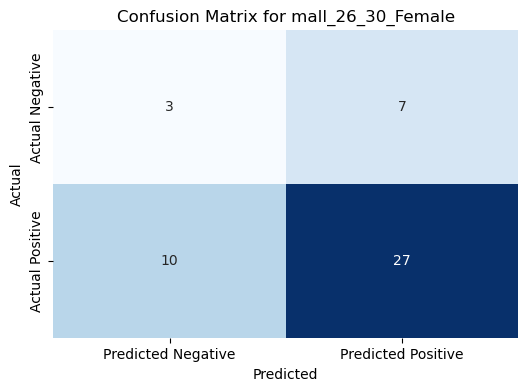

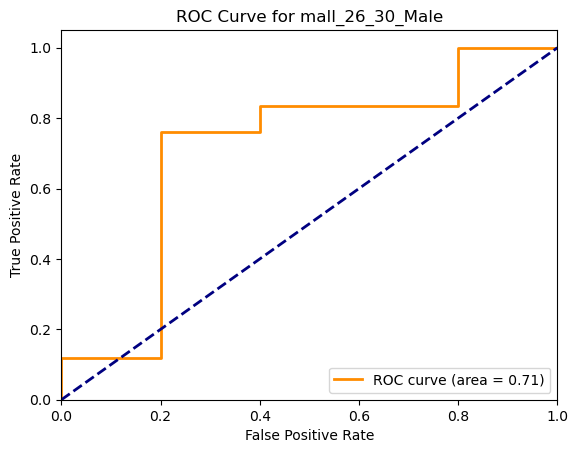

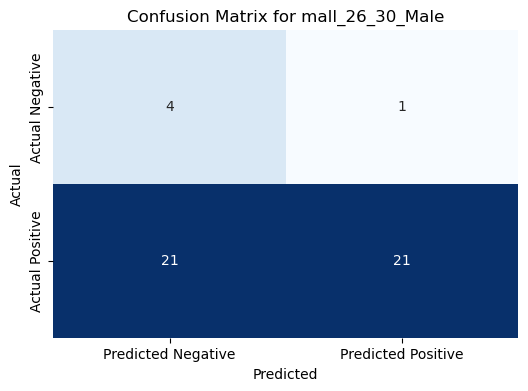

In [75]:
metrics_roberta_test, results_roberta_test = evaluate_model_by_group(X_test_roberta, y_test, 'text_roberta', target_group_test, model_roberta3, k=20)


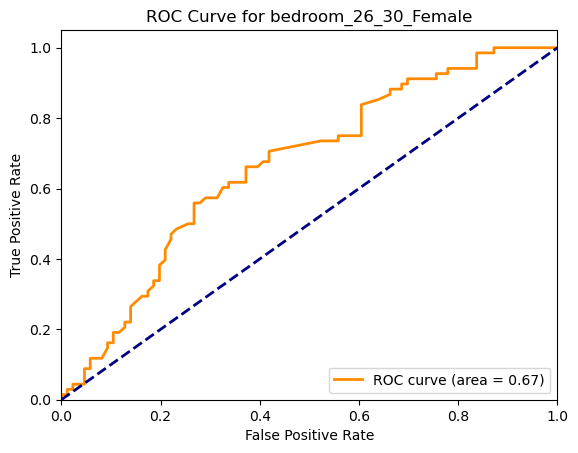

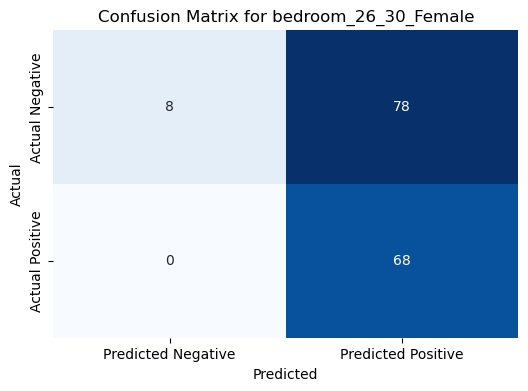

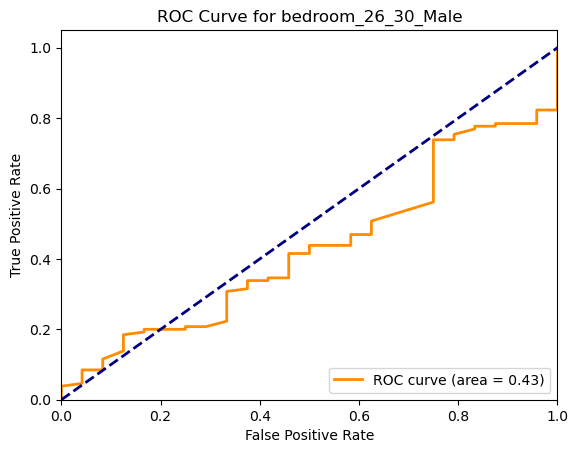

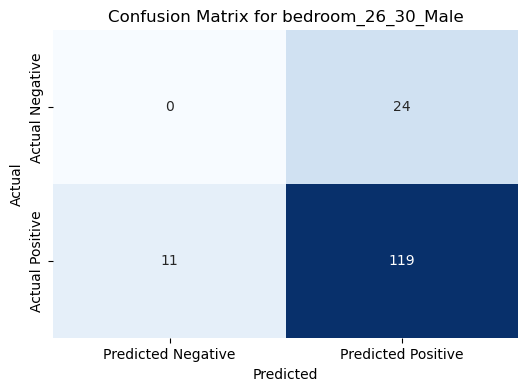

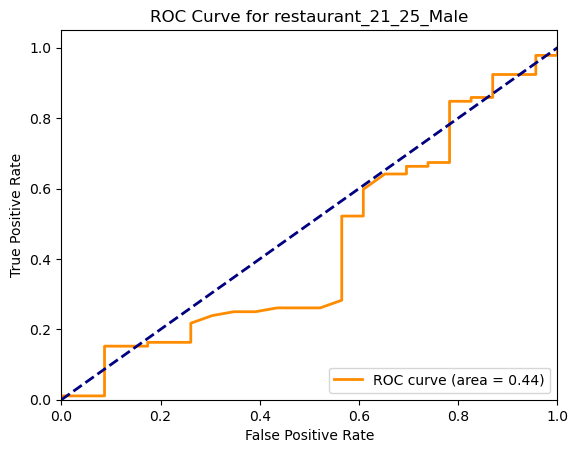

...

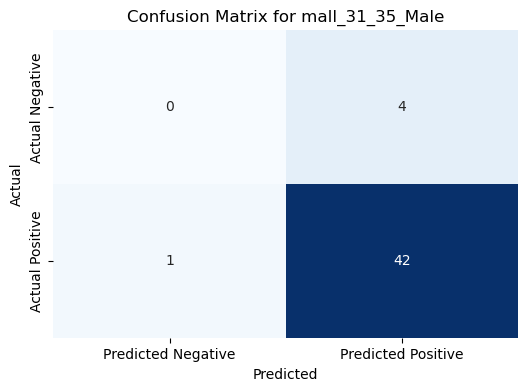

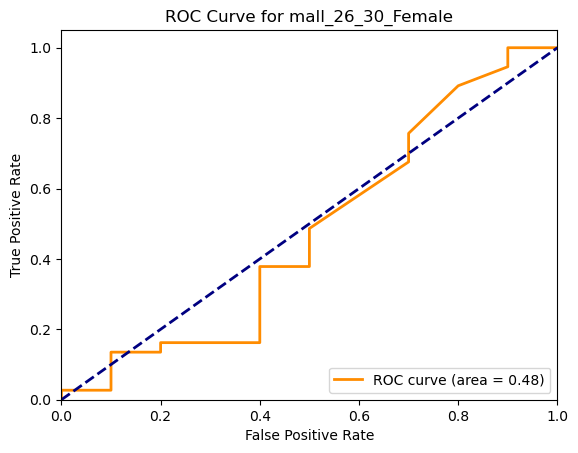

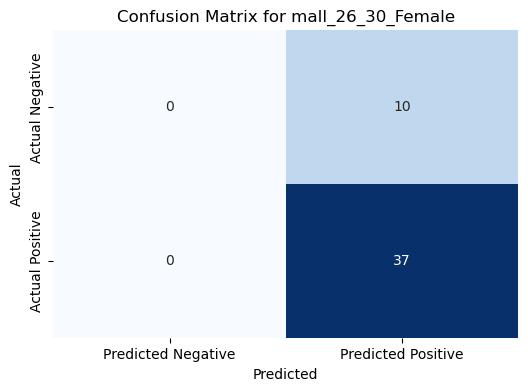

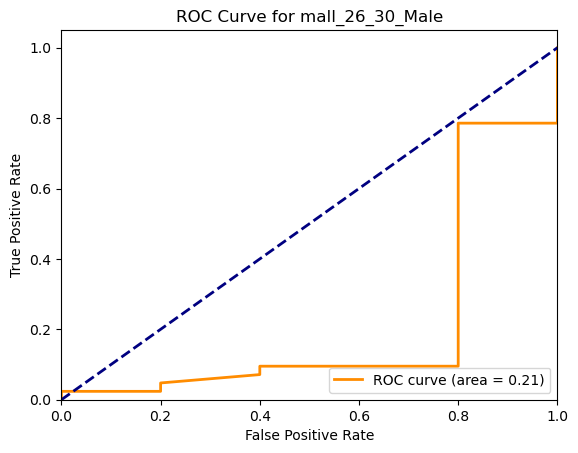

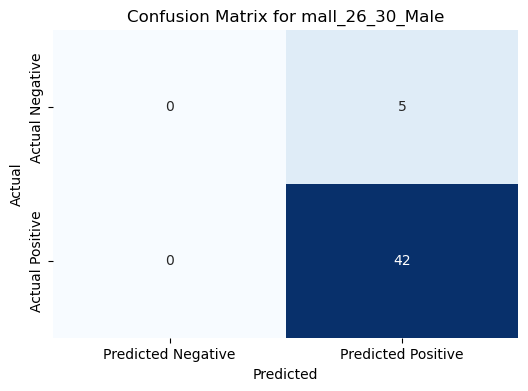

In [143]:
metrics_distilroberta_test, results_distilroberta_test = evaluate_model_by_group(X_test_distilroberta,
                                                                                             y_test,
                                                                                             'text_distilroberta', 
                                                                                             target_group_test,
                                                                                             model_distilrobertaC,
                                                                                             k=20)


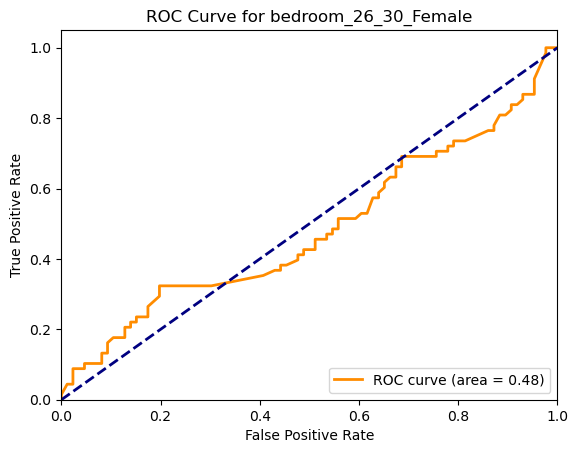

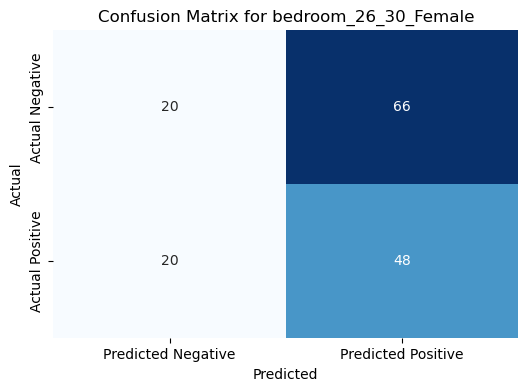

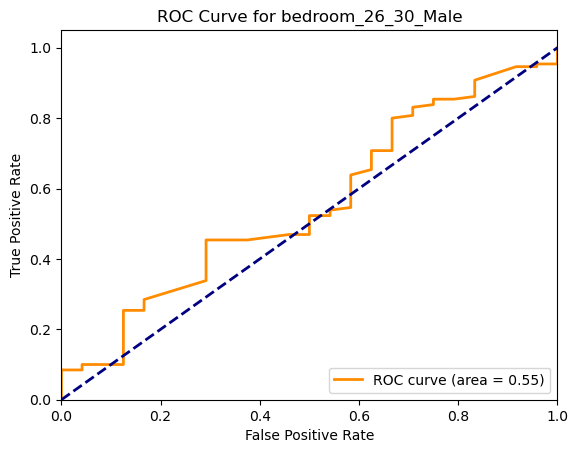

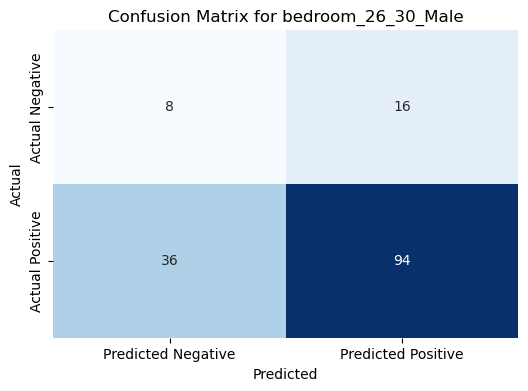

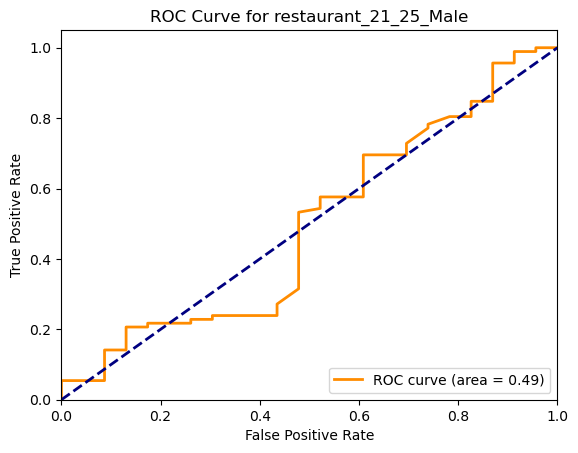

...

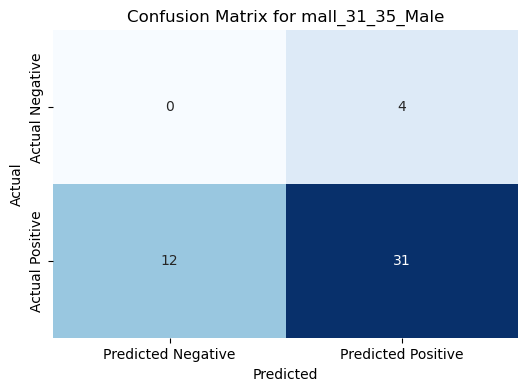

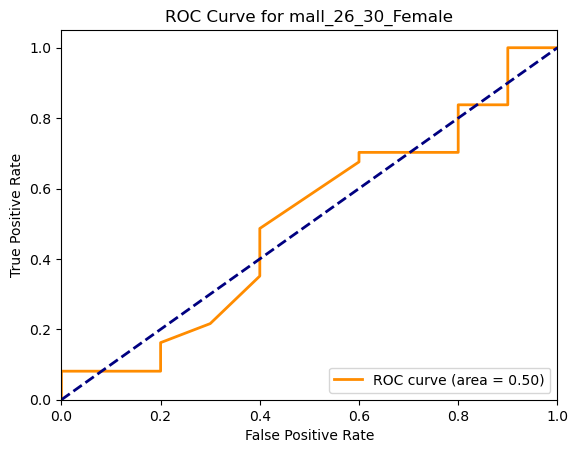

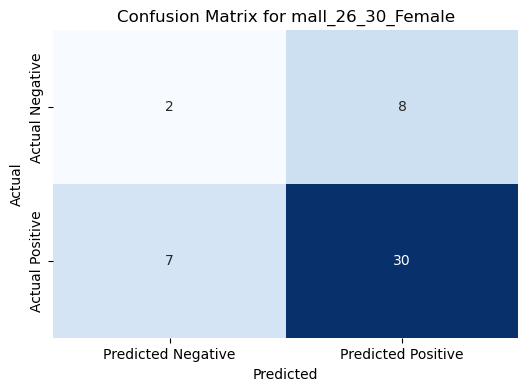

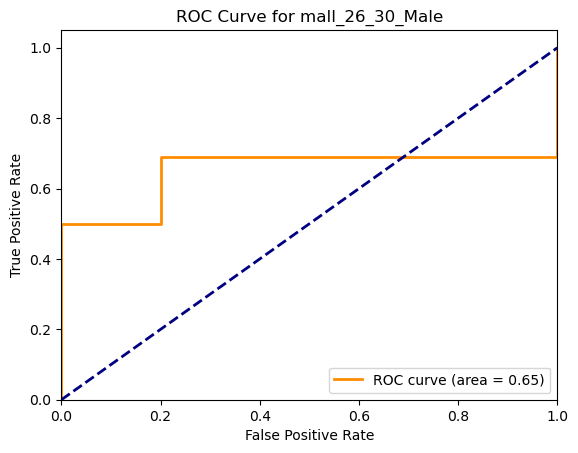

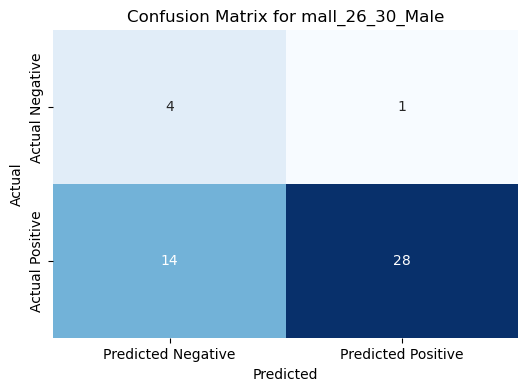

In [99]:
metrics_distilroberta_mitch_test, results_distilroberta_mitch_test = evaluate_model_by_group(X_test_distilroberta_mitch,
                                                                                             y_test,
                                                                                             'text_distilroberta_mitch', 
                                                                                             target_group_test,
                                                                                             model_distilroberta_mitchC,
                                                                                             k=20)


# Merge All the results for Results section in disertation

In [103]:

merged_df_1_2 = pd.merge(metrics_roberta_test, metrics_distilroberta_test, on='target_group', how='inner')

# Now merge the result with df3 on the same key
final_merged_df = pd.merge(merged_df_1_2, metrics_distilroberta_mitch_test, on='target_group', how='inner')
sorted_metrics = final_merged_df.sort_values(by='target_group', ascending=True)

In [104]:
sorted_metrics.to_excel('slda_test_result.xlsx', index=False)

# Results Reproducibility

In [149]:
import pickle
s = pickle.dumps(model_distilroberta_mitchC)
with open('slda_model_distilroberta_mitchC.pkl', 'wb') as f:
    f.write(s)

In [150]:
import pickle
s = pickle.dumps(model_distilrobertaC)
with open('slda_model_distilrobertaC.pkl', 'wb') as f:
    f.write(s)

In [151]:
import pickle
s = pickle.dumps(model_roberta3)
with open('slda_model_roberta3.pkl', 'wb') as f:
    f.write(s)